In [1]:
# Libraries
import pandas as pd
import numpy as np

# CPU Cores & System
import os
import sys
import psutil

if os.getcwd().endswith('notebooks'):
    %cd ..

# Scipy
from scipy.stats import (
    chi2_contingency,
    ks_2samp, spearmanr
)

# Viz libraries
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib inline

# Plotting options
mpl.style.use('ggplot')
sns.set(style='whitegrid')

# Import warnings
import warnings
warnings.filterwarnings('ignore')

# Pandas set_option
pd.set_option('display.max_columns', None)

# Cohesive palette (seaborn deep)
C_BLUE, C_RED, C_ORANGE, C_GREEN = '#4C72B0', '#C44E52', '#DD8452', '#55A868'
C_GRAY = '#7f7f7f'
TARGET_COLORS = {0: C_BLUE, 1: C_RED, '0': C_BLUE, '1': C_RED}  # 0 = good, 1 = bad


/home/gontommuhammad/credit_risk_modeling


<br>

---
# **Modeling Workflow for Credit Risk case**

> **Scope note:** this notebook is *exploratory only*. All transformations
> (target definition, performance window, feature drops, WoE/binning probes)
> are re-derived for analysis and are **not persisted**: the canonical,
> reproducible preparation pipeline lives in
> `2_Preparation_Preprocessing.ipynb`, which produces the artifacts consumed
> by notebooks 3 and 4.
>
> **How to read this notebook:** each section opens with a *business
> question* (Q1–Q5). Sections answer the question through analysis; §4.0
> collects every finding in one place for stakeholders.

## **1.0. Data Gathering and Understanding**:
> 1.1. **Import Data while Handling Duplicate** <br>
> 1.2. **Data Dictionary** <br>
> 1.3. **Handling Target Features**: *Q1: what is BAD, and when is it knowable?* <br>

## **2.0. Exploratory Data Analysis: Data Wrangling & Cleaning**:
> 2.1. **Data Type Check**: *Q3a: distributions, tails, engineered ratios* <br>
> 2.2. **Split Numerical and Categorical Data** <br>
> 2.3. **Numerical Data Distribution and Outlier Checking** <br>
> 2.4. **Categorical Features Analysis and Anomaly Review**: *Q4: do categoricals differentiate risk?* <br>

## **3.0. Business Understanding and Modeling Objectives**:
> 3.1. **Potential Data Leakage and Dropping Feature**: *Q2: clean, consistent, leakage-free?* <br>
> 3.2. **Feature Selection**: *Q3: which features carry independent signal?* <br>

## **4.0. Synthesis: Key Findings & Customer Segmentation**:
> 4.1. **Key Findings: Business Answers (Q1–Q5)** <br>
> 4.2. **Rule-Based Risk Segments (term x DTI)** <br>
> 4.3. **Dashboard Preview: Interactive (Plotly)** <br>


<br>

---
# **1.0. Data Gathering and Understanding**:

<br>

## **1.1. Import Data while Handling Duplicate**:

In [2]:
from src.utils import importData

# Define data path
data_path = 'data/raw/loan_data_2007_2014.csv'

df = importData(data_path)

Origin Data Shape: (466285, 75) - (# Observation, # Column)
Duplicates dropped: 0; Final shape: (466285, 75)


In [3]:
df.head()

,Unnamed: 0,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
0,0,1077501,1296599,5000,5000,4975.0,36 months,10.65,162.87,B,B2,NaN,10+ years,RENT,24000.0,Verified,Dec-11,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/22/11 > I need to upgra...,credit_card,Computer,860xx,AZ,27.65,0.0,Jan-85,1.0,NaN,NaN,3.0,0.0,13648,83.7,9.0,f,0.0,0.0,5861.071414,5831.78,5000.00,861.07,0.00,0.00,0.00,Jan-15,171.62,NaN,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1077430,1314167,2500,2500,2500.0,60 months,15.27,59.83,C,C4,Ryder,< 1 year,RENT,30000.0,Source Verified,Dec-11,Charged Off,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/22/11 > I plan to use t...,car,bike,309xx,GA,1.00,0.0,Apr-99,5.0,NaN,NaN,3.0,0.0,1687,9.4,4.0,f,0.0,0.0,1008.710000,1008.71,456.46,435.17,0.00,117.08,1.11,Apr-13,119.66,NaN,Sep-13,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,1077175,1313524,2400,2400,2400.0,36 months,15.96,84.33,C,C5,NaN,10+ years,RENT,12252.0,Not Verified,Dec-11,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,NaN,small_business,real estate business,606xx,IL,8.72,0.0,Nov-01,2.0,NaN,NaN,2.0,0.0,2956,98.5,10.0,f,0.0,0.0,3003.653644,3003.65,2400.00,603.65,0.00,0.00,0.00,Jun-14,649.91,NaN,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,1076863,1277178,10000,10000,10000.0,36 months,13.49,339.31,C,C1,AIR RESOURCES BOARD,10+ years,RENT,49200.0,Source Verified,Dec-11,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/21/11 > to pay for prop...,other,personel,917xx,CA,20.00,0.0,Feb-96,1.0,35.0,NaN,10.0,0.0,5598,21.0,37.0,f,0.0,0.0,12226.302210,12226.30,10000.00,2209.33,16.97,0.00,0.00,Jan-15,357.48,NaN,Jan-15,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,1075358,1311748,3000,3000,3000.0,60 months,12.69,67.79,B,B5,University Medical Group,1 year,RENT,80000.0,Source Verified,Dec-11,Current,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/21/11 > I plan on combi...,other,Personal,972xx,OR,17.94,0.0,Jan-96,0.0,38.0,NaN,15.0,0.0,27783,53.9,38.0,f,766.9,766.9,3242.170000,3242.17,2233.10,1009.07,0.00,0.00,0.00,Jan-16,67.79,Feb-16,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


---
## **1.2. Data Dictionary of Loan Data - Credit Risk**:

| Feature Name                   | Description                            |
|--------------------------------|----------------------------------------|
| acc_now_delinq | The number of accounts on which the borrower is now delinquent. |
| addr_state | The state provided by the borrower in the loan application. |
| all_util | Balance to credit limit on all trades. |
| annual_inc | The self-reported annual income provided by the borrower during registration. |
| annual_inc_joint | The combined self-reported annual income provided by the co-borrowers during registration. | 
| application_type | Indicates whether the loan is an individual application or a joint application with two co-borrowers. |
| collection_recovery_fee | post charge off collection fee. |
| collections_12_mths_ex_med | Number of collections in 12 months excluding medical collections. |
| delinq_2yrs | The number of 30+ days past-due incidences of delinquency in the borrower(s) credit file for the past 2 years. |
| desc | Loan description provided by the borrower |
| dti | - |
| dti_joint | A ratio calculated using the co-borrowers total monthly payments on the total debt obligations, excluding mortgages and the requested LC loan, divided by the co-borrower(s) combined self-reported monthly income. |
| earliest_cr_line | The month the borrower(s) earliest reported credit line was opened. |
| emp_length | Employment length in years. Possible values are between 0 and 10 where 0 means less than one year and 10 means ten or more years. |
| emp_title | The job title supplied by the Borrower when applying for the loan. |
| funded_amnt | The total amount committed to that loan at that point in time. |
| funded_amnt_inv | - |
| grade | LC assigned loan grade. |
| home_ownership | The home ownership status provided by the borrower during registration. Our values are: RENT, OWN, MORTGAGE, OTHER. |
| id | A unique LC assigned ID for the loan listing. |
| il_util | Ratio of total current balance to high credit/credit limit on all install acct. |
| initial_list_status | The initial listing status of the loan. Possible values are – Whole, Fractional. |
| inq_fi | Number of personal finance inquiries. |
| inq_last_12m | Number of credit inquiries in past 12 months. |
| inq_last_6mths | The number of inquiries in past 6 months (excluding auto and mortgage inquiries). |
| installment  | The monthly payment owed by the borrower if the loan originates. |
| int_rate | Indicates if income was verified by LC, not verified, or if the income source was verified. |
| issue_d | The month which the loan was funded. |
| last_credit_pull_d | - |
| last_pymnt_amnt | Last total payment amount received. |
| last_pymnt_d | Last month payment was received. |
| loan_amnt |  |
| loan_status | Current status of the loan. |
| max_bal_bc | Maximum current balance owed on all revolving accounts. |
| member_id | A unique LC assigned Id for the borrower member. |
| mths_since_last_delinq | The number of months since the borrower's last delinquency. |
| mths_since_last_major_derog | Months since most recent 90-day or worse rating. |
| mths_since_last_record | The number of months since the last public record. |
| mths_since_rcnt_il | Months since most recent installment accounts opened. |
| next_pymnt_d | Next scheduled payment date. |
| open_acc | The number of open credit lines in the borrower's credit file. |
| open_acc_6m | Number of open trades in last 6 months. |
| open_il_12m | Number of installment accounts opened in past 12 months. |
| open_il_24m | Number of installment accounts opened in past 24 months. |
| open_il_6m | Number of installment accounts opened in past 6 months. |
| open_rv_12m | Number of revolving trades opened in past 12 months. |
| open_rv_24m | Number of revolving trades opened in past 24 months. |
| out_prncp | Remaining outstanding principal for total amount funded. |
| out_prncp_inv | Remaining outstanding principal for portion of total amount funded by investors. |
| policy_code | publicly available policy_code=1, new products not publicly available policy_code=2|
| pub_rec | Number of derogatory public records. |
| purpose | A category provided by the borrower for the loan request. |
| pymnt_plan | - |
| recoveries | Indicates if a payment plan has been put in place for the loan. |
| revol_bal | Total credit revolving balance. |
| revol_util | Revolving line utilization rate, or the amount of credit the borrower is using relative to all available revolving credit. |
| sub_grade | LC assigned loan subgrade. |
| term | The number of payments on the loan. Values are in months and can be either 36 or 60. |
| title | The loan title provided by the borrower. |
| tot_coll_amt | Total collection amounts ever owed. |
| tot_cur_bal | Total current balance of all accounts. |
| total_acc | The total number of credit lines currently in the borrower's credit file. |
| total_bal_il | Total current balance of all installment accounts. |
| total_cu_tl | Number of finance trades. |
| total_pymnt | Payments received to date for total amount funded. |
| total_pymnt_inv | Payments received to date for portion of total amount funded by investors. |
| total_rec_int | Interest received to date. |
| total_rec_late_fee | Late fees received to date. |
| total_rec_prncp | Principal received to date. |
| total_rev_hi_lim | Total revolving high credit/credit limit. |
| url | URL for the LC page with listing data. |
| verification_status | - |
| verification_status_joint | Indicates if the co-borrowers' joint income was verified by LC, not verified, or if the income source was verified.|
| zip_code | The first 3 numbers of the zip code provided by the borrower in the loan application. |

*Employer Title replaces Employer Name for all loans listed after 9/23/2013

<br>

Sort columns alphabetically:

In [4]:
df = df[sorted(df.columns)]

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 466285 entries, 0 to 466284
Data columns (total 75 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Unnamed: 0                   466285 non-null  int64  
 1   acc_now_delinq               466256 non-null  float64
 2   addr_state                   466285 non-null  str    
 3   all_util                     0 non-null       float64
 4   annual_inc                   466281 non-null  float64
 5   annual_inc_joint             0 non-null       float64
 6   application_type             466285 non-null  str    
 7   collection_recovery_fee      466285 non-null  float64
 8   collections_12_mths_ex_med   466140 non-null  float64
 9   delinq_2yrs                  466256 non-null  float64
 10  desc                         125981 non-null  str    
 11  dti                          466285 non-null  float64
 12  dti_joint                    0 non-null       float64
 13  earliest_c

In [5]:
df = df.set_index('member_id')

# Check if the index is unique
print(f"Is the index unique? {df.index.is_unique}")
print(f"Data shape: {df.shape}")

df_dupes = df[df.index.duplicated(keep=False)]
df_dupes

Is the index unique? True
Data shape: (466285, 74)


,Unnamed: 0,acc_now_delinq,addr_state,all_util,annual_inc,annual_inc_joint,application_type,collection_recovery_fee,collections_12_mths_ex_med,delinq_2yrs,desc,dti,dti_joint,earliest_cr_line,emp_length,emp_title,funded_amnt,funded_amnt_inv,grade,home_ownership,id,il_util,initial_list_status,inq_fi,inq_last_12m,inq_last_6mths,installment,int_rate,issue_d,last_credit_pull_d,last_pymnt_amnt,last_pymnt_d,loan_amnt,loan_status,max_bal_bc,mths_since_last_delinq,mths_since_last_major_derog,mths_since_last_record,mths_since_rcnt_il,next_pymnt_d,open_acc,open_acc_6m,open_il_12m,open_il_24m,open_il_6m,open_rv_12m,open_rv_24m,out_prncp,out_prncp_inv,policy_code,pub_rec,purpose,pymnt_plan,recoveries,revol_bal,revol_util,sub_grade,term,title,tot_coll_amt,tot_cur_bal,total_acc,total_bal_il,total_cu_tl,total_pymnt,total_pymnt_inv,total_rec_int,total_rec_late_fee,total_rec_prncp,total_rev_hi_lim,url,verification_status,verification_status_joint,zip_code
member_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,


### Business question Q1: **What counts as a "bad" loan, and when is the outcome actually knowable?**

Before any modeling, the target must be defined so that labels are *final* at prediction time.
This section defines GOOD vs BAD status mappings and the **performance window**: how many
months a loan must survive before a "still-current" loan can be confidently labeled GOOD.
Anything less leaks future information into the label.

---
## **1.3. Handling Target Features**: <br>

`loan_status` is the target feature:

In [6]:
df['loan_status'].unique()

<ArrowStringArray>
[                                         'Fully Paid',
                                         'Charged Off',
                                             'Current',
                                             'Default',
                                  'Late (31-120 days)',
                                     'In Grace Period',
                                   'Late (16-30 days)',
  'Does not meet the credit policy. Status:Fully Paid',
 'Does not meet the credit policy. Status:Charged Off']
Length: 9, dtype: str

In [7]:
df['loan_status'].value_counts()

loan_status
Current                                                224226
Fully Paid                                             184739
Charged Off                                             42475
Late (31-120 days)                                       6900
In Grace Period                                          3146
Does not meet the credit policy. Status:Fully Paid       1988
Late (16-30 days)                                        1218
Default                                                   832
Does not meet the credit policy. Status:Charged Off       761
Name: count, dtype: int64

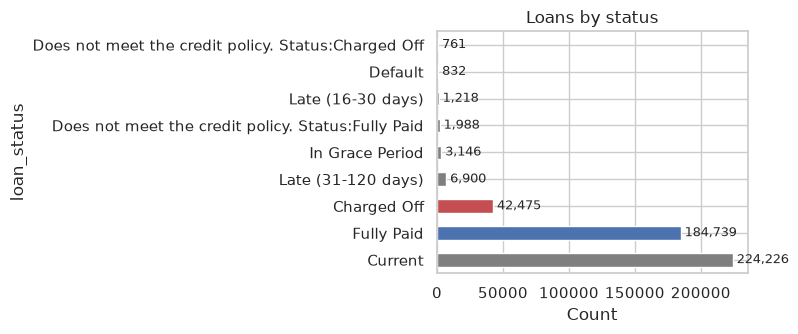

In [8]:
# loan_status distribution
_status = df['loan_status'].value_counts()
_BAD_STATUS = {'Charged Off', 'Default'}
_colors = [C_RED if s in _BAD_STATUS else (C_BLUE if s == 'Fully Paid' else C_GRAY)
           for s in _status.index]

fig, ax = plt.subplots(figsize=(8, 3.5))
_status.plot.barh(ax=ax, color=_colors)
ax.set_title('Loans by status')
ax.set_xlabel('Count')
for i, n in enumerate(_status.values):
    ax.text(n, i, f' {n:,}', va='center', fontsize=9)
plt.tight_layout()
plt.show()


<br>

### Performance Window:

In [9]:
date_columns = ['issue_d', 'earliest_cr_line', 'last_pymnt_d', 'last_credit_pull_d']

from src.utils import missing_summary
missing_summary(df[date_columns])

,Missing Values,Percentage,Total length
earliest_cr_line,29,0.01,466285
last_pymnt_d,376,0.08,466285
last_credit_pull_d,42,0.01,466285


In [10]:
df = df.dropna(subset=date_columns)

print(f"Fixed date format and year anomalies...")
# Convert to datetime & fix "future" year simultaneously (Vectorization)
for col in date_columns:
    # Let Pandas guess the %b-%y format (e.g., Jan-14, Dec-68)
    df[col] = pd.to_datetime(df[col], format='%b-%y', errors='coerce')
    
    # Correction if the year jumps into the future (beyond the anchor year 2016)
    # Pandas automatically detects the year '68' as '2068', we change it to '1968'
    future_mask = df[col].dt.year > 2016
    df.loc[future_mask, col] = df.loc[future_mask, col] - pd.DateOffset(years=100)

print(f"Date format successfully corrected!")

Fixed date format and year anomalies...
Date format successfully corrected!


In [11]:
# Filter mature data first SPECIFICALLY to find objective M values
df_mature = df[df['issue_d'].dt.year.isin([2011, 2012])]

from src.performance_window import (
    compute_time_to_bad_distribution, 
    recommend_performance_window, 
    apply_performance_window_filter,
    eligibility_funnel_report,
    bad_rate_by_vintage,
    safe_horizon_cutoff,
    truncate_to_safe_horizon
)
from typing import List
DEFAULT_BAD_STATUSES: List[str] = [
    'Charged Off', 'Default', 'Late (31-120 days)', 
    'Does not meet the credit policy. Status:Charged Off',
]

# Determine M from granular data.
tt_bad = compute_time_to_bad_distribution(
    df_mature, 
    bad_statuses=DEFAULT_BAD_STATUSES,
    issue_col='issue_d', 
    last_pymnt_col='last_pymnt_d', 
    status_col='loan_status'
)

print(tt_bad.describe())
print(f"---"*18)
print(tt_bad.quantile([0.5, 0.75, 0.9, 0.95]))

M = recommend_performance_window(tt_bad, coverage=0.90)   # starting from the 90th percentile
print("M selected:", M, "month")
print(f"---"*18)

# Apply filter -- `snapshot_date` MUST be the actual extraction date of LendingClub dataset 
# (not issue_d.max() from any split)
snapshot_date = pd.Timestamp("2016-01-01")
result = apply_performance_window_filter(
    df, 
    snapshot_date=snapshot_date, 
    M=M
)
display(eligibility_funnel_report(result))

# Cut the safe horizon
df = truncate_to_safe_horizon(
    result.df, 
    snapshot_date=snapshot_date, 
    M=M
)
# Verification: the bad rate per vintage should now be relatively flat, not rising smoothly as before.
print(f"---"*18)
display(bad_rate_by_vintage(df))

count    11495.000000
mean        18.315355
std         10.438172
min          1.000000
25%         10.000000
50%         17.000000
75%         26.000000
max         58.000000
Name: months_to_bad, dtype: float64
------------------------------------------------------
0.50    17.0
0.75    26.0
0.90    33.0
0.95    36.0
Name: months_to_bad, dtype: float64
M selected: 33 month
------------------------------------------------------


,stage,count,pct_of_input
0,Input population,465839,100.00
1,Excluded: immature (age < M),207878,44.62
2,Excluded: indeterminate status,4364,0.94
3,Eligible (modeling population),253597,54.44


------------------------------------------------------


,vintage,count,bad_rate
0,2007Q2,3,0.000000
1,2007Q3,181,0.220994
2,2007Q4,388,0.296392
3,2008Q1,1011,0.229476
4,2008Q2,498,0.220884
5,2008Q3,298,0.174497
6,2008Q4,583,0.169811
7,2009Q1,895,0.137430
8,2009Q2,1094,0.140768
9,2009Q3,1361,0.125643


In [12]:
df.loan_status.value_counts()

loan_status
Fully Paid                                             85710
Charged Off                                            16410
Current                                                12677
Does not meet the credit policy. Status:Fully Paid      1961
Does not meet the credit policy. Status:Charged Off      746
Late (31-120 days)                                       501
Default                                                   61
Name: count, dtype: int64

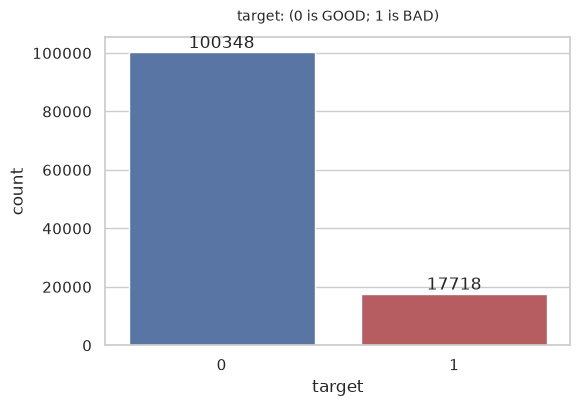

In [13]:
# Target Distribution Visualization
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='target', hue='target', palette=TARGET_COLORS, ax=ax, legend=False)
    
# Add label numbers above each bar
for container in ax.containers: 
    ax.bar_label(container, fmt='%d')
        
ax.set_title('target: (0 is GOOD; 1 is BAD)', fontsize=10, pad=12)
    
# Save figure before show
fig.savefig('reports/figures/Target_Feature_Distribution.png', dpi=150, bbox_inches='tight')

# Show
plt.show()

In [14]:
df = df.drop(columns=['loan_status'])

<br>

---
# **2.0. Exploratory Data Analysis: Data Wrangling & Cleaning**:

### Business question Q2: **Is the data clean, consistent, and free of leakage?**

Every feature examined below is judged on three criteria: availability at application
time (no post-origination leakage), data quality (missingness, impossible values,
zero-variance), and univariate signal. Features failing any criterion are dropped
*with a documented reason*: the drop list is the audit trail for model governance.

<br>

**Missing Value Check**:

In [15]:
from src.utils import missing_summary
missing_summary(df)

,Missing Values,Percentage,Total length
all_util,118066,100.00,118066
annual_inc_joint,118066,100.00,118066
collections_12_mths_ex_med,115,0.10,118066
desc,44428,37.63,118066
dti_joint,118066,100.00,118066
emp_length,3814,3.23,118066
emp_title,7016,5.94,118066
il_util,118066,100.00,118066
inq_fi,118066,100.00,118066
inq_last_12m,118066,100.00,118066


<br>

**Drop `NaN` values that add up to 100% and unnecessary features**:

In [16]:
# list of features that have 100% NaN value
null_100 = df.columns[df.isnull().mean() == 1.0]
print(f"Columns with 100% null values: {null_100}")

# Perform feature removal
df = df.drop(columns=null_100)

print(f"\nAre there still any columns with 100% NaN? {(df.isnull().mean() == 1.0).any()}")

Columns with 100% null values: Index(['all_util', 'annual_inc_joint', 'dti_joint', 'il_util', 'inq_fi',
       'inq_last_12m', 'max_bal_bc', 'mths_since_rcnt_il', 'open_acc_6m',
       'open_il_12m', 'open_il_24m', 'open_il_6m', 'open_rv_12m',
       'open_rv_24m', 'total_bal_il', 'total_cu_tl',
       'verification_status_joint'],
      dtype='str')

Are there still any columns with 100% NaN? False


In [17]:
# List of unimportant features for modeling
unimportant_features = [
    'Unnamed: 0', 'addr_state', 'desc', 'emp_title', 'id', 'url', 'zip_code', 'next_pymnt_d',
]

# Perform feature removal
df = df.drop(columns=unimportant_features)

print(f"Still there? {[col for col in unimportant_features if col in df.columns]}")

Still there? []


In [18]:
# Calculates `payment_time` in months
# EDA-only diagnostic (post-origination info) -- dropped from df before modeling; never a feature.
# 'last_pymnt_d': Last month payment was received.
# 'issue_d': The month which the loan was funded.
df['pymnt_time_month'] = (
    (df['last_pymnt_d'].dt.year - df['issue_d'].dt.year) * 12 + \
    (df['last_pymnt_d'].dt.month - df['issue_d'].dt.month)
).fillna(0).astype(int)

# Calculates `credit_history_age_` in months
# 'earliest_cr_line': The first month the user has a credit history.
# 'issue_d': The month the loan was approved/issued.
df['credit_history_age_month'] = (
    (df['issue_d'].dt.year - df['earliest_cr_line'].dt.year) * 12 + \
    (df['issue_d'].dt.month - df['earliest_cr_line'].dt.month)
).fillna(0).astype(int)


# # In production, 'issue_d' is replaced with today's date when the user clicks "Apply"
# todays_date = pd.Timestamp.now()

# credit_history_age_month = (
#     (todays_date.year - earliest_cr_line.year) * 12 + \
#     (todays_date.month - earliest_cr_line.month)
# )

# Display the final resulting DataFrame
df[['issue_d', 'last_pymnt_d', 'earliest_cr_line', 'last_credit_pull_d', 'pymnt_time_month', 'credit_history_age_month', 'target']]

,issue_d,last_pymnt_d,earliest_cr_line,last_credit_pull_d,pymnt_time_month,credit_history_age_month,target
member_id,,,,,,,
1296599,2011-12-01,2015-01-01,1985-01-01,2016-01-01,37,323,0
1314167,2011-12-01,2013-04-01,1999-04-01,2013-09-01,16,152,1
1313524,2011-12-01,2014-06-01,2001-11-01,2016-01-01,30,121,0
1277178,2011-12-01,2015-01-01,1996-02-01,2015-01-01,37,190,0
1311748,2011-12-01,2016-01-01,1996-01-01,2016-01-01,49,191,0
...,...,...,...,...,...,...,...
1294262,2012-01-01,2014-11-01,1988-10-01,2015-11-01,34,279,0
1291010,2012-01-01,2015-01-01,2004-01-01,2014-12-01,36,96,0
1290827,2012-01-01,2014-12-01,2000-09-01,2014-12-01,35,136,0


In [19]:
# e.g. for the date_columns
for col in date_columns:
    print(f"Column: {col}")
    print(f"Min :", df[col].min())
    print(f"Max :", df[col].max())
    print(f"Count :", df[col].notna().sum())
    print()

Column: issue_d
Min : 2007-06-01 00:00:00
Max : 2013-03-01 00:00:00
Count : 118066

Column: earliest_cr_line
Min : 1946-01-01 00:00:00
Max : 2010-01-01 00:00:00
Count : 118066

Column: last_pymnt_d
Min : 2007-12-01 00:00:00
Max : 2016-01-01 00:00:00
Count : 118066

Column: last_credit_pull_d
Min : 2007-05-01 00:00:00
Max : 2016-01-01 00:00:00
Count : 118066



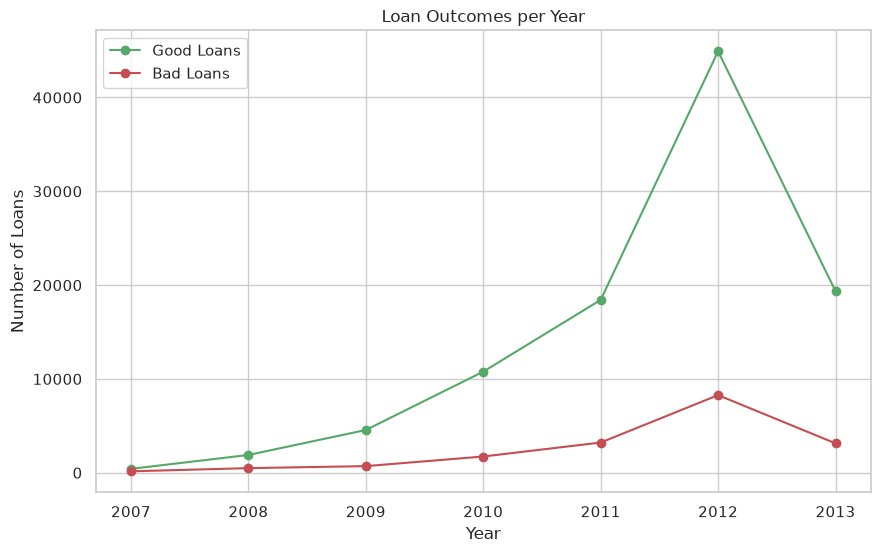

In [20]:
good_loan = df[df['target'] == 0]
bad_loan  = df[df['target'] == 1]

good_loan['year'] = good_loan['issue_d'].dt.year
bad_loan['year']  = bad_loan['issue_d'].dt.year

achievements_per_year = good_loan.groupby('year').size()
failures_per_year = bad_loan.groupby('year').size()

# Visualisasi
plt.figure(figsize=(10,6))
plt.plot(achievements_per_year.index, achievements_per_year.values, 
         marker='o', color='g', label='Good Loans')
plt.plot(failures_per_year.index, failures_per_year.values, 
         marker='o', color='r', label='Bad Loans')

plt.title(f'Loan Outcomes per Year')
plt.xlabel(f'Year')
plt.ylabel(f'Number of Loans')
plt.legend()
plt.grid(True)
plt.show()

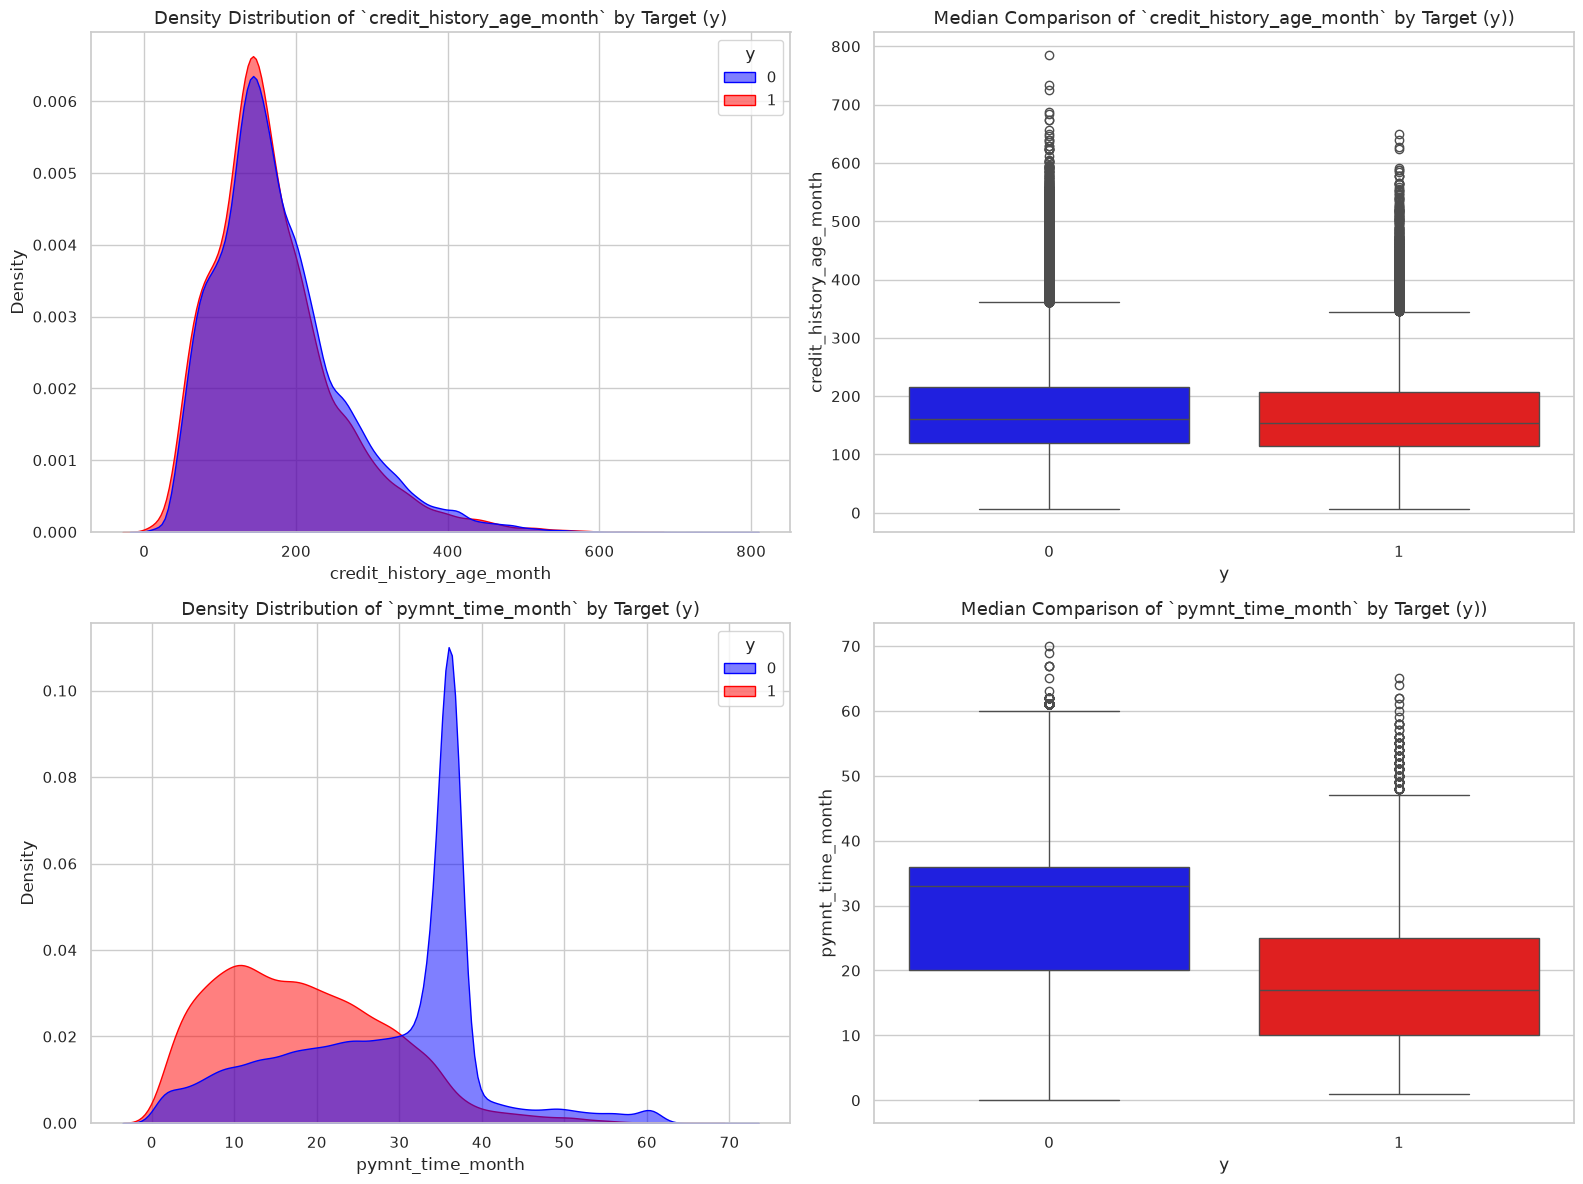

In [21]:
# List of columns to be visualized
cols = ['credit_history_age_month', 'pymnt_time_month']

from src.utils import plot_numeric_distributions

plot_numeric_distributions(dataframe=df[cols], target_col=df['target'])

In [22]:
# Create credit age categories (in years)
df['credit_age_years'] = df['credit_history_age_month'] / 12

def group_age(years):
    if years < 5: return 'less_5'
    elif years <= 15: return '5_15'
    else: return 'greater_15'

df['credit_age_group'] = df['credit_age_years'].apply(group_age)

# Check the default ratio (y=1) in each group
df.groupby('credit_age_group')['target'].mean().sort_values(ascending=False)

credit_age_group
less_5        0.179581
5_15          0.156157
greater_15    0.138169
Name: target, dtype: float64

In [23]:
df[['credit_age_group', 'credit_age_years', 'credit_history_age_month']]

,credit_age_group,credit_age_years,credit_history_age_month
member_id,,,
1296599,greater_15,26.916667,323
1314167,5_15,12.666667,152
1313524,5_15,10.083333,121
1277178,greater_15,15.833333,190
1311748,greater_15,15.916667,191
...,...,...,...
1294262,greater_15,23.250000,279
1291010,5_15,8.000000,96
1290827,5_15,11.333333,136


### Business question Q3: **Which features carry independent, directionally-stable signal?**

Univariate screens (WoE/IV, VIF, correlation, information gain) identify which attributes
genuinely separate GOOD from BAD *before* multivariate modeling. The survivors become
candidates for `features_to_selected` in `2_Preparation_Preprocessing.ipynb`.

<br>

**WoE (Weight of Evidence) Implementation for Feature Selection**:

In [24]:
def eda_profile(df, col, target='target'):
    """Profile one feature vs the target: distribution summary, counts,
    bad rate, chi-square test, and a two-panel seaborn figure."""
    s = df[col]
    numeric = pd.api.types.is_numeric_dtype(s)
    if numeric:
        print(s.describe().round(3).to_string())
    else:
        print(s.value_counts().to_string())

    key = s
    if numeric and s.nunique() > 20:
        key = pd.qcut(s, q=10, duplicates='drop')
    ct = pd.crosstab(key, df[target])
    bad_rate = ct[1] / ct.sum(axis=1) * 100
    ranked = bad_rate.sort_values()

    print(f'\nCounts:\n{ct.to_string()}')
    print(f'\nBad rate (%):\n{ranked.round(2).to_string()}')
    if ct.shape[0] > 1 and ct.shape[1] > 1:
        chi2, p, dof, _ = chi2_contingency(ct)
        print(f'\nchi2={chi2:.2f}, p={p:.3g}, dof={dof}')

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    ranked.plot.barh(ax=axes[0], color=C_RED)
    axes[0].set_title(f'Bad rate by {col}')
    axes[0].set_xlabel('% of loans')
    for i, v in enumerate(ranked.values):
        axes[0].text(v + 0.3, i, f'{v:.1f}', va='center', fontsize=8)
    ct.sum(axis=1).loc[ranked.index].plot.barh(ax=axes[1], color=C_GRAY)
    axes[1].set_title(f'Loan count by {col}')
    plt.tight_layout()
    plt.show()
    return ct


In [25]:
# 1. Perform Automatic Binning (e.g. divide into 6 groups based on quantiles to balance the amount of data)
# We can also use manual bins if we want to customize
df['credit_age_bin'] = pd.qcut(df['credit_history_age_month'], q=6, duplicates='drop').astype(str)

# 2. Calculate the total of Good (y=0) and Bad (y=1) across the entire dataset
total_good = (df['target'] == 0).sum()
total_bad = (df['target'] == 1).sum()

# 3. Count the number of Good and Bad in each Bin
woe_df = df.groupby('credit_age_bin')['target'].agg(
    total_records='count',
    bad_counts='sum'
).reset_index()

df_good_counts = df[df['target'] == 0].groupby('credit_age_bin').size().reset_index(name='good_counts')
woe_df = pd.merge(woe_df, df_good_counts, on='credit_age_bin', how='left').fillna(0)

# 4. Calculate the % Good and % Bad Distribution
woe_df['dist_good'] = woe_df['good_counts'] / total_good
woe_df['dist_bad'] = woe_df['bad_counts'] / total_bad

# 5. Calculate WoE Value (add a very small value of 0.0001 to avoid dividing by zero/log zero)
woe_df['WoE'] = np.log((woe_df['dist_good'] + 1e-4) / (woe_df['dist_bad'] + 1e-4))

# 6. Calculate the Information Value (IV) at the same time to check the mathematical strength of the feature.
woe_df['IV_components'] = (woe_df['dist_good'] - woe_df['dist_bad']) * woe_df['WoE']
total_iv = woe_df['IV_components'].sum()

print(f"Total Information Value (IV) for this feature: {total_iv:.4f}")
print(f"\nWoE Reference Table per Group:")
print(woe_df[['credit_age_bin', 'good_counts', 'bad_counts', 'WoE']])

# 7. Mapping WoE values back to the main DataFrame for use by Logistic Regression (if results are good)
woe_map = dict(zip(woe_df['credit_age_bin'], woe_df['WoE']))
df['credit_history_age_woe'] = df['credit_age_bin'].map(woe_map)

Total Information Value (IV) for this feature: 0.0061

WoE Reference Table per Group:
   credit_age_bin  good_counts  bad_counts       WoE
0  (133.0, 159.0]        16687        3153 -0.067748
1  (159.0, 193.0]        16550        2900  0.007608
2  (193.0, 246.0]        16710        2749  0.070663
3  (246.0, 785.0]        17012        2619  0.136977
4   (5.999, 98.0]        16748        3191 -0.076075
5   (98.0, 133.0]        16641        3106 -0.055497


In [26]:
df.groupby('credit_age_group')['target'].mean().sort_values(ascending=False)

credit_age_group
less_5        0.179581
5_15          0.156157
greater_15    0.138169
Name: target, dtype: float64

credit_age_group
5_15          68002
greater_15    45676
less_5         4388

Counts:
target                0      1
credit_age_group              
5_15              57383  10619
greater_15        39365   6311
less_5             3600    788

Bad rate (%):
credit_age_group
greater_15    13.82
5_15          15.62
less_5        17.96

chi2=100.44, p=1.55e-22, dof=2


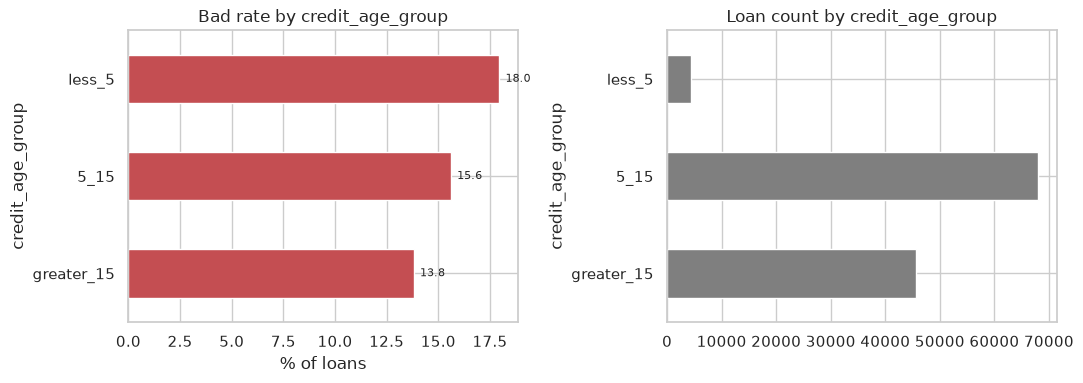

target,0,1
credit_age_group,,
5_15,57383,10619
greater_15,39365,6311
less_5,3600,788


In [27]:
eda_profile(df, 'credit_age_group')

In [28]:
df.drop(
    columns=[
        'credit_history_age_woe', 'credit_age_bin', 'pymnt_time_month',], inplace=True
)
set(['credit_history_age_woe', 'credit_age_bin', 'pymnt_time_month',]).intersection(df.columns)

set()

In [29]:
df['credit_age_group'] = df['credit_age_group'].astype('category')

<br>

---
### `application_type`: 
Indicates whether the loan is an individual application or a joint application with two co-borrowers.

In [30]:
df['application_type'].value_counts(normalize=True)

application_type
INDIVIDUAL    1.0
Name: proportion, dtype: float64

In [31]:
df.drop(columns=['application_type'], inplace=True)

<br>

---
### `purpose` and `title`:

In [32]:
df[['purpose', 'title']].sample(5)

,purpose,title
member_id,,
872392,debt_consolidation,Wind Dancing
658436,other,school loan
3768643,debt_consolidation,debt consolidation
1715376,debt_consolidation,home
1045355,debt_consolidation,Debt Consolidation Loan


purpose
debt_consolidation    64113
credit_card           21445
other                  8099
home_improvement       7180
major_purchase         4095
small_business         3607
car                    2698
wedding                1861
medical                1497
moving                 1097
house                   974
vacation                795
educational             419
renewable_energy        186

Counts:
target                  0      1
purpose                         
car                  2413    285
credit_card         18893   2552
debt_consolidation  53999  10114
educational           334     85
home_improvement     6285    895
house                 813    161
major_purchase       3663    432
medical              1244    253
moving                911    186
other                6675   1424
renewable_energy      150     36
small_business       2653    954
vacation              666    129
wedding              1649    212

Bad rate (%):
purpose
major_purchase        10.55
car         

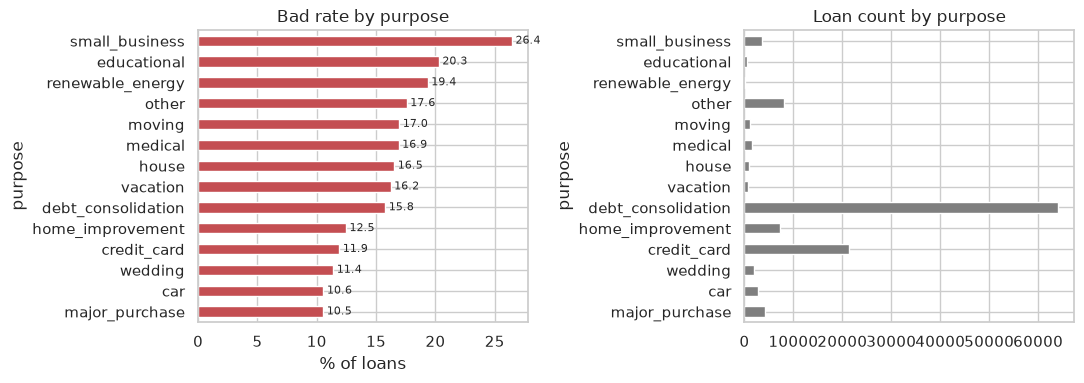

target,0,1
purpose,,
car,2413,285
credit_card,18893,2552
debt_consolidation,53999,10114
educational,334,85
home_improvement,6285,895
house,813,161
major_purchase,3663,432
medical,1244,253
moving,911,186


In [33]:
eda_profile(df, 'purpose')

In [34]:
# Validate the number of values on the feature before and after
before_other = df['purpose'].value_counts()['other']
added = df['purpose'].value_counts()['renewable_energy'] + df['purpose'].value_counts()['moving'] + \
        df['purpose'].value_counts()['vacation']

# Mapping category to 'other'
df['purpose'] = df['purpose'].replace({
    'renewable_energy': 'other',
    'moving': 'other',
    'vacation': 'other'
})

# validate counts before and after
after_other = df['purpose'].value_counts()['other']

print(f"Number of 'other' before:", before_other)
print(f"Additional amount (renewable_energy + moving + vacation):", added)
print(f"Number of 'other' after:", after_other)
print(f"Validation:", before_other + added == after_other)

Number of 'other' before: 8099
Additional amount (renewable_energy + moving + vacation): 2078
Number of 'other' after: 10177
Validation: True


In [35]:
df['purpose'] = df['purpose'].astype('category')

purpose
debt_consolidation    64113
credit_card           21445
other                 10177
home_improvement       7180
major_purchase         4095
small_business         3607
car                    2698
wedding                1861
medical                1497
house                   974
educational             419

Counts:
target                  0      1
purpose                         
car                  2413    285
credit_card         18893   2552
debt_consolidation  53999  10114
educational           334     85
home_improvement     6285    895
house                 813    161
major_purchase       3663    432
medical              1244    253
other                8402   1775
small_business       2653    954
wedding              1649    212

Bad rate (%):
purpose
major_purchase        10.55
car                   10.56
wedding               11.39
credit_card           11.90
home_improvement      12.47
debt_consolidation    15.78
house                 16.53
medical               16.90

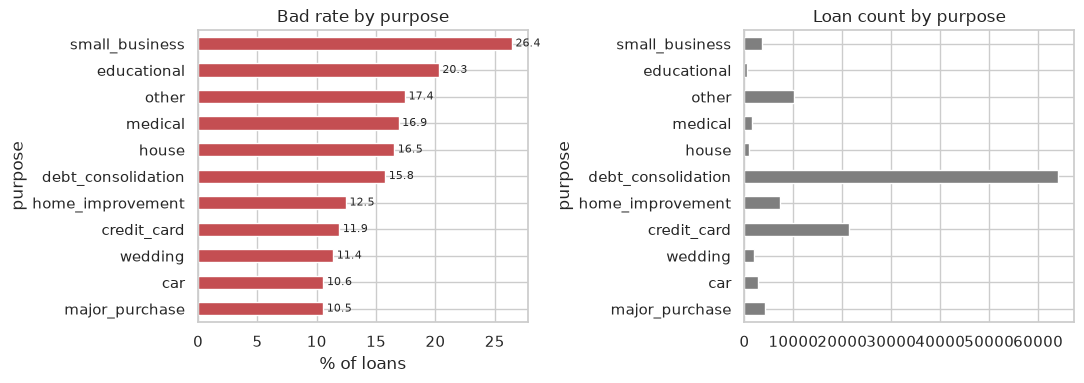

target,0,1
purpose,,
car,2413,285
credit_card,18893,2552
debt_consolidation,53999,10114
educational,334,85
home_improvement,6285,895
house,813,161
major_purchase,3663,432
medical,1244,253
other,8402,1775


In [36]:
eda_profile(df, 'purpose')

In [37]:
df['title'].describe()

count                 118051
unique                 40645
top       Debt Consolidation
freq                    8063
Name: title, dtype: object

* We will drop the `title` feature because it is high cardinal.

In [38]:
df.drop(columns=['title'], inplace=True)

<br>

---
### `sub_grade` and `grade`:

In [39]:
df[['grade', 'sub_grade']].sample(5)

,grade,sub_grade
member_id,,
4627436,B,B4
4437024,B,B4
1256202,C,C4
1545829,A,A3
431258,D,D5


grade
B    38878
C    27116
A    24329
D    16197
E     7654
F     3067
G      825

Counts:
target      0     1
grade              
A       22804  1525
B       34237  4641
C       22457  4659
D       12612  3585
E        5611  2043
F        2095   972
G         532   293

Bad rate (%):
grade
A     6.27
B    11.94
C    17.18
D    22.13
E    26.69
F    31.69
G    35.52

chi2=4250.18, p=0, dof=6


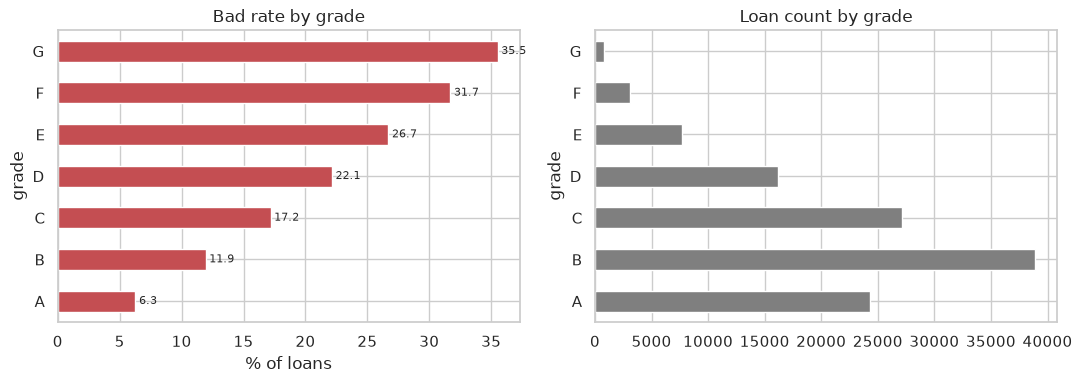

target,0,1
grade,,
A,22804,1525
B,34237,4641
C,22457,4659
D,12612,3585
E,5611,2043
F,2095,972
G,532,293


In [40]:
eda_profile(df, 'grade')


In [41]:
df['grade'] = df['grade'].astype('category')

<br>

---
### `policy_code`:

In [42]:
df['policy_code'].value_counts(normalize=True) * 100

policy_code
1    100.0
Name: proportion, dtype: float64

<br>

We drop **policy_code** (Zero Variance). <br> Unless something turns out otherwise in the future.

In [43]:
df.drop(columns=['policy_code'], inplace=True)

<br>

---
### `emp_length`:
Employment Length.

emp_length
10+ years    32127
2 years      11549
< 1 year     10666
3 years       9966
5 years       9756
4 years       8858
1 year        8518
6 years       7564
7 years       6221
8 years       4933
9 years       4094

Counts:
target          0     1
emp_length             
1 year       7297  1221
10+ years   27307  4820
2 years      9928  1621
3 years      8491  1475
4 years      7568  1290
5 years      8349  1407
6 years      6412  1152
7 years      5230   991
8 years      4172   761
9 years      3476   618
< 1 year     9063  1603

Bad rate (%):
emp_length
2 years      14.04
1 year       14.33
5 years      14.42
4 years      14.56
3 years      14.80
10+ years    15.00
< 1 year     15.03
9 years      15.10
6 years      15.23
8 years      15.43
7 years      15.93

chi2=18.82, p=0.0426, dof=10


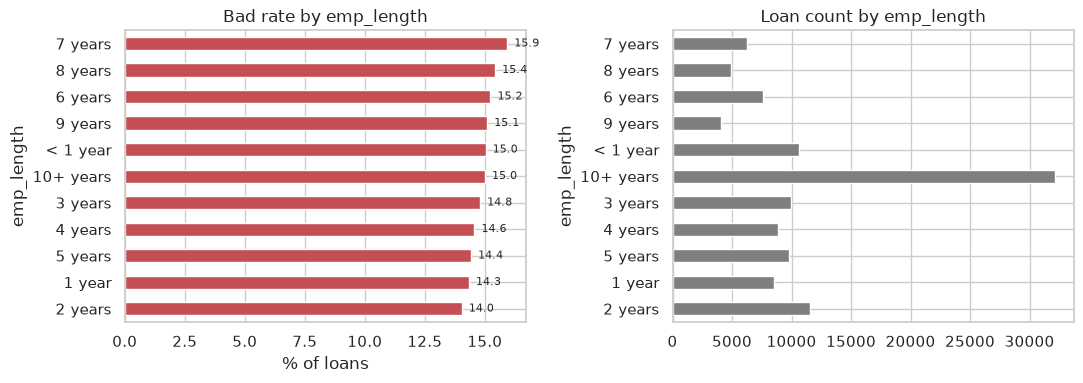

target,0,1
emp_length,,
1 year,7297,1221
10+ years,27307,4820
2 years,9928,1621
3 years,8491,1475
4 years,7568,1290
5 years,8349,1407
6 years,6412,1152
7 years,5230,991
8 years,4172,761


In [44]:
eda_profile(df, 'emp_length')

In [45]:
def process_emp_length(dataframe, col_name='emp_length'):
    import re
    """
    Clean the text, bin the values,
    and create a category for `np.nan`
    """
    df_processed = dataframe.copy()
    # 1. NUMBER EXTRACTION (Cleaning)
    # Change text like "< 1 year" to 0, "10+ years" to 10
    def extract_years(text):
        if pd.isna(text):
            return np.nan
        text = str(text)
        if '< 1' in text:
            return 0
        
        # Find all numbers in text
        nums = re.findall(r'\d+', text)
        return int(nums[0]) if nums else np.nan

    df_processed['emp_length_ordinal'] = df_processed[col_name].apply(extract_years)
    
    # 2. GROUP BINNING (pd.cut)
    # Define interval boundaries (bins) and group names (labels)
    # pd.cut rule: (lower_bound, upper_bound] -> exclusive lower bound, inclusive upper bound
    bins = [-1, 2, 5, 9, 100]  
    labels = ['New_Employee', 'Mid_Employee', 'Senior_Employee', 'Expert_Employee']
    
    # Mapping interval:
    # (-1, 2]   => 0, 1, 2 years (New)
    # (2, 5]    => 3, 4, 5 years (Mid)
    # (5, 9]    => 6, 7, 8, 9 years (Senior)
    # (9, 100]  => 10+ years (Expert)
    
    df_processed['emp_length_group'] = pd.cut(
        df_processed['emp_length_ordinal'], 
        bins=bins, 
        labels=labels
    )
    
    # We will create an 'No_Formal_Employee' category for `np.nan`
    df_processed['emp_length_group'] = df_processed['emp_length_group'].cat.add_categories(
        'No_Formal_Employee').fillna('No_Formal_Employee')

    return df_processed

df = process_emp_length(dataframe=df, col_name='emp_length')

In [46]:
df[['emp_length', 'emp_length_ordinal', 'emp_length_group']].sample(12)

,emp_length,emp_length_ordinal,emp_length_group
member_id,,,
2127600,10+ years,10.0,Expert_Employee
1631590,10+ years,10.0,Expert_Employee
1509462,10+ years,10.0,Expert_Employee
1758933,10+ years,10.0,Expert_Employee
4221584,2 years,2.0,New_Employee
971131,5 years,5.0,Mid_Employee
1404625,10+ years,10.0,Expert_Employee
1969817,3 years,3.0,Mid_Employee
2733757,4 years,4.0,Mid_Employee


In [47]:
df['emp_length_ordinal'].unique()

array([10.,  0.,  1.,  3.,  8.,  9.,  4.,  5.,  6.,  2.,  7., nan])

In [48]:
df.drop(columns=['emp_length'], inplace=True)

emp_length_group
Expert_Employee       32127
New_Employee          30733
Mid_Employee          28580
Senior_Employee       22812
No_Formal_Employee     3814

Counts:
target                  0     1
emp_length_group               
New_Employee        26288  4445
Mid_Employee        24408  4172
Senior_Employee     19290  3522
Expert_Employee     27307  4820
No_Formal_Employee   3055   759

Bad rate (%):
emp_length_group
New_Employee          14.46
Mid_Employee          14.60
Expert_Employee       15.00
Senior_Employee       15.44
No_Formal_Employee    19.90

chi2=85.82, p=1.02e-17, dof=4


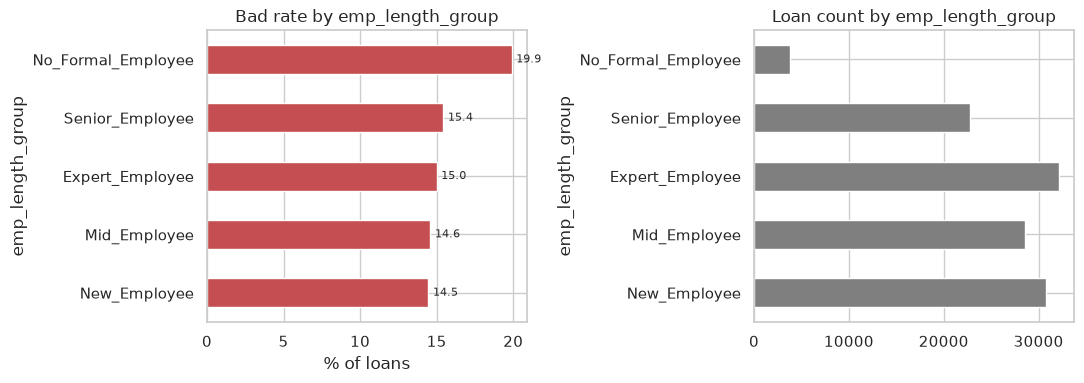

target,0,1
emp_length_group,,
New_Employee,26288,4445
Mid_Employee,24408,4172
Senior_Employee,19290,3522
Expert_Employee,27307,4820
No_Formal_Employee,3055,759


In [49]:
eda_profile(df, 'emp_length_group')


In [50]:
missing_summary(df.select_dtypes(include=[np.number, 'int64', 'float64']))

,Missing Values,Percentage,Total length
collections_12_mths_ex_med,115,0.10,118066
mths_since_last_delinq,71838,60.85,118066
mths_since_last_major_derog,108787,92.14,118066
mths_since_last_record,110993,94.01,118066
revol_util,113,0.10,118066
tot_coll_amt,70037,59.32,118066
tot_cur_bal,70037,59.32,118066
total_rev_hi_lim,70037,59.32,118066
emp_length_ordinal,3814,3.23,118066


In [51]:
missing_summary(df.select_dtypes(include=['object', 'str', 'category']))

,Missing Values,Percentage,Total length


In [52]:
df.info()

<class 'pandas.DataFrame'>
Index: 118066 entries, 1296599 to 1289878
Data columns (total 50 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   acc_now_delinq               118066 non-null  float64       
 1   annual_inc                   118066 non-null  float64       
 2   collection_recovery_fee      118066 non-null  float64       
 3   collections_12_mths_ex_med   117951 non-null  float64       
 4   delinq_2yrs                  118066 non-null  float64       
 5   dti                          118066 non-null  float64       
 6   earliest_cr_line             118066 non-null  datetime64[us]
 7   funded_amnt                  118066 non-null  int64         
 8   funded_amnt_inv              118066 non-null  float64       
 9   grade                        118066 non-null  category      
 10  home_ownership               118066 non-null  str           
 11  initial_list_status          118066

---
### `collections_12_mths_ex_med`: 
Number of collections in 12 months excluding medical collections.

count    117951.000
mean          0.001
std           0.030
min           0.000
25%           0.000
50%           0.000
75%           0.000
max           2.000

Counts:
target                           0      1
collections_12_mths_ex_med               
0.0                         100180  17683
1.0                             74      9
2.0                              4      1

Bad rate (%):
collections_12_mths_ex_med
1.0    10.84
0.0    15.00
2.0    20.00

chi2=1.22, p=0.542, dof=2


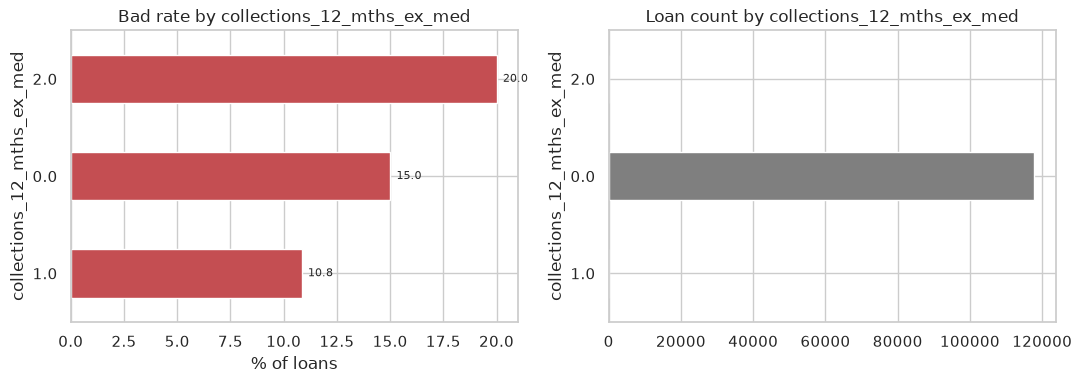

target,0,1
collections_12_mths_ex_med,,
0.0,100180,17683
1.0,74,9
2.0,4,1


In [53]:
eda_profile(df, 'collections_12_mths_ex_med')


In [54]:
def binarize_collections(dataframe, col_name='collections_12_mths_ex_med'):
    df_processed = dataframe.copy()
    
    # Create a simple mapping function
    def group_collections(val):
        if pd.isna(val):
            return 'Unknown' # Watch for `NaN` values
        elif val == 0:
            return 'No_Collections'
        else:
            return 'Has_Collections'
            
    # Apply to new column
    df_processed['collections_12mths_group'] = df_processed[col_name].apply(group_collections)

    # Change the data type to category
    df_processed['collections_12mths_group'] = df_processed['collections_12mths_group'].astype('category')
    
    # Delete the original numeric column to avoid duplication
    # df_processed = df_processed.drop(columns=[col_name])
    
    return df_processed


df = binarize_collections(dataframe=df, col_name='collections_12_mths_ex_med')

# Check results
df[['collections_12mths_group']].describe()

,collections_12mths_group
count,118066
unique,3
top,No_Collections
freq,117863


collections_12mths_group
No_Collections     117863
Unknown               115
Has_Collections        88

Counts:
target                         0      1
collections_12mths_group               
Has_Collections               78     10
No_Collections            100180  17683
Unknown                       90     25

Bad rate (%):
collections_12mths_group
Has_Collections    11.36
No_Collections     15.00
Unknown            21.74

chi2=5.00, p=0.0819, dof=2


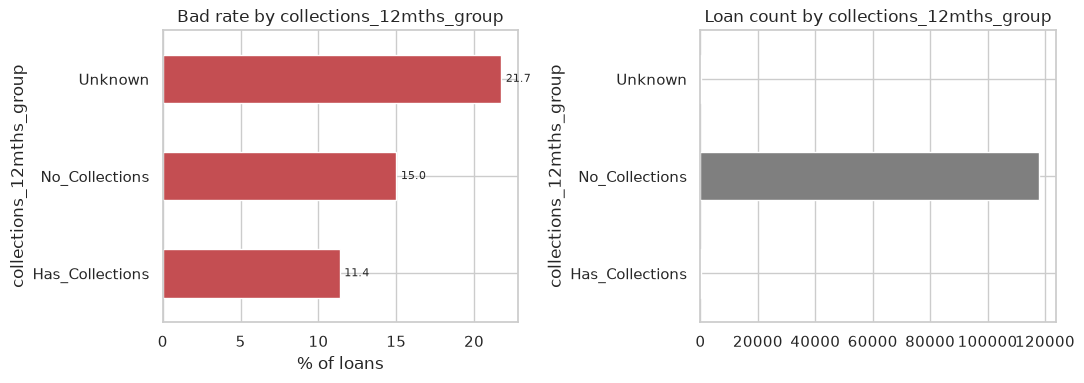

target,0,1
collections_12mths_group,,
Has_Collections,78,10
No_Collections,100180,17683
Unknown,90,25


In [55]:
eda_profile(df, 'collections_12mths_group')


<br>

---
### `acc_now_delinq`: 
The number of accounts on which the borrower is now delinquent.

In [56]:
df['acc_now_delinq'].value_counts(normalize=True) * 100

acc_now_delinq
0.0    99.939864
1.0     0.055901
2.0     0.003388
4.0     0.000847
Name: proportion, dtype: float64

**Dominant value**: 0.0 (99.73%) <br>

The `acc_now_delinq` feature has Near-Zero Variance and should be dropped.

In [57]:
df.drop(columns=['acc_now_delinq'], inplace=True)

<br>

---
- `mths_since_last_delinq`: The number of months since the borrower's last delinquency.
- `mths_since_last_major_derog`: Months since most recent 90-day or worse rating.
- `mths_since_last_record`: The number of months since the last public record.

In [58]:
missing_summary(df[['mths_since_last_delinq', 
    'mths_since_last_major_derog', 
    'mths_since_last_record']])

,Missing Values,Percentage,Total length
mths_since_last_delinq,71838,60.85,118066
mths_since_last_major_derog,108787,92.14,118066
mths_since_last_record,110993,94.01,118066


In [59]:
df[['mths_since_last_delinq', 
    'mths_since_last_major_derog', 
    'mths_since_last_record']].describe().round(4)

,mths_since_last_delinq,mths_since_last_major_derog,mths_since_last_record
count,46228.0000,9279.0000,7073.0000
mean,35.9244,42.0311,72.9393
std,21.8072,20.8755,40.6970
min,0.0000,0.0000,0.0000
25%,18.0000,25.0000,47.0000
50%,33.0000,40.0000,90.0000
75%,52.0000,59.0000,104.0000
max,152.0000,152.0000,129.0000


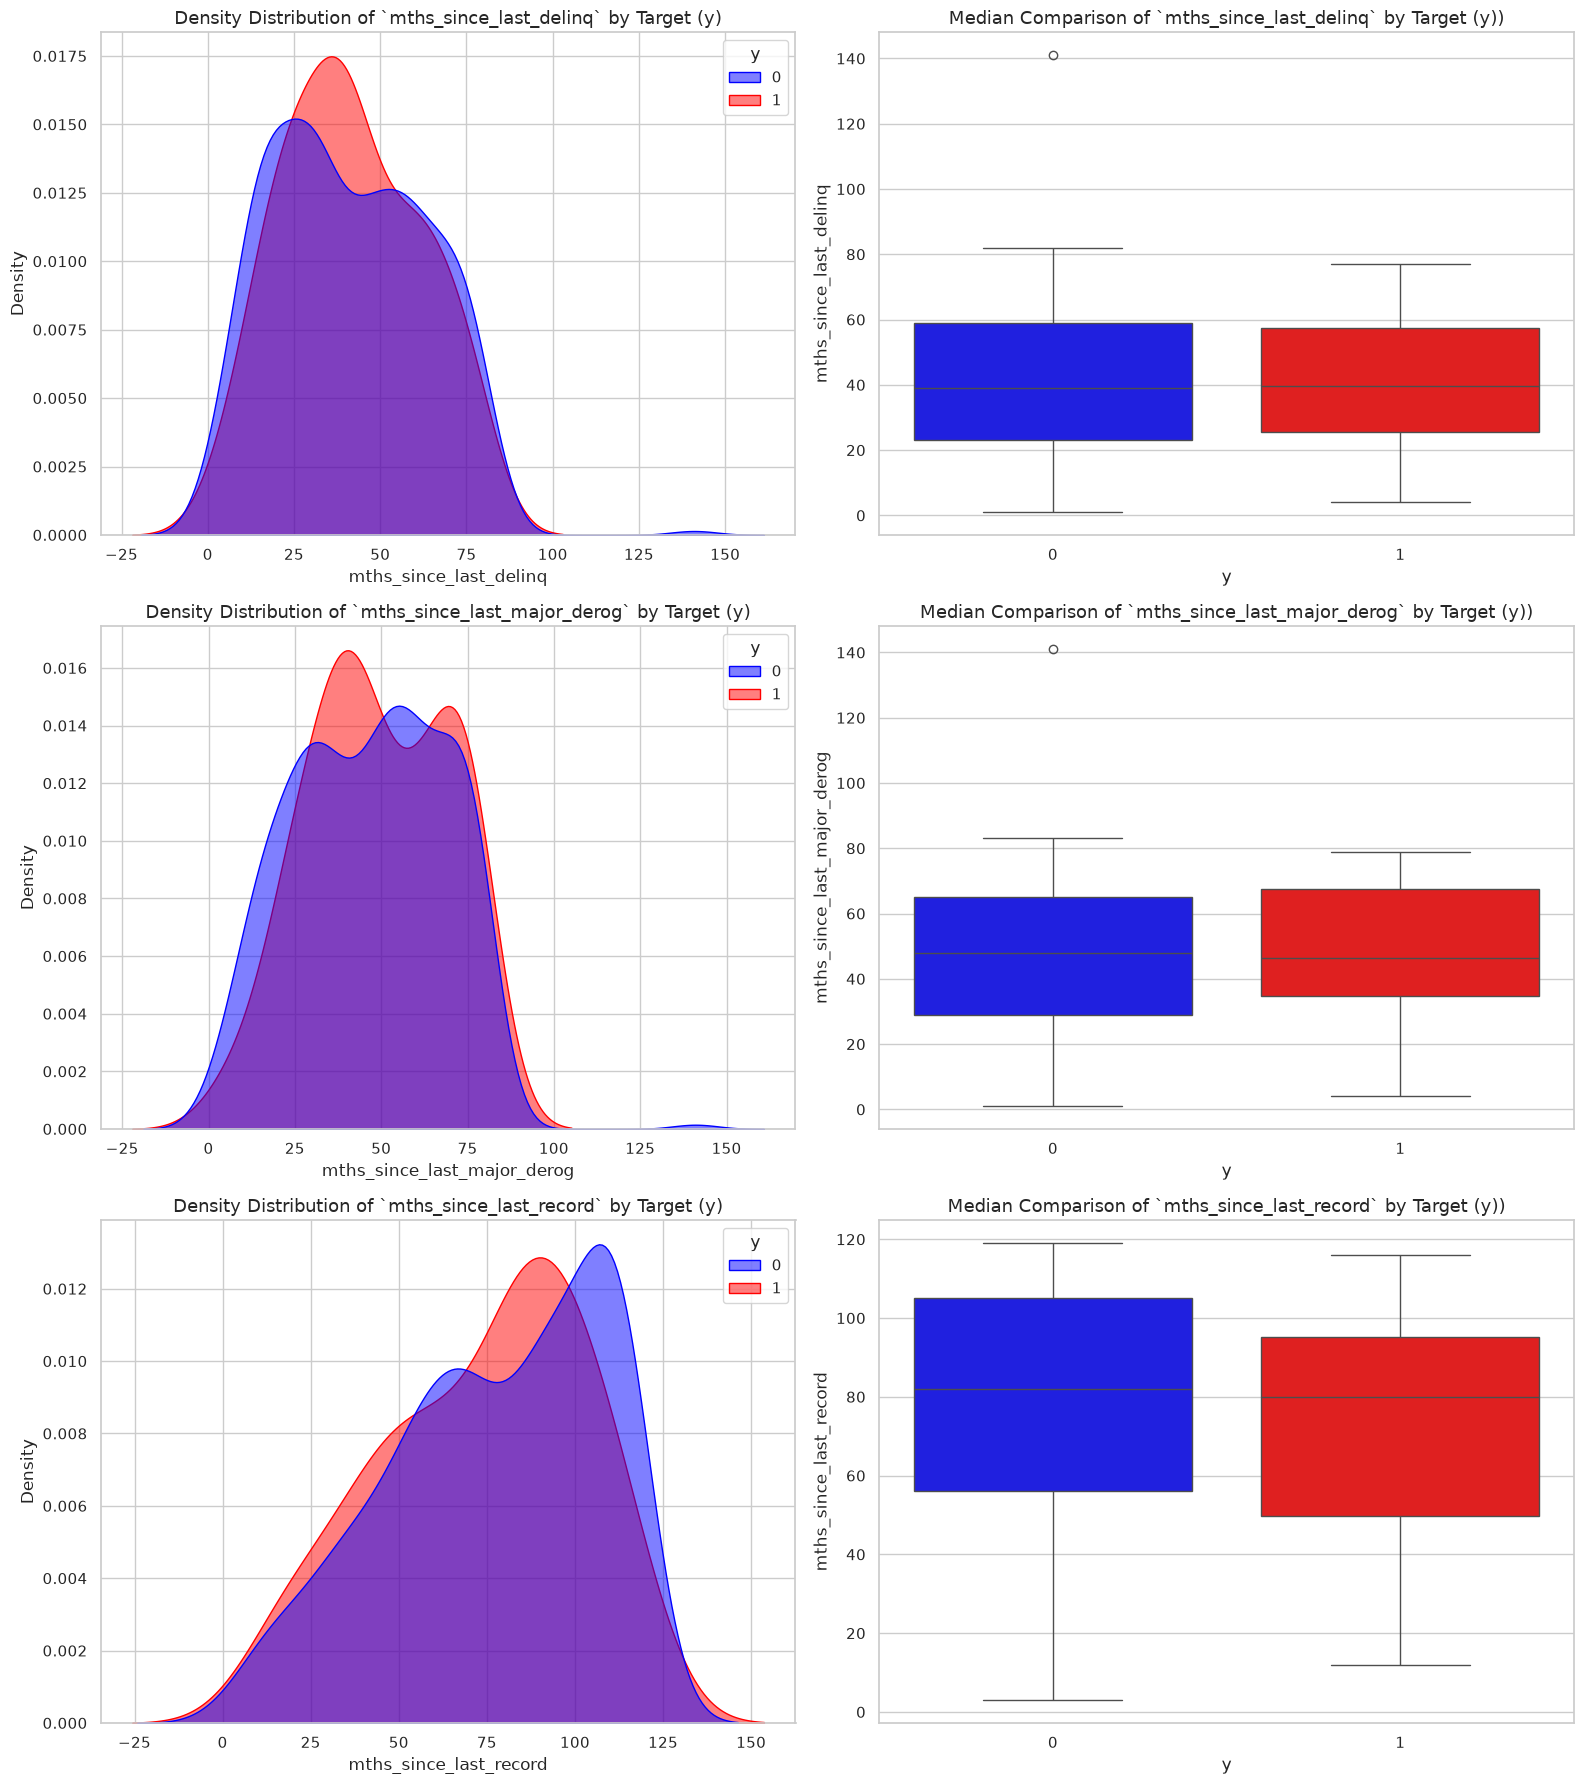

In [60]:
from src.utils import plot_numeric_distributions

plot_numeric_distributions(
    df[['mths_since_last_delinq', 'mths_since_last_major_derog', 'mths_since_last_record']],
    target_col=df['target']
)

In [61]:
(df[['mths_since_last_delinq', 'mths_since_last_major_derog', 'mths_since_last_record']] == 0).sum()

mths_since_last_delinq          834
mths_since_last_major_derog       3
mths_since_last_record         1271
dtype: int64

In [62]:
# Fill delinquency indicators
df['mths_since_last_delinq'] = df['mths_since_last_delinq'].fillna(999).astype('int64')
df['mths_since_last_major_derog'] = df['mths_since_last_major_derog'].fillna(999).astype('int64')
df['mths_since_last_record'] = df['mths_since_last_record'].fillna(999).astype('int64')

cols_to_replace = [
    'mths_since_last_delinq', 
    'mths_since_last_record',
    'mths_since_last_major_derog'
]
df[cols_to_replace] = df[cols_to_replace].replace(0, 999)

missing_summary(df[['mths_since_last_delinq', 'mths_since_last_major_derog', 'mths_since_last_record']])

,Missing Values,Percentage,Total length


In [63]:
(df[['mths_since_last_delinq', 'mths_since_last_major_derog', 'mths_since_last_record']] == 0).sum()

mths_since_last_delinq         0
mths_since_last_major_derog    0
mths_since_last_record         0
dtype: int64

In [64]:
df[['mths_since_last_delinq', 'mths_since_last_major_derog', 'mths_since_last_record']].sample(5)

,mths_since_last_delinq,mths_since_last_major_derog,mths_since_last_record
member_id,,,
2637053,22,22,999
1436753,14,999,999
2738333,2,999,999
2417098,999,999,999
777200,999,999,999


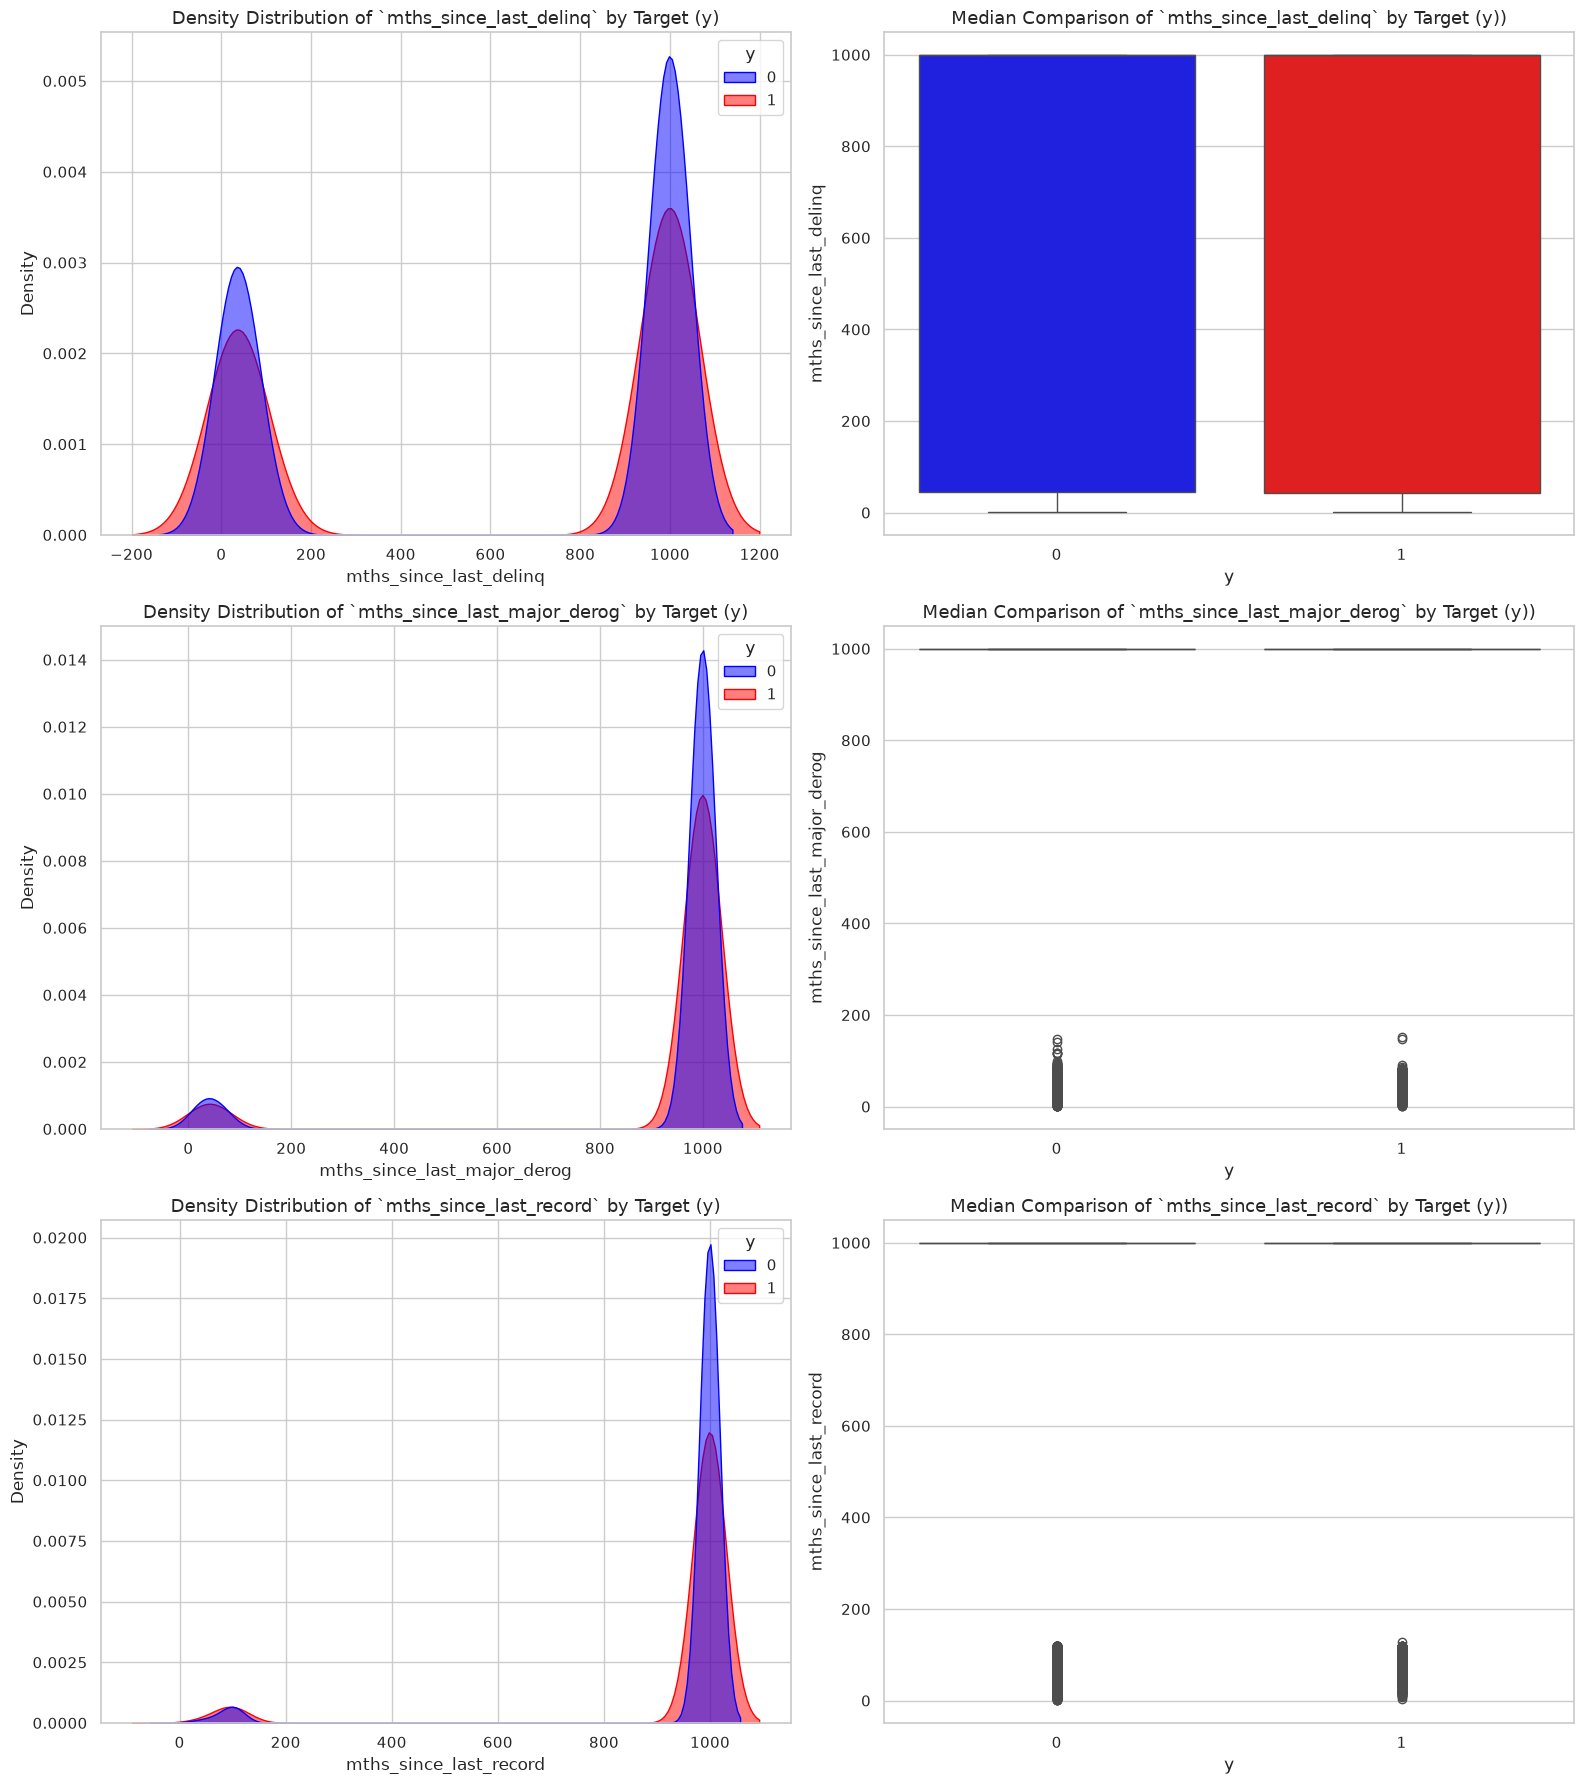

In [65]:
# List of columns to be visualized
cols_mths = ['mths_since_last_delinq', 'mths_since_last_major_derog', 'mths_since_last_record']

plot_numeric_distributions(
    df[cols_mths],
    target_col=df['target']
)

In [66]:
# 1. Define the boundaries of the bins and their category names (labels)
bins = [-1, 12, 24, 36, 60, 998, 1000]
labels = [
    '0-12_mths',
    '12-24_mths',
    '24-36_mths',
    '36-60_mths',
    '60_mths',
    'no_history',
]

# 2. List of target columns to be binned
features_to_bin = [
    'mths_since_last_delinq',
    'mths_since_last_major_derog',
    'mths_since_last_record',
]

# 3. Execute a loop to create a new column with the suffix '_binned'
for col in features_to_bin:
    df[f"{col}_binned"] = pd.cut(df[col], bins=bins, labels=labels)

In [67]:
# 4. Display results
display(df[['delinq_2yrs','mths_since_last_delinq', 'mths_since_last_delinq_binned']].sample(12))

,delinq_2yrs,mths_since_last_delinq,mths_since_last_delinq_binned
member_id,,,
3426956,0.0,25,24-36_mths
414546,0.0,999,no_history
521153,0.0,67,60_mths
627365,0.0,999,no_history
1971097,0.0,69,60_mths
1812776,4.0,6,0-12_mths
1975353,0.0,999,no_history
1390777,0.0,25,24-36_mths
1704457,1.0,22,12-24_mths


In [68]:
# Fetch row with value '0-12_mths' and 0 from `delinq_2yrs`
df_filtered = df[
    (df['mths_since_last_delinq_binned'] == '0-12_mths') &
    (df['delinq_2yrs'] == 0)
]

# Show some example lines
display(df_filtered[['delinq_2yrs', 'mths_since_last_delinq', 'mths_since_last_delinq_binned']])

,delinq_2yrs,mths_since_last_delinq,mths_since_last_delinq_binned
member_id,,,


| member_id | delinq_2yrs | mths_since_last_delinq | mths_since_last_delinq_binned |
|-----------|-------------|------------------------|-------------------------------|
| 265533    | 0.0         | 0                      | 0-12_mths                     |
| 232106    | 0.0         | 0                      | 0-12_mths                     |
| 267771    | 0.0         | 0                      | 0-12_mths                     |
| 234569    | 0.0         | 0                      | 0-12_mths                     |
| 274280    | 0.0         | 0                      | 0-12_mths                     |
| ...       | ...         | ...                    | ...                           |
| 91067     | 0.0         | 0                      | 0-12_mths                     |
| 80039     | 0.0         | 0                      | 0-12_mths                     |
| 88023     | 0.0         | 0                      | 0-12_mths                     |
| 26667537  | 0.0         | 11                     | 0-12_mths                     |
| 17523420  | 0.0         | 4                      | 0-12_mths                     |
| 818 x 3 rows |

In [69]:
# Fetch row with value '0-12_mths' and 0 from `delinq_2yrs`
df_filtered = df[
    (df['mths_since_last_delinq_binned'] == '0-12_mths') &
    (df['delinq_2yrs'] == 0) & (df['mths_since_last_delinq'] > 0)
]

# Show some example lines
display(df_filtered[['delinq_2yrs', 'mths_since_last_delinq', 'mths_since_last_delinq_binned']])

,delinq_2yrs,mths_since_last_delinq,mths_since_last_delinq_binned
member_id,,,


| member_id | delinq_2yrs | mths_since_last_delinq | mths_since_last_delinq_binned |
|-----------|-------------|------------------------|-------------------------------|
| 26667537  | 0.0         | 11                     | 0-12_mths                     |
| 17523420  | 0.0         | 4                      | 0-12_mths                     |

<br>

---
### `pub_rec` & `mths_since_last_record`:

In [70]:
display(df[['pub_rec', 'mths_since_last_record', 'mths_since_last_record_binned']].sample(12))

,pub_rec,mths_since_last_record,mths_since_last_record_binned
member_id,,,
2436283,0.0,999,no_history
1964142,0.0,999,no_history
721039,0.0,999,no_history
424961,0.0,999,no_history
870267,0.0,999,no_history
1962899,0.0,999,no_history
4668231,0.0,999,no_history
3537079,0.0,999,no_history
3410775,0.0,999,no_history


In [71]:
# Fetch row with value '0-12_mths' and 0 from `pub_rec`
df_filtered = df[
    (df['mths_since_last_record_binned'] == '0-12_mths') &
    (df['pub_rec'] == 0) 
]
# Show some example lines
display(df_filtered[['pub_rec', 'mths_since_last_record', 'mths_since_last_record_binned']])

,pub_rec,mths_since_last_record,mths_since_last_record_binned
member_id,,,


| member_id | pub_rec | mths_since_last_record | mths_since_last_record_binned |
|-----------|---------|------------------------|-------------------------------|
| 265533    | 0.0     | 0                      | 0-12_mths                     |
| 154254    | 0.0     | 0                      | 0-12_mths                     |
| 232106    | 0.0     | 0                      | 0-12_mths                     |
| 264924    | 0.0     | 0                      | 0-12_mths                     |
| 267771    | 0.0     | 0                      | 0-12_mths                     |
| ...       | ...     | ...                    | ...                           |
| 91067     | 0.0     | 0                      | 0-12_mths                     |
| 90090     | 0.0     | 0                      | 0-12_mths                     |
| 80039     | 0.0     | 0                      | 0-12_mths                     |
| 88629     | 0.0     | 0                      | 0-12_mths                     |
| 88023     | 0.0     | 0                      | 0-12_mths          
 | 1271 rows × 3 columns |          |


In [72]:
# Fetch row with value '0-12_mths' and 0 from `delinq_2yrs`
df_filtered = df[
    (df['mths_since_last_record_binned'] == '0-12_mths') &
    (df['pub_rec'] == 0) & (df['mths_since_last_record'] > 0)
]

# Show some example lines
display(df_filtered[['pub_rec', 'mths_since_last_record', 'mths_since_last_record_binned']])

,pub_rec,mths_since_last_record,mths_since_last_record_binned
member_id,,,


<br>

> It should be noted that there is a structural relationship pattern between `delinq_2yrs` & `mths_since_last_delinq`, as well as `pub_rec` & `mths_since_last_record`. If a value of 0 in the `mths_since_` feature were assumed to indicate an immediate or very recent delinquency or public record, the corresponding `delinq_2yrs` and `pub_rec` features would typically reflect non-zero values. However, the data exploration reveals that 818 rows for `delinq_2yrs` and 1,271 rows for `pub_rec` have values of 0 while their respective `mths_since_` features are also 0. This implies that these specific rows should be properly accounted for or categorized into the `no_history` group during the binning process.
> 
> Documenting this baseline anomaly is essential because upstream preprocessing maps baseline zero values in the `mths_since_` features to 999, assigning them to the `no_history` bin. Consequently, this inconsistency is resolved early in the pipeline and will no longer be visible in downstream cells.

<br>

mths_since_last_record_binned
no_history    112264
60_mths         4943
36-60_mths       560
24-36_mths       168
12-24_mths        92
0-12_mths         39

Counts:
target                             0      1
mths_since_last_record_binned              
0-12_mths                         33      6
12-24_mths                        75     17
24-36_mths                       144     24
36-60_mths                       473     87
60_mths                         3964    979
no_history                     95659  16605

Bad rate (%):
mths_since_last_record_binned
24-36_mths    14.29
no_history    14.79
0-12_mths     15.38
36-60_mths    15.54
12-24_mths    18.48
60_mths       19.81

chi2=94.41, p=7.93e-19, dof=5


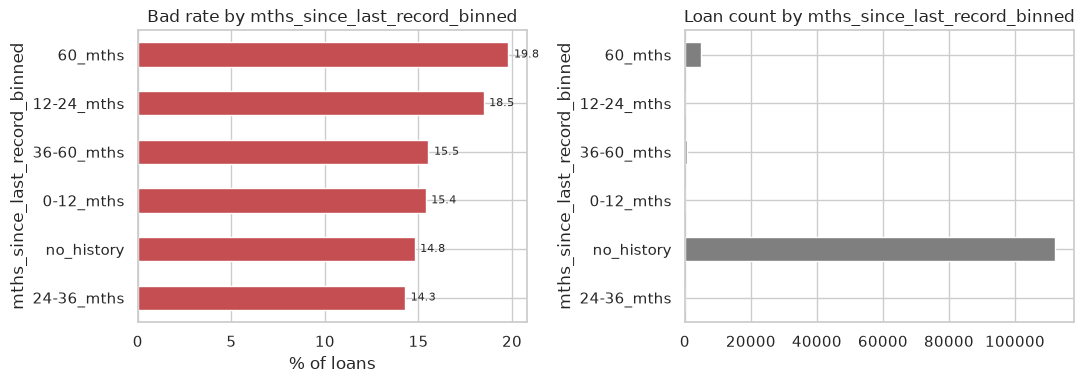

target,0,1
mths_since_last_record_binned,,
0-12_mths,33,6
12-24_mths,75,17
24-36_mths,144,24
36-60_mths,473,87
60_mths,3964,979
no_history,95659,16605


In [73]:
eda_profile(df, 'mths_since_last_record_binned')


<br>

---
### `mths_since_last_major_derog`:

In [74]:
display(df[['mths_since_last_major_derog', 'mths_since_last_major_derog_binned']].sample(12))

,mths_since_last_major_derog,mths_since_last_major_derog_binned
member_id,,
1729048,999,no_history
1821875,999,no_history
1614563,999,no_history
1410516,999,no_history
1500196,999,no_history
3859762,999,no_history
1394911,999,no_history
1087506,999,no_history
1701912,999,no_history


mths_since_last_major_derog_binned
no_history    108790
36-60_mths      2997
60_mths         2145
24-36_mths      1946
12-24_mths      1556
0-12_mths        632

Counts:
target                                  0      1
mths_since_last_major_derog_binned              
0-12_mths                             531    101
12-24_mths                           1309    247
24-36_mths                           1687    259
36-60_mths                           2511    486
60_mths                              1812    333
no_history                          92498  16292

Bad rate (%):
mths_since_last_major_derog_binned
24-36_mths    13.31
no_history    14.98
60_mths       15.52
12-24_mths    15.87
0-12_mths     15.98
36-60_mths    16.22

chi2=9.75, p=0.0825, dof=5


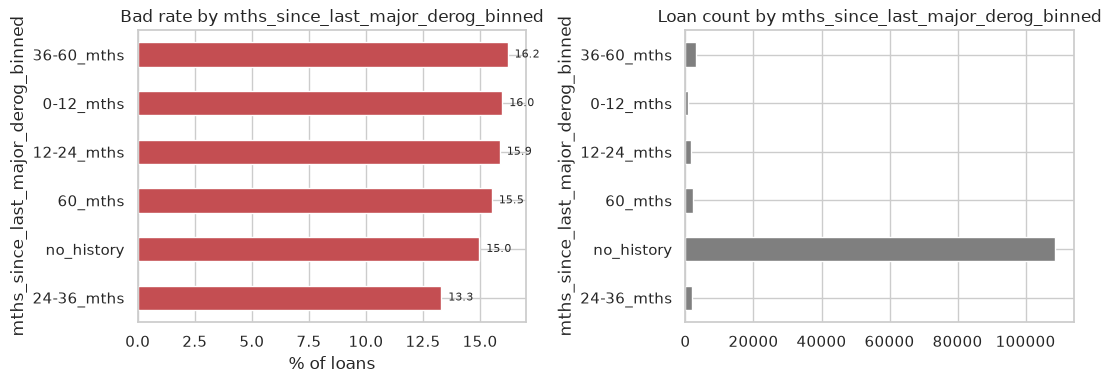

target,0,1
mths_since_last_major_derog_binned,,
0-12_mths,531,101
12-24_mths,1309,247
24-36_mths,1687,259
36-60_mths,2511,486
60_mths,1812,333
no_history,92498,16292


In [75]:
eda_profile(df, 'mths_since_last_major_derog_binned')


<br>

Drop old columns:

In [76]:
df.drop(columns=['mths_since_last_delinq', 
                 'mths_since_last_major_derog',
                 'mths_since_last_record'], inplace=True)

<br>

---
### `pub_rec`: 
Number of derogatory public records.

count    118066.000
mean          0.053
std           0.249
min           0.000
25%           0.000
50%           0.000
75%           0.000
max           8.000

Counts:
target       0      1
pub_rec              
0.0      95659  16605
1.0       4385   1064
2.0        228     39
3.0         50      7
4.0         17      0
5.0          8      1
6.0          0      1
7.0          0      1
8.0          1      0

Bad rate (%):
pub_rec
4.0      0.00
8.0      0.00
5.0     11.11
3.0     12.28
2.0     14.61
0.0     14.79
1.0     19.53
6.0    100.00
7.0    100.00

chi2=106.35, p=2.14e-19, dof=8


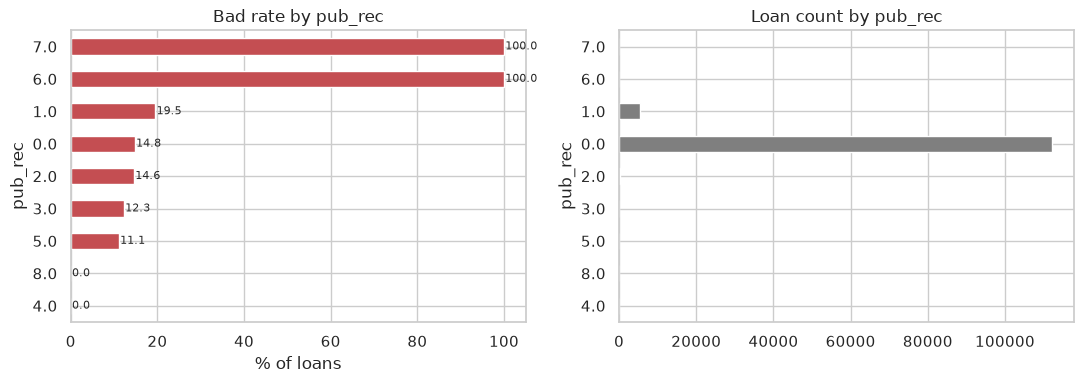

target,0,1
pub_rec,,
0.0,95659,16605
1.0,4385,1064
2.0,228,39
3.0,50,7
4.0,17,0
5.0,8,1
6.0,0,1
7.0,0,1
8.0,1,0


In [77]:
eda_profile(df, 'pub_rec')


In [78]:
def binning_pub_rec(dataframe, col_name='pub_rec'):
    df_processed = dataframe.copy()
    
    # Mapping function
    def group_pub_rec(val):
        if pd.isna(val):
            return 'Unknown'
        elif val == 0:
            return '0_pub_rec'
        elif val == 1:
            return '1_pub_rec'
        else:
            return '2_or_more'
            
    df_processed['pub_rec_group'] = df_processed[col_name].apply(group_pub_rec).astype('category')
    
    # Drop old column
    # df_processed = df_processed.drop(columns=[col_name])
    
    return df_processed

df = binning_pub_rec(dataframe=df, col_name='pub_rec')

df['pub_rec_group'].value_counts(normalize=True)

pub_rec_group
0_pub_rec    0.950858
1_pub_rec    0.046152
2_or_more    0.002990
Name: proportion, dtype: float64

pub_rec_group
0_pub_rec    112264
1_pub_rec      5449
2_or_more       353

Counts:
target             0      1
pub_rec_group              
0_pub_rec      95659  16605
1_pub_rec       4385   1064
2_or_more        304     49

Bad rate (%):
pub_rec_group
2_or_more    13.88
0_pub_rec    14.79
1_pub_rec    19.53

chi2=91.72, p=1.21e-20, dof=2


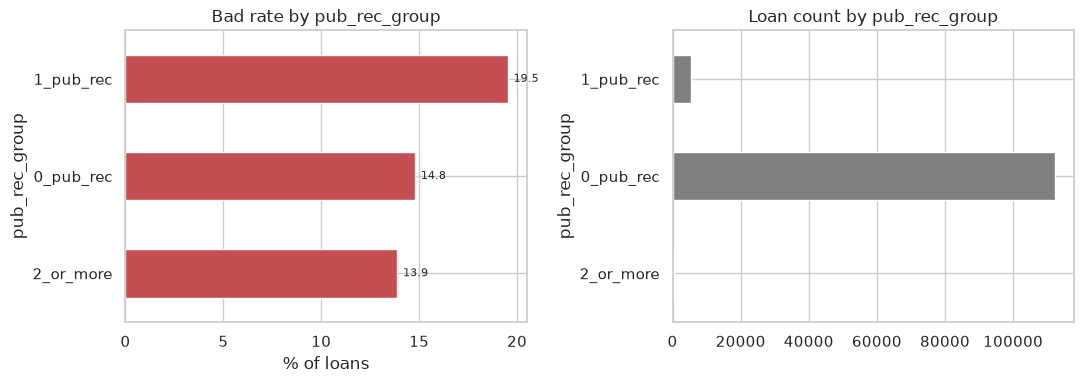

target,0,1
pub_rec_group,,
0_pub_rec,95659,16605
1_pub_rec,4385,1064
2_or_more,304,49


In [79]:
eda_profile(df, 'pub_rec_group')


<br> 

---
### `delinq_2yrs`:
The number of 30+ days past-due incidences of delinquency in the borrower's credit file for the past 2 years.

count    118066.000
mean          0.183
std           0.594
min           0.000
25%           0.000
50%           0.000
75%           0.000
max          24.000

Counts:
target           0      1
delinq_2yrs              
0.0          87718  15305
1.0           9256   1761
2.0           2258    433
3.0            664    122
4.0            217     43
5.0            119     26
6.0             50     11
7.0             31      9
8.0             10      3
9.0              9      0
10.0             5      1
11.0             4      3
12.0             3      0
13.0             2      0
14.0             0      1
18.0             1      0
24.0             1      0

Bad rate (%):
delinq_2yrs
12.0      0.00
13.0      0.00
18.0      0.00
9.0       0.00
24.0      0.00
0.0      14.86
3.0      15.52
1.0      15.98
2.0      16.09
4.0      16.54
10.0     16.67
5.0      17.93
6.0      18.03
7.0      22.50
8.0      23.08
11.0     42.86
14.0    100.00

chi2=29.81, p=0.019, dof=16


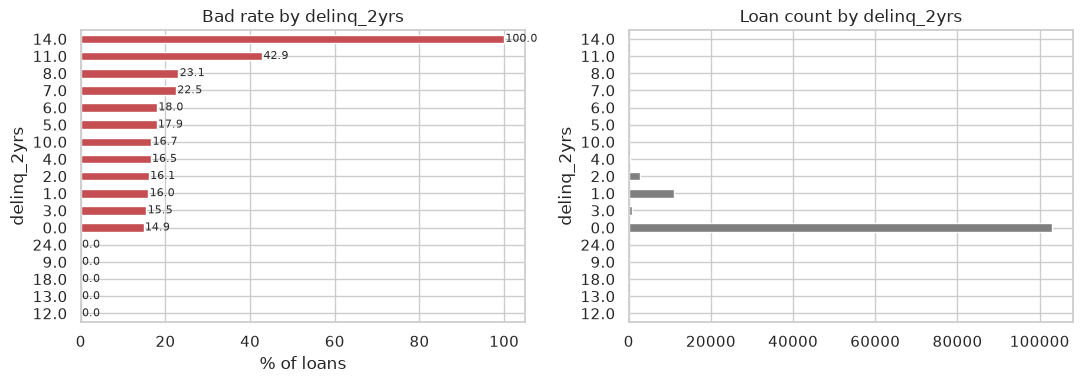

target,0,1
delinq_2yrs,,
0.0,87718,15305
1.0,9256,1761
2.0,2258,433
3.0,664,122
4.0,217,43
5.0,119,26
6.0,50,11
7.0,31,9
8.0,10,3


In [80]:
eda_profile(df, 'delinq_2yrs')


In [81]:
def binning_delinq_2yrs(dataframe, col_name='delinq_2yrs'):
    df_processed = dataframe.copy()
    
    # Mapping function based on bad-rate analysis
    def group_delinq(val):
        if pd.isna(val):
            return 'Unknown'
        elif val == 0:
            return '0_delinq'
        elif val == 1:
            return '1_delinq'
        elif val == 2:
            return '2_delinq'
        else:
            return '3_or_more'
            
    df_processed['delinq_2yrs_group'] = df_processed[col_name].apply(group_delinq).astype('category')
    
    # Drop the old column
    # df_processed = df_processed.drop(columns=[col_name])
    
    return df_processed

df = binning_delinq_2yrs(dataframe=df, col_name='delinq_2yrs')

df['delinq_2yrs_group'].value_counts(normalize=True)

delinq_2yrs_group
0_delinq     0.872588
1_delinq     0.093312
2_delinq     0.022792
3_or_more    0.011307
Name: proportion, dtype: float64

delinq_2yrs_group
0_delinq     103023
1_delinq      11017
2_delinq       2691
3_or_more      1335

Counts:
target                 0      1
delinq_2yrs_group              
0_delinq           87718  15305
1_delinq            9256   1761
2_delinq            2258    433
3_or_more           1116    219

Bad rate (%):
delinq_2yrs_group
0_delinq     14.86
1_delinq     15.98
2_delinq     16.09
3_or_more    16.40

chi2=14.62, p=0.00217, dof=3


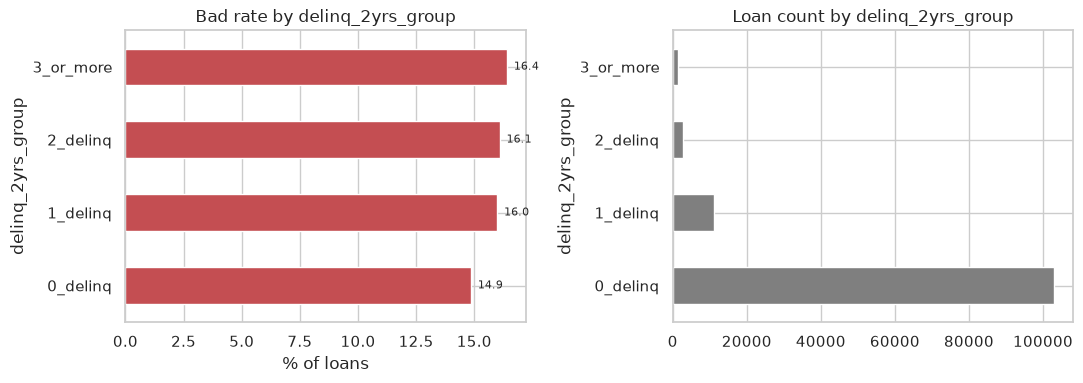

target,0,1
delinq_2yrs_group,,
0_delinq,87718,15305
1_delinq,9256,1761
2_delinq,2258,433
3_or_more,1116,219


In [82]:
eda_profile(df, 'delinq_2yrs_group')


<br>

---
### New feature: `payment_to_income`

In [83]:
df[['dti']].head()

,dti
member_id,
1296599,27.65
1314167,1.00
1313524,8.72
1277178,20.00
1311748,17.94


In [84]:
# Calculates percentage and safely handles zero income
df['payment_to_income'] = np.where(
    df['annual_inc'] > 0, 
    (df['installment'] * 12) / df['annual_inc'] * 100, 
    0
)

In [85]:
df[['annual_inc', 'dti', 'installment', 'payment_to_income']].head()

,annual_inc,dti,installment,payment_to_income
member_id,,,,
1296599,24000.0,27.65,162.87,8.143500
1314167,30000.0,1.00,59.83,2.393200
1313524,12252.0,8.72,84.33,8.259549
1277178,49200.0,20.00,339.31,8.275854
1311748,80000.0,17.94,67.79,1.016850


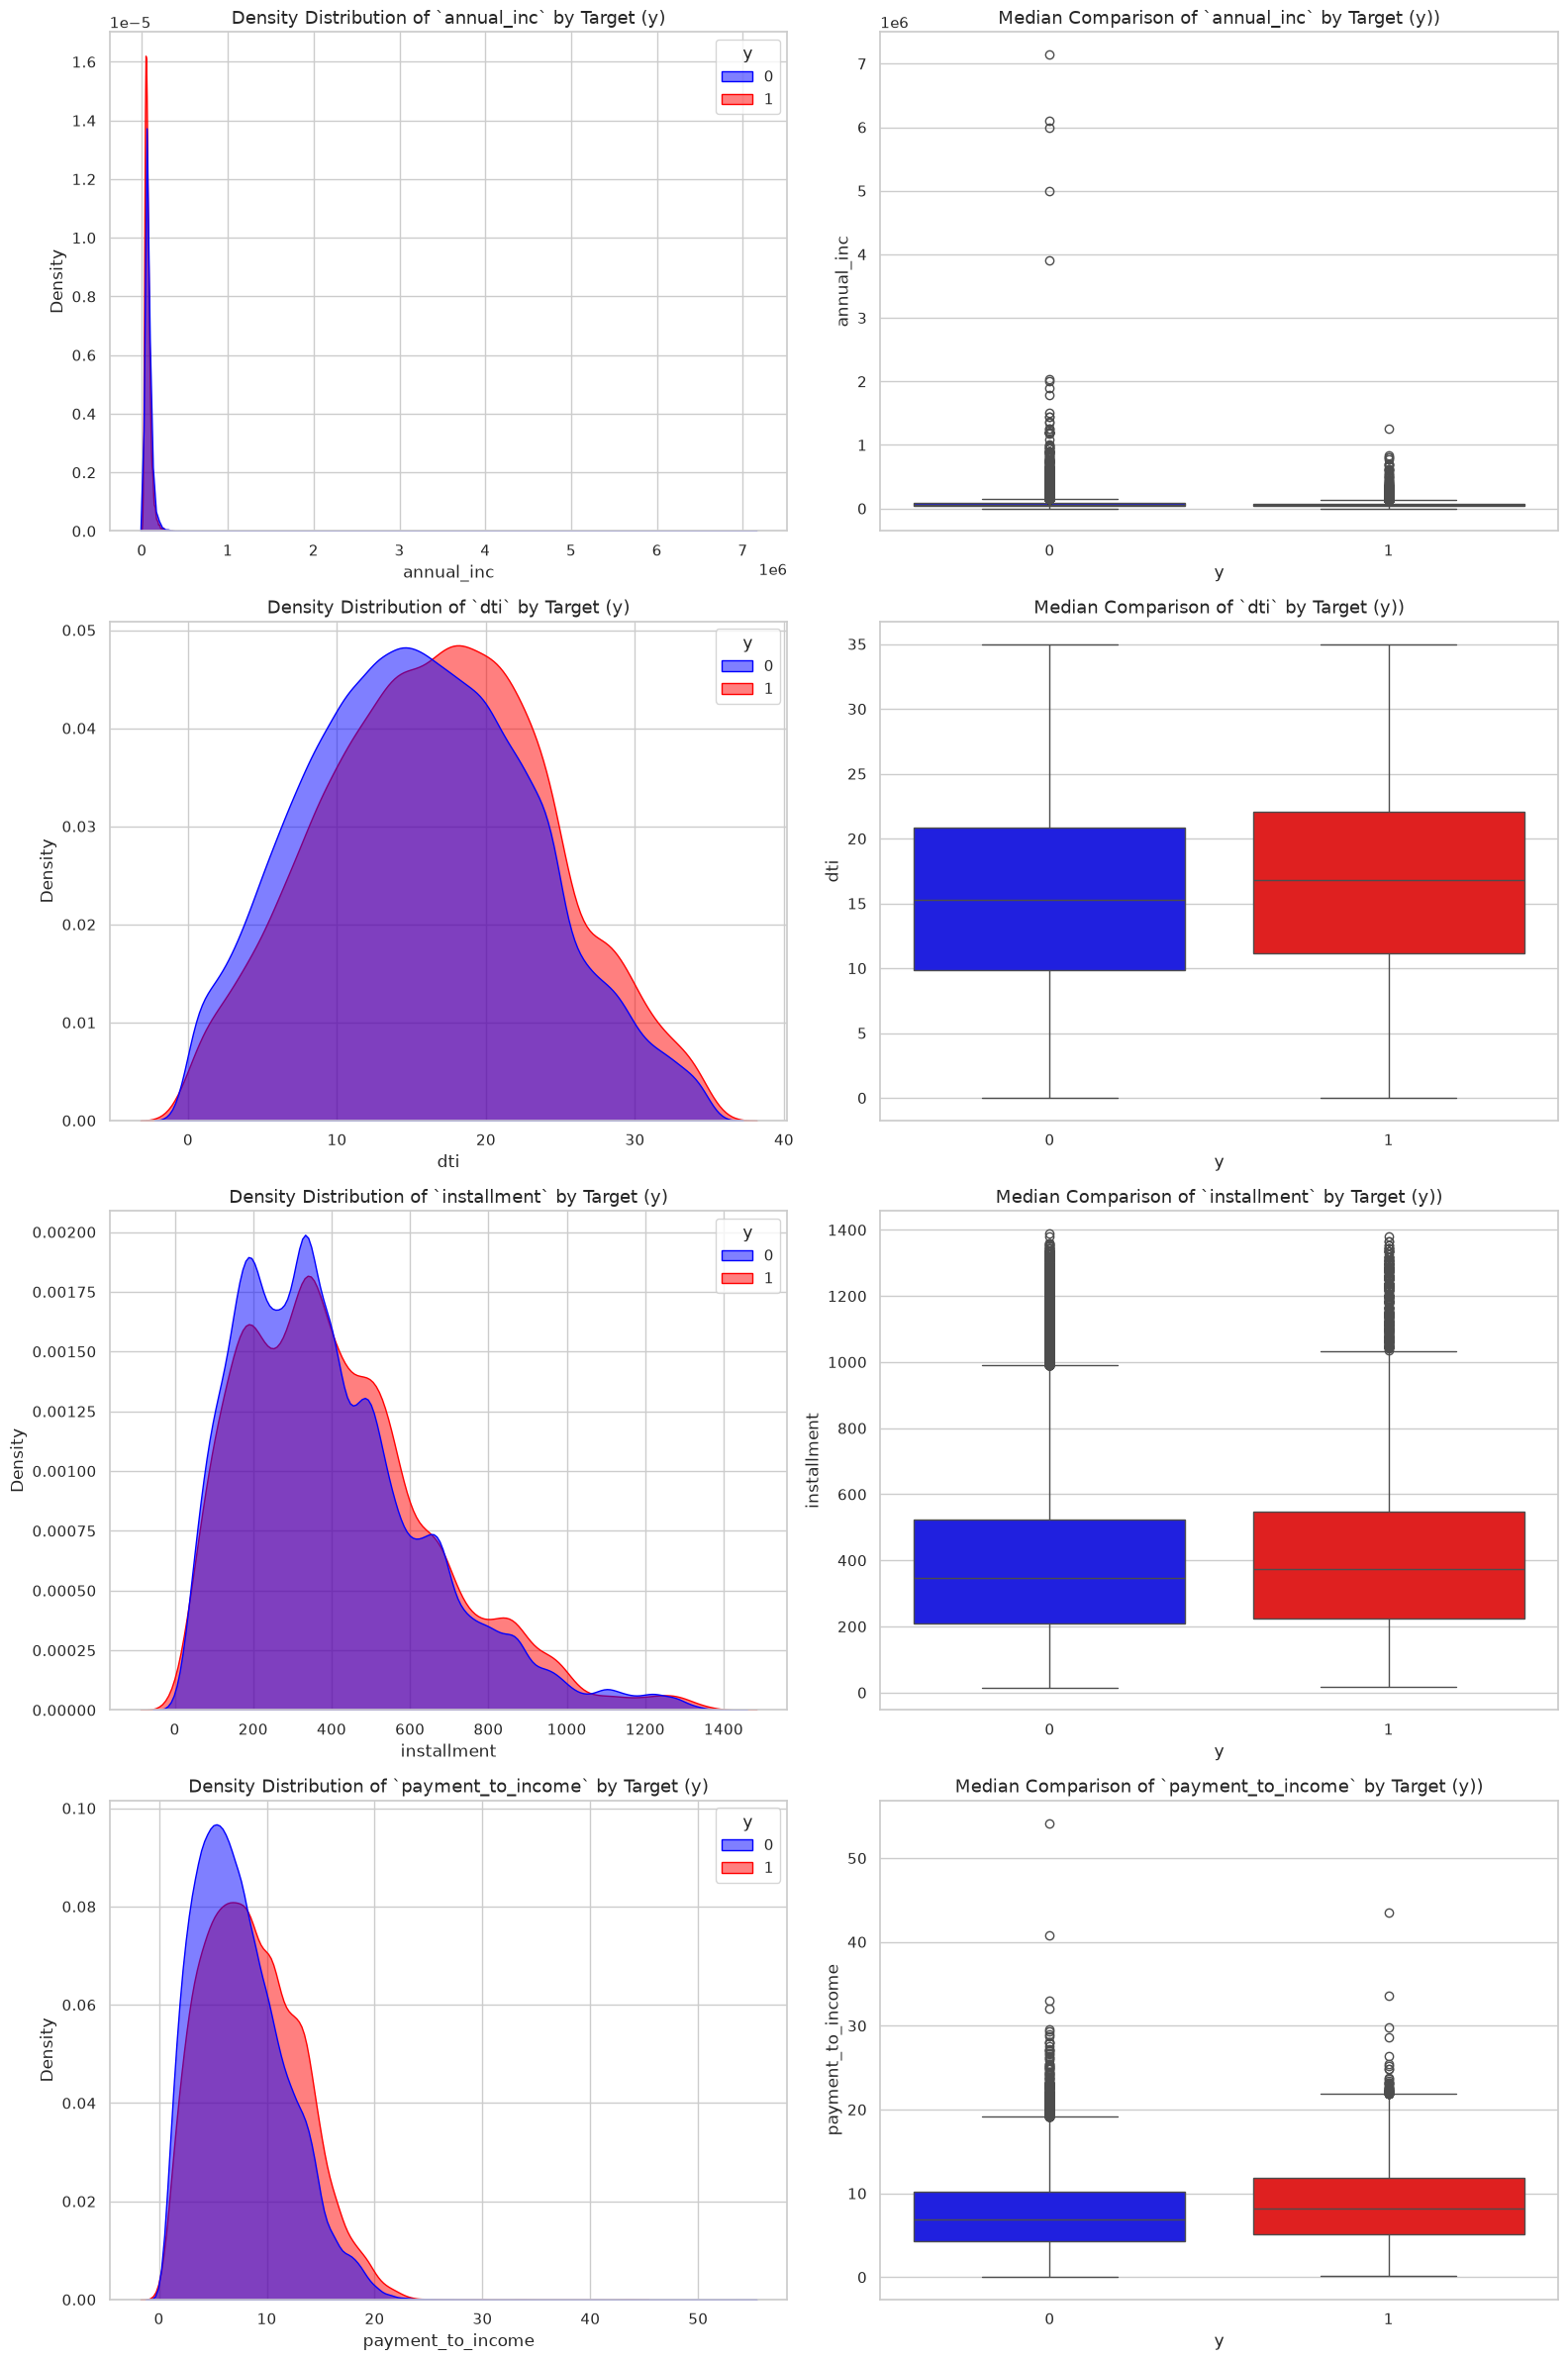

In [86]:
# List of columns to be visualized
cols = ['annual_inc', 'dti', 'installment', 'payment_to_income']

plot_numeric_distributions(
    df[cols],
    target_col=df['target']
)

<br>

- `annual_inc`: The self-reported annual income provided by the borrower during registration.
- `dti` (debt to income) : A ratio calculated using the borrower’s total monthly debt payments on the total debt obligations, excluding mortgage and the requested LC loan, divided by the borrower’s self-reported monthly income.
- `installment`: The monthly payment owed by the borrower if the loan originates.
- `payment_to_income`: (`installment` * 12) / `annual_inc` * 100

In [87]:
df['annual_inc'].describe().round()

count     118066.0
mean       70653.0
std        61896.0
min         1896.0
25%        43000.0
50%        60000.0
75%        85000.0
max      7141778.0
Name: annual_inc, dtype: float64

<br>

---
1. `funded_amnt` vs. `funded_amnt_inv`:
- **Business Analysis**: `funded_amnt` is the amount approved by the platform, `funded_amnt_inv` is the amount the investor is willing to fund. If there is a large gap (e.g., the client asks for 10,000, but the investor only wants 8,000), market psychology suggests that this client is considered "less attractive or risky" by experienced investors on the platform.

- **Best Action**: We will transform by creating a ratio feature and then removing the investor column.

In [88]:
df[['funded_amnt', 'funded_amnt_inv']].head()

,funded_amnt,funded_amnt_inv
member_id,,
1296599,5000,4975.0
1314167,2500,2500.0
1313524,2400,2400.0
1277178,10000,10000.0
1311748,3000,3000.0


In [89]:
# Guard against division by zero
df['investor_funding_ratio'] = np.where(
    df['funded_amnt'] > 0,
    df['funded_amnt_inv'] / df['funded_amnt'],
    0.0 # Langsung diisi float 0.0 jika funded_amnt bernilai 0
)

# Drop the original investor column
df.drop(columns=['funded_amnt_inv'], inplace=True)

---
2. `out_prncp` vs. `out_prncp_inv`
- **Definition**: `out_prncp` is the remaining principal outstanding by the customer for the total loan. `out_prncp_inv` is the remaining principal that belongs to the investor.

- **Business Analysis**: The difference between the two is purely an internal distribution issue between the P2P platform system and external investors. This difference does NOT reflect the customer's risk behavior. The customer doesn't care who the loan belongs to; all the customer knows is that they have a remaining debt of `out_prncp`.

- **Best Action**: We will DROP `out_prncp_inv` and KEEP `out_prncp`.

In [90]:
# Drop the `out_prncp_inv` feature
df.drop(columns=['out_prncp_inv'], inplace=True)

---
3. `total_pymnt` vs. `total_pymnt_inv`
- **Definition**: `total_pymnt` is the total amount a customer has paid so far. `total_pymnt_inv` is the portion of that payment distributed to investors.

- **Business Analysis**: Similar to the `out_prncp` case, the difference here is only a matter of internal platform financial distribution. The customer's disciplined behavior is already 100% reflected in the `total_pymnt` column. Whether the money goes to investor A or the LendingClub platform does not change the customer's status as a diligent payer.

- **Best Action**: We will DROP `total_pymnt_inv` and KEEP `total_pymnt`.

In [91]:
# Drop the `total_pymnt_inv` feature
df.drop(columns=['total_pymnt_inv'], inplace=True)

<br>

---
Check for missing values ​​after the process so far:

In [92]:
missing_summary(df)

,Missing Values,Percentage,Total length
collections_12_mths_ex_med,115,0.10,118066
revol_util,113,0.10,118066
tot_coll_amt,70037,59.32,118066
tot_cur_bal,70037,59.32,118066
total_rev_hi_lim,70037,59.32,118066
emp_length_ordinal,3814,3.23,118066


In [93]:
df = df[sorted(df.columns)]
print(df.shape)
df.head()

(118066, 51)


,annual_inc,collection_recovery_fee,collections_12_mths_ex_med,collections_12mths_group,credit_age_group,credit_age_years,credit_history_age_month,delinq_2yrs,delinq_2yrs_group,dti,earliest_cr_line,emp_length_group,emp_length_ordinal,funded_amnt,grade,home_ownership,initial_list_status,inq_last_6mths,installment,int_rate,investor_funding_ratio,issue_d,last_credit_pull_d,last_pymnt_amnt,last_pymnt_d,loan_amnt,mths_since_last_delinq_binned,mths_since_last_major_derog_binned,mths_since_last_record_binned,open_acc,out_prncp,payment_to_income,pub_rec,pub_rec_group,purpose,pymnt_plan,recoveries,revol_bal,revol_util,sub_grade,target,term,tot_coll_amt,tot_cur_bal,total_acc,total_pymnt,total_rec_int,total_rec_late_fee,total_rec_prncp,total_rev_hi_lim,verification_status
member_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1296599,24000.0,0.00,0.0,No_Collections,greater_15,26.916667,323,0.0,0_delinq,27.65,1985-01-01,Expert_Employee,10.0,5000,B,RENT,f,1.0,162.87,10.65,0.995,2011-12-01,2016-01-01,171.62,2015-01-01,5000,no_history,no_history,no_history,3.0,0.0,8.143500,0.0,0_pub_rec,credit_card,n,0.00,13648,83.7,B2,0,36 months,NaN,NaN,9.0,5861.071414,861.07,0.00,5000.00,NaN,Verified
1314167,30000.0,1.11,0.0,No_Collections,5_15,12.666667,152,0.0,0_delinq,1.00,1999-04-01,New_Employee,0.0,2500,C,RENT,f,5.0,59.83,15.27,1.000,2011-12-01,2013-09-01,119.66,2013-04-01,2500,no_history,no_history,no_history,3.0,0.0,2.393200,0.0,0_pub_rec,car,n,117.08,1687,9.4,C4,1,60 months,NaN,NaN,4.0,1008.710000,435.17,0.00,456.46,NaN,Source Verified
1313524,12252.0,0.00,0.0,No_Collections,5_15,10.083333,121,0.0,0_delinq,8.72,2001-11-01,Expert_Employee,10.0,2400,C,RENT,f,2.0,84.33,15.96,1.000,2011-12-01,2016-01-01,649.91,2014-06-01,2400,no_history,no_history,no_history,2.0,0.0,8.259549,0.0,0_pub_rec,small_business,n,0.00,2956,98.5,C5,0,36 months,NaN,NaN,10.0,3003.653644,603.65,0.00,2400.00,NaN,Not Verified
1277178,49200.0,0.00,0.0,No_Collections,greater_15,15.833333,190,0.0,0_delinq,20.00,1996-02-01,Expert_Employee,10.0,10000,C,RENT,f,1.0,339.31,13.49,1.000,2011-12-01,2015-01-01,357.48,2015-01-01,10000,24-36_mths,no_history,no_history,10.0,0.0,8.275854,0.0,0_pub_rec,other,n,0.00,5598,21.0,C1,0,36 months,NaN,NaN,37.0,12226.302210,2209.33,16.97,10000.00,NaN,Source Verified
1311748,80000.0,0.00,0.0,No_Collections,greater_15,15.916667,191,0.0,0_delinq,17.94,1996-01-01,New_Employee,1.0,3000,B,RENT,f,0.0,67.79,12.69,1.000,2011-12-01,2016-01-01,67.79,2016-01-01,3000,36-60_mths,no_history,no_history,15.0,766.9,1.016850,0.0,0_pub_rec,other,n,0.00,27783,53.9,B5,0,60 months,NaN,NaN,38.0,3242.170000,1009.07,0.00,2233.10,NaN,Source Verified


### Business question Q3a: **What do the distributions and tails look like?**

Numeric features are checked for skew, outliers and impossible values; categorical
features for rare levels and anomalies. Derived ratios (payment-to-income,
revol_bal_to_income, loan_to_income, open_acc_ratio) are tested as candidate
engineered features.

<br>

---
## **2.1. Data Type Check**:

In [94]:
df.info()

<class 'pandas.DataFrame'>
Index: 118066 entries, 1296599 to 1289878
Data columns (total 51 columns):
 #   Column                              Non-Null Count   Dtype         
---  ------                              --------------   -----         
 0   annual_inc                          118066 non-null  float64       
 1   collection_recovery_fee             118066 non-null  float64       
 2   collections_12_mths_ex_med          117951 non-null  float64       
 3   collections_12mths_group            118066 non-null  category      
 4   credit_age_group                    118066 non-null  category      
 5   credit_age_years                    118066 non-null  float64       
 6   credit_history_age_month            118066 non-null  int64         
 7   delinq_2yrs                         118066 non-null  float64       
 8   delinq_2yrs_group                   118066 non-null  category      
 9   dti                                 118066 non-null  float64       
 10  earliest_cr_line 

---
## **2.2. Split Numerical and Categorical Data for First Stage Analysis**:

In [95]:
# Numerical columns
num_cols = df.select_dtypes(include=[np.number]).drop(columns=['target'])

# Categorical columns
cat_cols = df.select_dtypes(include=['object', 'str', 'category'])

<br>

**Numerical columns:**

In [96]:
num_cols.info()

<class 'pandas.DataFrame'>
Index: 118066 entries, 1296599 to 1289878
Data columns (total 30 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   annual_inc                  118066 non-null  float64
 1   collection_recovery_fee     118066 non-null  float64
 2   collections_12_mths_ex_med  117951 non-null  float64
 3   credit_age_years            118066 non-null  float64
 4   credit_history_age_month    118066 non-null  int64  
 5   delinq_2yrs                 118066 non-null  float64
 6   dti                         118066 non-null  float64
 7   emp_length_ordinal          114252 non-null  float64
 8   funded_amnt                 118066 non-null  int64  
 9   inq_last_6mths              118066 non-null  float64
 10  installment                 118066 non-null  float64
 11  int_rate                    118066 non-null  float64
 12  investor_funding_ratio      118066 non-null  float64
 13  last_pymnt_amnt        

In [97]:
num_cols.sample(5)

,annual_inc,collection_recovery_fee,collections_12_mths_ex_med,credit_age_years,credit_history_age_month,delinq_2yrs,dti,emp_length_ordinal,funded_amnt,inq_last_6mths,installment,int_rate,investor_funding_ratio,last_pymnt_amnt,loan_amnt,open_acc,out_prncp,payment_to_income,pub_rec,recoveries,revol_bal,revol_util,tot_coll_amt,tot_cur_bal,total_acc,total_pymnt,total_rec_int,total_rec_late_fee,total_rec_prncp,total_rev_hi_lim
member_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
4669086,35000.0,0.0,0.0,5.166667,62,0.0,29.76,6.0,4125,2.0,151.32,19.05,1.0,151.32,4125,15.0,0.0,5.188114,0.0,0.0,6510,45.5,0.0,30006.0,20.0,2722.00000,950.81,0.00,1771.19,14300.0
658665,25000.0,0.0,0.0,12.500000,150,0.0,17.95,10.0,10750,1.0,250.03,13.98,1.0,2608.26,10750,3.0,0.0,12.001440,0.0,0.0,17724,72.9,NaN,NaN,15.0,14841.67299,4091.67,0.00,10750.00,NaN
905756,36996.0,0.0,0.0,9.750000,117,0.0,14.14,4.0,5775,0.0,199.94,14.91,1.0,3414.84,5775,3.0,0.0,6.485242,0.0,0.0,3365,20.6,NaN,NaN,3.0,6803.99000,1029.01,0.00,5774.98,NaN
1618576,55000.0,0.0,0.0,19.583333,235,0.0,15.45,7.0,3500,0.0,106.53,6.03,1.0,3158.47,3500,9.0,0.0,2.324291,0.0,0.0,3307,19.2,NaN,NaN,21.0,3583.82000,83.82,0.00,3500.00,NaN
1384257,62976.0,0.0,0.0,18.083333,217,0.0,13.64,5.0,14000,1.0,494.21,16.29,1.0,621.09,14000,4.0,0.0,9.417111,0.0,0.0,2243,86.3,NaN,NaN,15.0,17951.75897,3828.21,123.55,14000.00,NaN


In [98]:
num_cols.describe().round()

,annual_inc,collection_recovery_fee,collections_12_mths_ex_med,credit_age_years,credit_history_age_month,delinq_2yrs,dti,emp_length_ordinal,funded_amnt,inq_last_6mths,installment,int_rate,investor_funding_ratio,last_pymnt_amnt,loan_amnt,open_acc,out_prncp,payment_to_income,pub_rec,recoveries,revol_bal,revol_util,tot_coll_amt,tot_cur_bal,total_acc,total_pymnt,total_rec_int,total_rec_late_fee,total_rec_prncp,total_rev_hi_lim
count,118066.0,118066.0,117951.0,118066.0,118066.0,118066.0,118066.0,114252.0,118066.0,118066.0,118066.0,118066.0,118066.0,118066.0,118066.0,118066.0,118066.0,118066.0,118066.0,118066.0,118066.0,117953.0,48029.0,48029.0,118066.0,118066.0,118066.0,118066.0,118066.0,48029.0
mean,70653.0,11.0,0.0,14.0,174.0,0.0,16.0,6.0,12901.0,1.0,398.0,13.0,1.0,3265.0,13001.0,10.0,575.0,8.0,0.0,124.0,15518.0,55.0,56.0,136268.0,23.0,13881.0,2753.0,1.0,11002.0,30039.0
std,61896.0,115.0,0.0,7.0,83.0,1.0,8.0,4.0,7954.0,1.0,240.0,4.0,0.0,5210.0,8021.0,5.0,2373.0,4.0,0.0,691.0,19478.0,26.0,688.0,156682.0,11.0,9436.0,2959.0,7.0,7507.0,28889.0
min,1896.0,0.0,0.0,0.0,6.0,0.0,0.0,0.0,500.0,0.0,16.0,5.0,0.0,0.0,500.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,34.0,4.0,0.0,0.0,0.0
25%,43000.0,0.0,0.0,10.0,118.0,0.0,10.0,2.0,6650.0,0.0,212.0,10.0,1.0,307.0,6800.0,7.0,0.0,4.0,0.0,0.0,5836.0,37.0,0.0,27020.0,15.0,6715.0,883.0,0.0,5229.0,14200.0
50%,60000.0,0.0,0.0,13.0,159.0,0.0,16.0,5.0,11000.0,1.0,351.0,13.0,1.0,667.0,11200.0,10.0,0.0,7.0,0.0,0.0,11317.0,58.0,0.0,74903.0,22.0,11867.0,1790.0,0.0,9900.0,23300.0
75%,85000.0,0.0,0.0,18.0,214.0,0.0,21.0,10.0,18000.0,1.0,526.0,16.0,1.0,4157.0,18000.0,13.0,0.0,10.0,0.0,0.0,19674.0,76.0,0.0,206176.0,30.0,18896.0,3387.0,0.0,15000.0,37600.0
max,7141778.0,7002.0,2.0,65.0,785.0,24.0,35.0,10.0,35000.0,33.0,1388.0,25.0,1.0,36115.0,35000.0,53.0,22150.0,54.0,8.0,33520.0,1743266.0,119.0,55009.0,8000078.0,99.0,57778.0,24206.0,287.0,35000.0,2013133.0


<br>

**Categorical columns:**

In [99]:
cat_cols.info()

<class 'pandas.DataFrame'>
Index: 118066 entries, 1296599 to 1289878
Data columns (total 16 columns):
 #   Column                              Non-Null Count   Dtype   
---  ------                              --------------   -----   
 0   collections_12mths_group            118066 non-null  category
 1   credit_age_group                    118066 non-null  category
 2   delinq_2yrs_group                   118066 non-null  category
 3   emp_length_group                    118066 non-null  category
 4   grade                               118066 non-null  category
 5   home_ownership                      118066 non-null  str     
 6   initial_list_status                 118066 non-null  str     
 7   mths_since_last_delinq_binned       118066 non-null  category
 8   mths_since_last_major_derog_binned  118066 non-null  category
 9   mths_since_last_record_binned       118066 non-null  category
 10  pub_rec_group                       118066 non-null  category
 11  purpose               

In [100]:
cat_cols.sample(5)

,collections_12mths_group,credit_age_group,delinq_2yrs_group,emp_length_group,grade,home_ownership,initial_list_status,mths_since_last_delinq_binned,mths_since_last_major_derog_binned,mths_since_last_record_binned,pub_rec_group,purpose,pymnt_plan,sub_grade,term,verification_status
member_id,,,,,,,,,,,,,,,,
5023321,No_Collections,5_15,0_delinq,Senior_Employee,C,MORTGAGE,f,no_history,no_history,no_history,0_pub_rec,credit_card,n,C2,36 months,Not Verified
1360688,No_Collections,greater_15,0_delinq,Expert_Employee,B,MORTGAGE,f,no_history,no_history,no_history,0_pub_rec,other,n,B4,60 months,Verified
215882,No_Collections,5_15,0_delinq,New_Employee,B,RENT,f,24-36_mths,no_history,no_history,0_pub_rec,credit_card,n,B1,36 months,Not Verified
681305,No_Collections,5_15,0_delinq,Mid_Employee,F,MORTGAGE,f,no_history,no_history,no_history,0_pub_rec,other,n,F1,60 months,Source Verified
1203201,No_Collections,greater_15,0_delinq,Mid_Employee,G,MORTGAGE,f,no_history,no_history,60_mths,1_pub_rec,debt_consolidation,n,G1,60 months,Verified


In [101]:
cat_cols.describe().round()

,collections_12mths_group,credit_age_group,delinq_2yrs_group,emp_length_group,grade,home_ownership,initial_list_status,mths_since_last_delinq_binned,mths_since_last_major_derog_binned,mths_since_last_record_binned,pub_rec_group,purpose,pymnt_plan,sub_grade,term,verification_status
count,118066,118066,118066,118066,118066,118066,118066,118066,118066,118066,118066,118066,118066,118066,118066,118066
unique,3,3,4,5,7,5,2,6,6,6,3,11,2,35,2,3
top,No_Collections,5_15,0_delinq,Expert_Employee,B,MORTGAGE,f,no_history,no_history,no_history,0_pub_rec,debt_consolidation,n,B3,36 months,Verified
freq,117863,68002,103023,32127,38878,55850,107553,72672,108790,112264,112264,64113,118061,10350,92663,46252


---
## **2.3. Numerical Data Distribution and Outlier/Anomaly Checking**:

In [102]:
# Drop Nan for visualization
df_temp = df.dropna()

# Get all numeric columns except target `y`
num_cols = df_temp.select_dtypes(include=[np.number]).columns.drop('target')

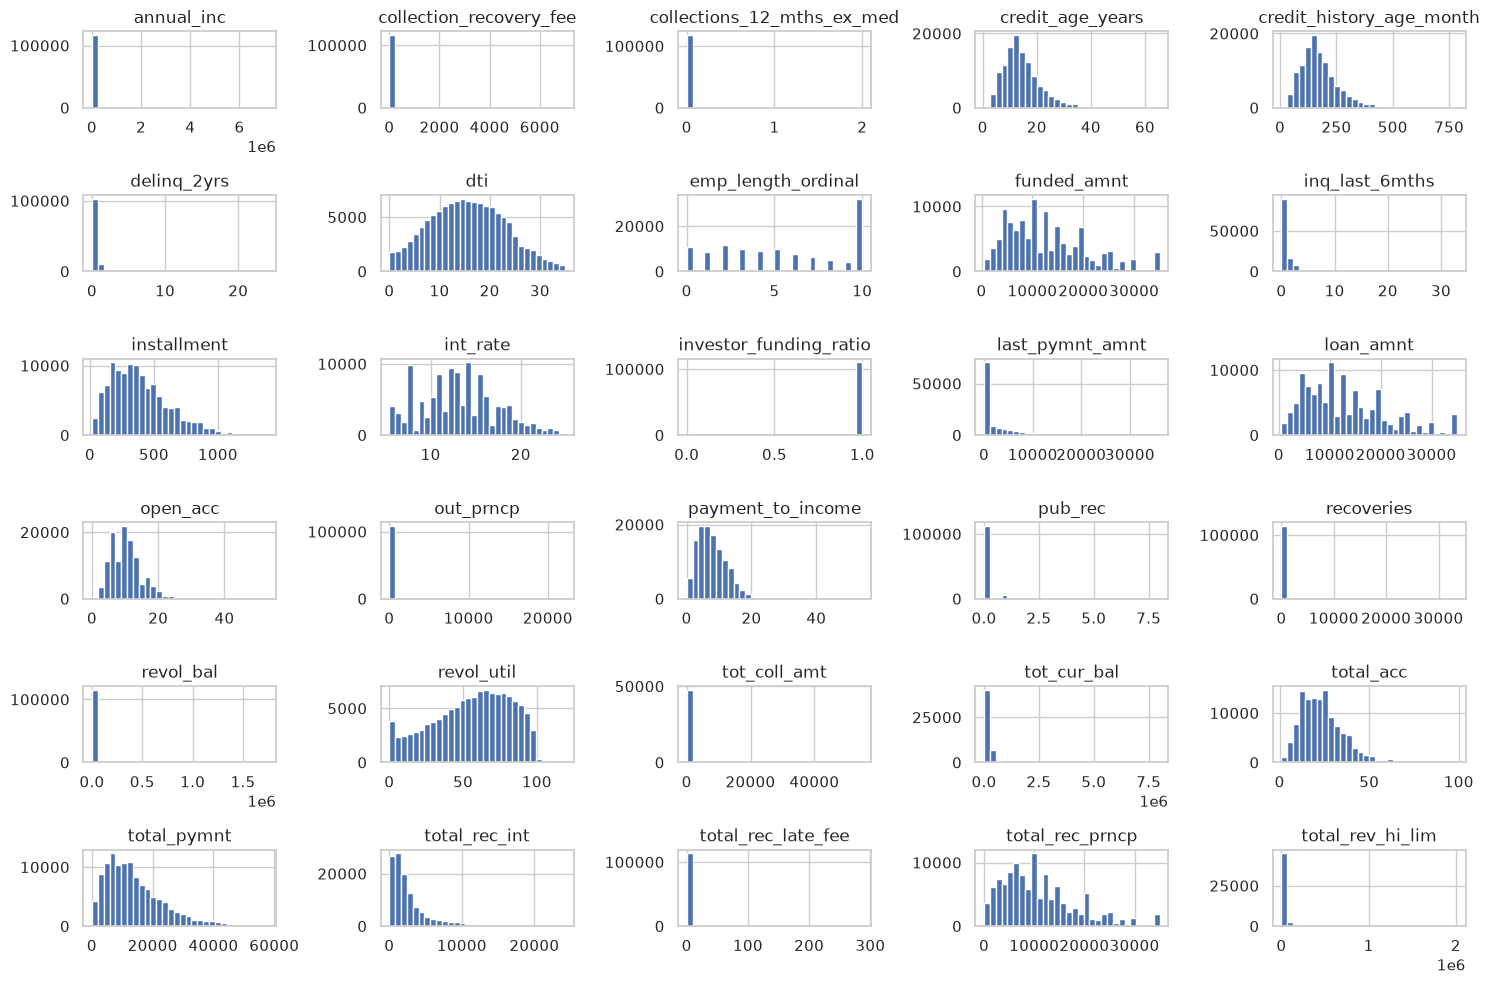

In [103]:
# Creating a histogram
df[num_cols].hist(figsize=(15, 10), bins=30)
plt.tight_layout()

# dpi=300 to ensure the image is sharp and not broken
# plt.savefig("histogram_distribusi.png", dpi=20, bbox_inches="tight")

# Display graph
plt.show()



In [104]:
plot_numeric_distributions(
    df[num_cols],
    target_col=df['target'],
)

<br>

---
### `recoveries`:

In [105]:
df['recoveries'].describe().round()

count    118066.0
mean        124.0
std         691.0
min           0.0
25%           0.0
50%           0.0
75%           0.0
max       33520.0
Name: recoveries, dtype: float64

In [106]:
df[['recoveries', 'target']].corr()

,recoveries,target
recoveries,1.000000,0.426562
target,0.426562,1.000000


<br>

---
### Multicollinearity calculation using Variance Inflation Factor from *statsmodels*:

In [107]:
from src.utils import compute_vif

compute_vif(dataframe=df, target_col='target')

NaN/inf found, row will be dropped before VIF calculation.

                   feature                     VIF
                     const             72,100.6463
                annual_inc                  1.5674
   collection_recovery_fee                  2.4195
collections_12_mths_ex_med                  1.0047
          credit_age_years                     inf
  credit_history_age_month                     inf
               delinq_2yrs                  1.0721
                       dti                  1.4646
        emp_length_ordinal                  1.0826
               funded_amnt             29,368.7875
            inq_last_6mths                  1.1648
               installment                 24.0910
                  int_rate                  2.8447
    investor_funding_ratio                  1.0112
           last_pymnt_amnt                  2.4828
                 loan_amnt             29,332.5815
                  open_acc                  2.0767
                 out_p

In [108]:
display(df[['funded_amnt', 'loan_amnt',]].sample(5))

display(df[['loan_amnt', 'funded_amnt']].corr())

print(f"Mean value:", (df['loan_amnt'] == df['funded_amnt']).mean())

,funded_amnt,loan_amnt
member_id,,
1441328,2650,2650
1859733,18000,18000
596325,11000,11000
1110261,10000,10000
1203547,4000,4000


,loan_amnt,funded_amnt
loan_amnt,1.000000,0.993925
funded_amnt,0.993925,1.000000


Mean value: 0.9825944810529704


In [109]:
df.drop(columns=[
    'funded_amnt', 'recoveries', 'total_pymnt', 'installment', 
    'total_rec_int', 'total_rec_late_fee', 'total_rec_prncp', 'credit_history_age_month'

], inplace=True)

In [110]:
compute_vif(dataframe=df, target_col='target')

NaN/inf found, row will be dropped before VIF calculation.

                   feature         VIF
                     const 71,981.3279
                annual_inc      1.5328
   collection_recovery_fee      1.0647
collections_12_mths_ex_med      1.0034
          credit_age_years      1.2852
               delinq_2yrs      1.0662
                       dti      1.4377
        emp_length_ordinal      1.0814
            inq_last_6mths      1.1509
                  int_rate      1.6615
    investor_funding_ratio      1.0096
           last_pymnt_amnt      1.4563
                 loan_amnt      3.1445
                  open_acc      2.0661
                 out_prncp      1.5223
         payment_to_income      2.2492
                   pub_rec      1.0259
                 revol_bal      6.7391
                revol_util      2.0946
              tot_coll_amt      1.0064
               tot_cur_bal      1.7329
                 total_acc      2.2067
          total_rev_hi_lim      7.2393


<br>

---
### `total_rev_hi_lim`:
Total revolving high credit/credit limit.

In [111]:
df['total_rev_hi_lim'].describe().round()

count      48029.0
mean       30039.0
std        28889.0
min            0.0
25%        14200.0
50%        23300.0
75%        37600.0
max      2013133.0
Name: total_rev_hi_lim, dtype: float64

In [112]:
print(df.loc[df['total_rev_hi_lim'] > 36100.0, ['total_rev_hi_lim']].sort_values(
    by='total_rev_hi_lim', ascending=True))

           total_rev_hi_lim
member_id                  
1545407             36104.0
3872910             36106.0
4149414             36144.0
4171475             36153.0
3865404             36156.0
...                     ...
3857099            678300.0
3977937            694400.0
3983192            757500.0
2839463            988000.0
2968117           2013133.0

[12849 rows x 1 columns]


In [113]:
df[['total_rev_hi_lim', 'target']].corr()

,total_rev_hi_lim,target
total_rev_hi_lim,1.000000,-0.047939
target,-0.047939,1.000000


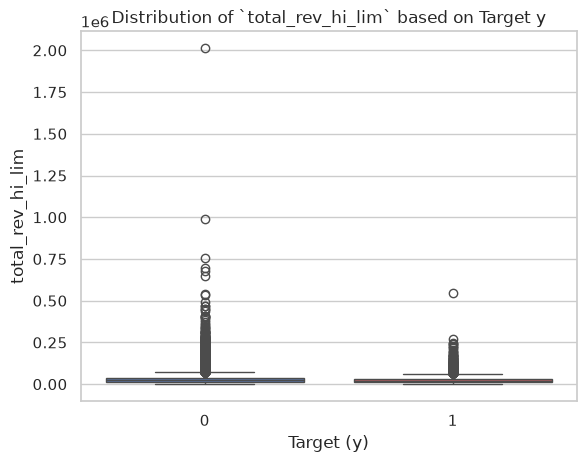

In [114]:
sns.boxplot(
    data=df,
    x='target', 
    y='total_rev_hi_lim',
    palette=TARGET_COLORS
)

plt.title(f'Distribution of `total_rev_hi_lim` based on Target y')
plt.xlabel(f'Target (y)')
plt.ylabel(f'total_rev_hi_lim')
plt.show()

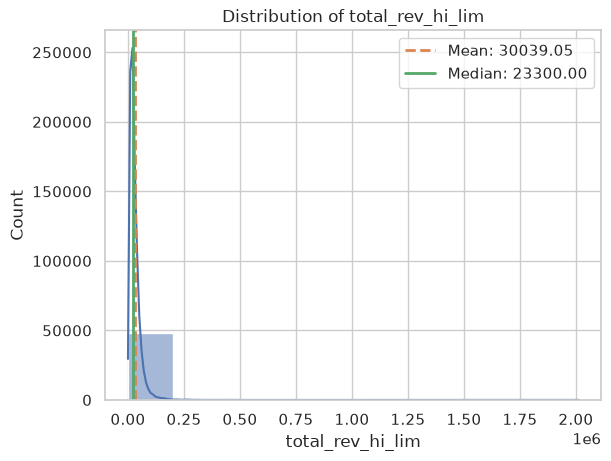

In [115]:
sns.histplot(df['total_rev_hi_lim'], bins=10, kde=True)
plt.title(f"Distribution of total_rev_hi_lim")

# Calculate mean and median
mean_val = df['total_rev_hi_lim'].mean()
median_val = df['total_rev_hi_lim'].median()

# Add vertical lines for mean (red) and median (green)
plt.axvline(mean_val, color=C_ORANGE, linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')
plt.axvline(median_val, color=C_GREEN, linestyle='-', linewidth=2, label=f'Median: {median_val:.2f}')
plt.legend()
plt.show()

<br> 

---
### `tot_cur_bal`: 
Total current balance of all accounts.

In [116]:
df['tot_cur_bal'].describe().round()

count      48029.0
mean      136268.0
std       156682.0
min            0.0
25%        27020.0
50%        74903.0
75%       206176.0
max      8000078.0
Name: tot_cur_bal, dtype: float64

In [117]:
print(df.loc[df['tot_cur_bal'] > 206214.0, ['tot_cur_bal']].sort_values(
    by='tot_cur_bal', ascending=True))

           tot_cur_bal
member_id             
4538271       206217.0
4232702       206218.0
3918367       206232.0
4421138       206241.0
1788213       206245.0
...                ...
3417245      2547166.0
4307864      2940054.0
2968117      3471522.0
3016955      4772549.0
2839463      8000078.0

[12005 rows x 1 columns]


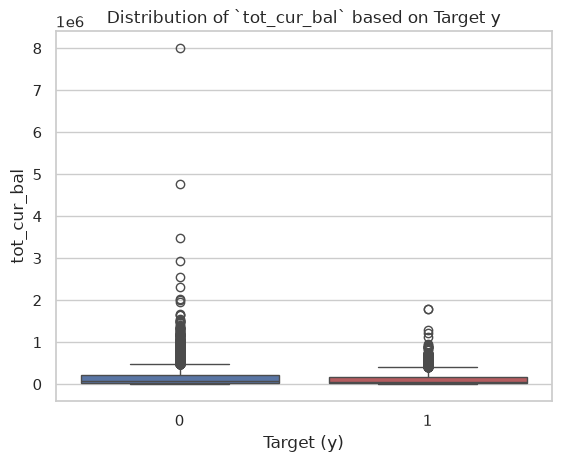

In [118]:
sns.boxplot(
    data=df,
    x='target', 
    y='tot_cur_bal',
    palette=TARGET_COLORS
)

plt.title(f'Distribution of `tot_cur_bal` based on Target y')
plt.xlabel(f'Target (y)')
plt.ylabel(f'tot_cur_bal')
plt.show()

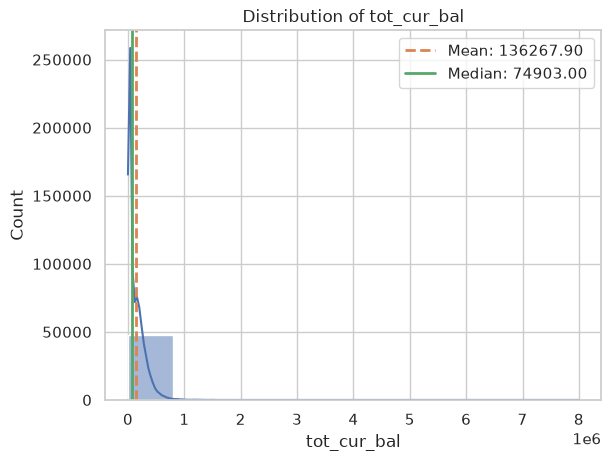

In [119]:
sns.histplot(df['tot_cur_bal'], bins=10, kde=True)
plt.title(f"Distribution of tot_cur_bal")

# Calculate mean and median
mean_val = df['tot_cur_bal'].mean()
median_val = df['tot_cur_bal'].median()

# Add vertical lines for mean (red) and median (green)
plt.axvline(mean_val, color=C_ORANGE, linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')
plt.axvline(median_val, color=C_GREEN, linestyle='-', linewidth=2, label=f'Median: {median_val:.2f}')
plt.legend()
plt.show()

In [120]:
df[['tot_cur_bal', 'target']].corr()

,tot_cur_bal,target
tot_cur_bal,1.000000,-0.051322
target,-0.051322,1.000000


In [121]:
missing_summary(df)

,Missing Values,Percentage,Total length
collections_12_mths_ex_med,115,0.10,118066
emp_length_ordinal,3814,3.23,118066
revol_util,113,0.10,118066
tot_coll_amt,70037,59.32,118066
tot_cur_bal,70037,59.32,118066
total_rev_hi_lim,70037,59.32,118066


In [122]:
def binning_credit_balances(dataframe, columns=['total_rev_hi_lim', 'tot_cur_bal']):
    """
    Perform Quantile Binning and NaN handling for balance/credit limit features.
    """
    df_processed = dataframe.copy()
    
    for col in columns:
        labels = ['Very_Low', 'Low', 'Medium', 'High', 'Very_High']
        group_col_name = f"{col}_group"
        
        # Quantile Binning with boundary duplication protection
        df_processed[group_col_name] = pd.qcut(
            df_processed[col], 
            q=5, 
            labels=labels,
            duplicates='drop'
        )
        
        # Dynamic NaN handling becomes 'Unknown'
        if df_processed[col].isnull().any():
            df_processed[group_col_name] = (
                df_processed[group_col_name]
                .cat.add_categories('Unknown')
                .fillna('Unknown')
            )
            
        # Delete the original numeric column
        # df_processed = df_processed.drop(columns=[col])
        
    return df_processed

df = binning_credit_balances(dataframe=df, columns=['total_rev_hi_lim', 'tot_cur_bal'])

total_rev_hi_lim_group
Unknown      70037
Very_Low      9635
Low           9623
Medium        9619
Very_High     9600
High          9552

Counts:
target                      0      1
total_rev_hi_lim_group              
Very_Low                 8113   1522
Low                      8049   1574
Medium                   8198   1421
High                     8236   1316
Very_High                8516   1084
Unknown                 59236  10801

Bad rate (%):
total_rev_hi_lim_group
Very_High    11.29
High         13.78
Medium       14.77
Unknown      15.42
Very_Low     15.80
Low          16.36

chi2=143.54, p=3.17e-29, dof=5


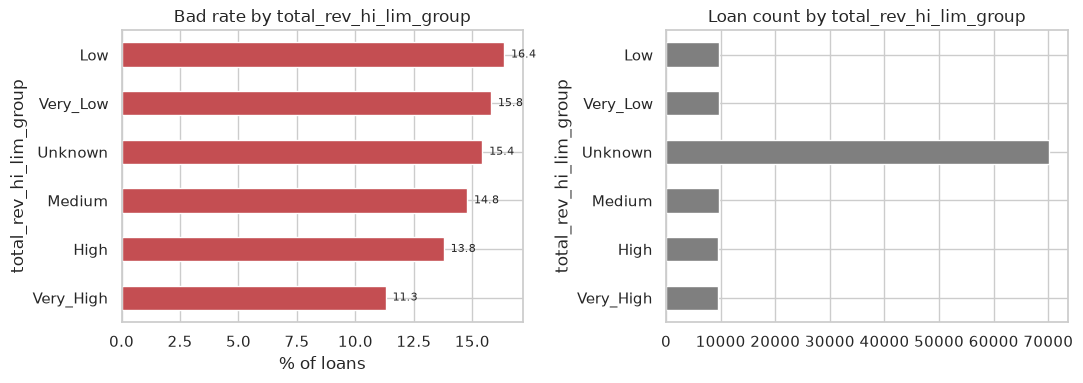

target,0,1
total_rev_hi_lim_group,,
Very_Low,8113,1522
Low,8049,1574
Medium,8198,1421
High,8236,1316
Very_High,8516,1084
Unknown,59236,10801


In [123]:
eda_profile(df, 'total_rev_hi_lim_group')


<br>

---

tot_cur_bal_group
Unknown      70037
Very_Low      9607
High          9606
Very_High     9606
Low           9605
Medium        9605

Counts:
target                 0      1
tot_cur_bal_group              
Very_Low            8124   1483
Low                 8043   1562
Medium              8166   1439
High                8244   1362
Very_High           8535   1071
Unknown            59236  10801

Bad rate (%):
tot_cur_bal_group
Very_High    11.15
High         14.18
Medium       14.98
Unknown      15.42
Very_Low     15.44
Low          16.26

chi2=139.96, p=1.82e-28, dof=5


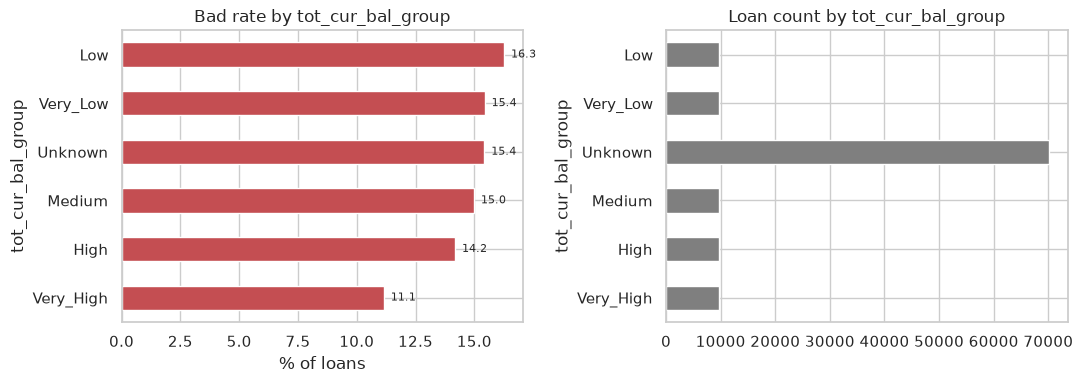

target,0,1
tot_cur_bal_group,,
Very_Low,8124,1483
Low,8043,1562
Medium,8166,1439
High,8244,1362
Very_High,8535,1071
Unknown,59236,10801


In [124]:
eda_profile(df, 'tot_cur_bal_group')


<br>

---
### `tot_coll_amt`: 
Total collection amounts ever owed.

In [125]:
print(df.loc[df['tot_coll_amt'] > 500, ['tot_coll_amt', 'target']].sort_values(by='tot_coll_amt', ascending=True))

           tot_coll_amt  target
member_id                      
3639182           502.0       0
4629000           502.0       0
1969585           502.0       0
4420546           503.0       0
3729478           503.0       0
...                 ...     ...
4230487         27304.0       0
1971670         29662.0       0
3979605         33853.0       0
1987426         43978.0       0
1807105         55009.0       0

[959 rows x 2 columns]


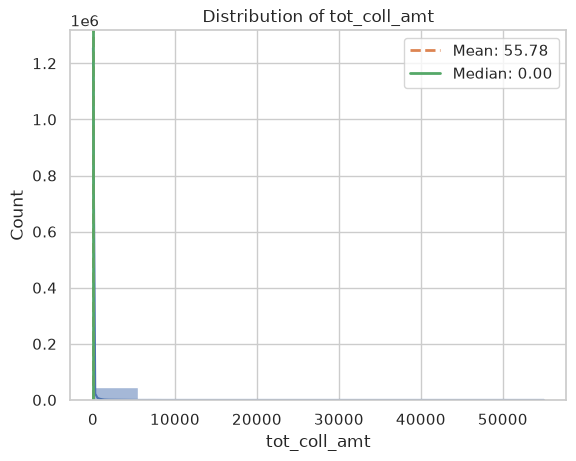

In [126]:
sns.histplot(df['tot_coll_amt'], bins=10, kde=True)
plt.title(f"Distribution of tot_coll_amt")

# Calculate mean and median
mean_val = df['tot_coll_amt'].mean()
median_val = df['tot_coll_amt'].median()

# Add vertical lines for mean (red) and median (green)
plt.axvline(mean_val, color=C_ORANGE, linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')
plt.axvline(median_val, color=C_GREEN, linestyle='-', linewidth=2, label=f'Median: {median_val:.2f}')
plt.legend()
plt.show()

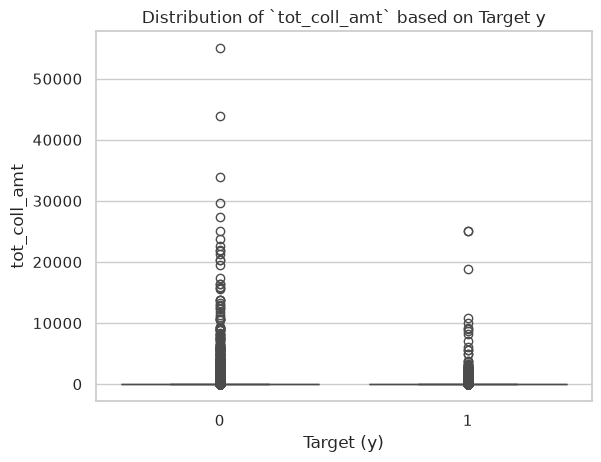

In [127]:
sns.boxplot(
    data=df,
    x='target', 
    y='tot_coll_amt',
    palette=TARGET_COLORS
)

plt.title(f'Distribution of `tot_coll_amt` based on Target y')
plt.xlabel(f'Target (y)')
plt.ylabel(f'tot_coll_amt')
plt.show()

In [128]:
df[['tot_coll_amt', 'target']].corr()

,tot_coll_amt,target
tot_coll_amt,1.000000,0.001956
target,0.001956,1.000000


In [129]:
def transform_tot_coll_amt(dataframe, col_name='tot_coll_amt'):
    df_processed = dataframe.copy()
    
    # Buat fungsi logika internal
    def group_coll_amt(val):
        if pd.isna(val):
            return 'Unknown'
        elif val == 0:
            return 'No_Collection'
        else:
            return 'Has_Collection'
            
    # Terapkan fungsi mapping
    df_processed['tot_coll_amt_group'] = df_processed[col_name].apply(group_coll_amt).astype('category')
    
    # Drop the old numeric column
    df_processed = df_processed.drop(columns=[col_name])
    
    return df_processed

df = transform_tot_coll_amt(dataframe=df, col_name='tot_coll_amt')

df['tot_coll_amt_group'].unique()

['Unknown', 'Has_Collection', 'No_Collection']
Categories (3, str): ['Has_Collection', 'No_Collection', 'Unknown']

tot_coll_amt_group
Unknown           70037
No_Collection     44871
Has_Collection     3158

Counts:
target                  0      1
tot_coll_amt_group              
Has_Collection       2675    483
No_Collection       38437   6434
Unknown             59236  10801

Bad rate (%):
tot_coll_amt_group
No_Collection     14.34
Has_Collection    15.29
Unknown           15.42

chi2=25.36, p=3.12e-06, dof=2


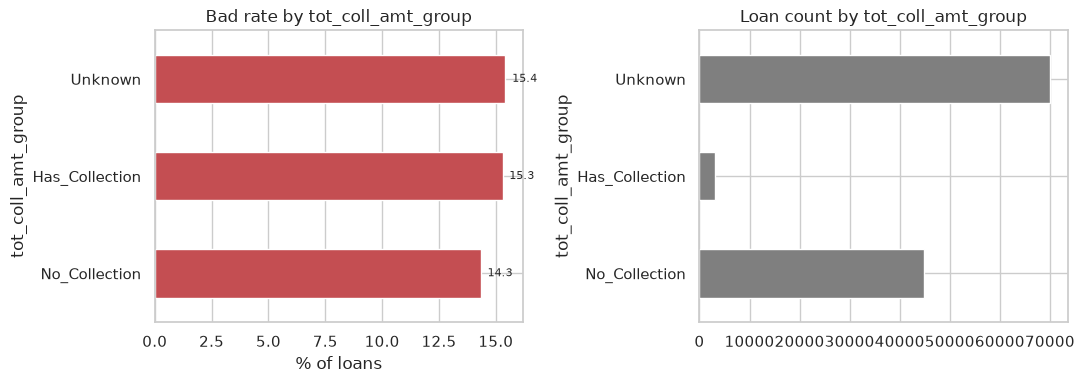

target,0,1
tot_coll_amt_group,,
Has_Collection,2675,483
No_Collection,38437,6434
Unknown,59236,10801


In [130]:
eda_profile(df, 'tot_coll_amt_group')


<br>

---
### `total_acc`: 
The total number of credit lines currently in the borrower's credit file.

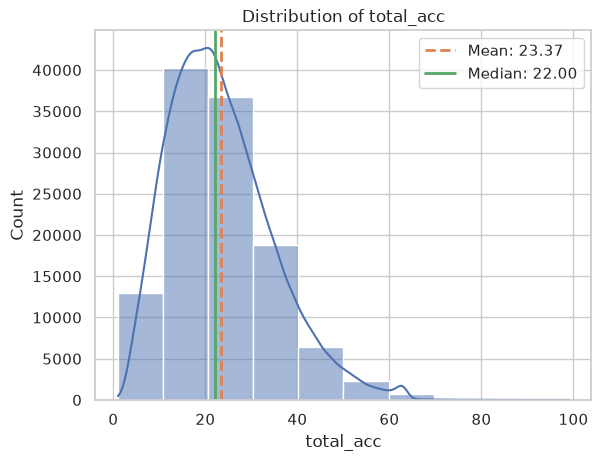

In [131]:
sns.histplot(df['total_acc'], bins=10, kde=True)
plt.title(f"Distribution of total_acc")

# Calculate mean and median
mean_val = df['total_acc'].mean()
median_val = df['total_acc'].median()

# Add vertical lines for mean (red) and median (green)
plt.axvline(mean_val, color=C_ORANGE, linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')
plt.axvline(median_val, color=C_GREEN, linestyle='-', linewidth=2, label=f'Median: {median_val:.2f}')
plt.legend()
plt.show()

In [132]:
df[['total_acc', 'target']].corr()

,total_acc,target
total_acc,1.000000,-0.016107
target,-0.016107,1.000000


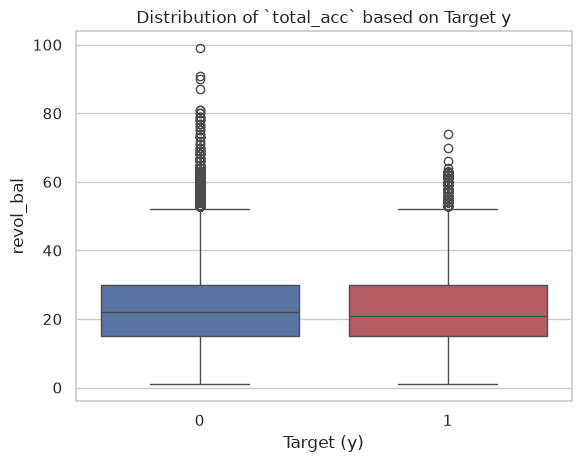

In [133]:
sns.boxplot(
    data=df,
    x='target', 
    y='total_acc',
    palette=TARGET_COLORS
)

plt.title(f'Distribution of `total_acc` based on Target y')
plt.xlabel(f'Target (y)')
plt.ylabel(f'revol_bal')
plt.show()

In [134]:
def binning_total_acc(dataframe, col_name='total_acc'):
    df_processed = dataframe.copy()
    
    # 1. Determine the interval bins limits based on quartile & business logic
    # [0-15], (15-25], (25-35], (35-999]
    bins = [0, 15, 25, 35, 999]  
    labels = ['less_15', '15_to_25', '25_to_35', 'greater_35']
    
    # 2. Do Binning using pd.cut
    df_processed['total_acc_group'] = pd.cut(
        df_processed[col_name], 
        bins=bins, 
        labels=labels
    )
    
    # 3. Dynamic Handling if there is a NaN value
    if df_processed[col_name].isnull().any():
        df_processed['total_acc_group'] = (
            df_processed['total_acc_group']
            .cat.add_categories('Unknown')
            .fillna('Unknown')
        )
    
    # 4. Delete the original numeric column
    # df_processed = df_processed.drop(columns=[col_name])
    
    return df_processed

df = binning_total_acc(dataframe=df, col_name='total_acc')

df['total_acc_group'].value_counts()

total_acc_group
15_to_25      42077
less_15       31561
25_to_35      27724
greater_35    16704
Name: count, dtype: int64

total_acc_group
15_to_25      42077
less_15       31561
25_to_35      27724
greater_35    16704

Counts:
target               0     1
total_acc_group             
less_15          26517  5044
15_to_25         35809  6268
25_to_35         23741  3983
greater_35       14281  2423

Bad rate (%):
total_acc_group
25_to_35      14.37
greater_35    14.51
15_to_25      14.90
less_15       15.98

chi2=36.12, p=7.06e-08, dof=3


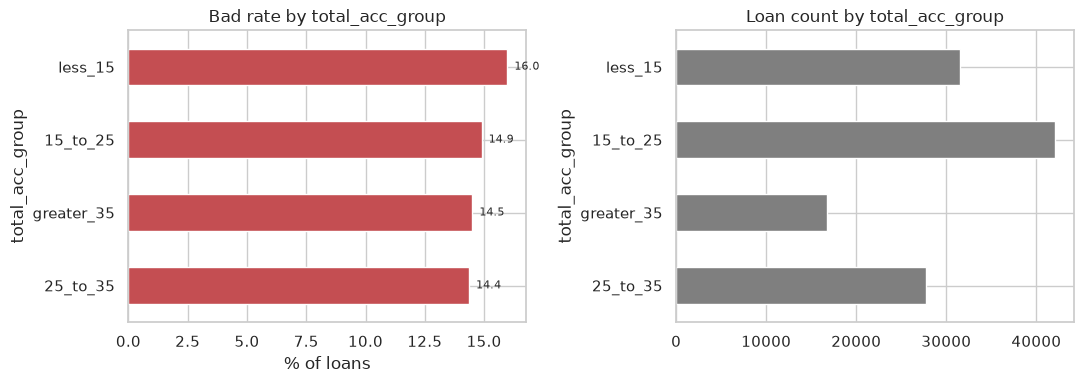

target,0,1
total_acc_group,,
less_15,26517,5044
15_to_25,35809,6268
25_to_35,23741,3983
greater_35,14281,2423


In [135]:
eda_profile(df, 'total_acc_group')


<br>

---
### `revol_bal`: 
Total credit revolving balance.

In [136]:
print(df.loc[df['revol_bal'] > 19000, ['revol_bal']].sort_values(by='revol_bal', ascending=True))

           revol_bal
member_id           
955139         19001
1219388        19002
620168         19002
1628282        19003
1810558        19005
...              ...
3983192       694615
427116        952013
2839463       975800
613380       1207359
2968117      1743266

[31231 rows x 1 columns]


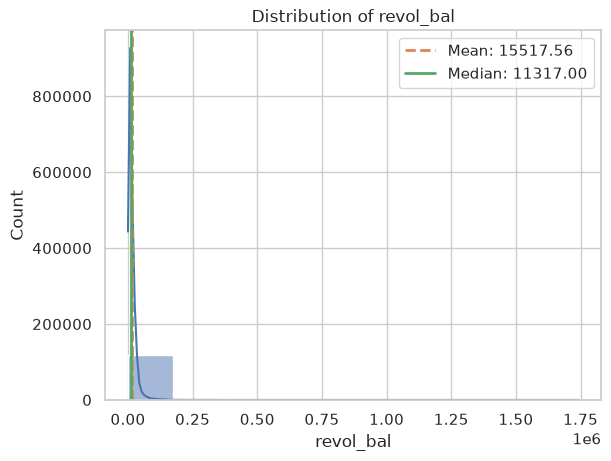

In [137]:
sns.histplot(df['revol_bal'], bins=10, kde=True)
plt.title(f"Distribution of revol_bal")

# Calculate mean and median
mean_val = df['revol_bal'].mean()
median_val = df['revol_bal'].median()

# Add vertical lines for mean (red) and median (green)
plt.axvline(mean_val, color=C_ORANGE, linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')
plt.axvline(median_val, color=C_GREEN, linestyle='-', linewidth=2, label=f'Median: {median_val:.2f}')
plt.legend()
plt.show()

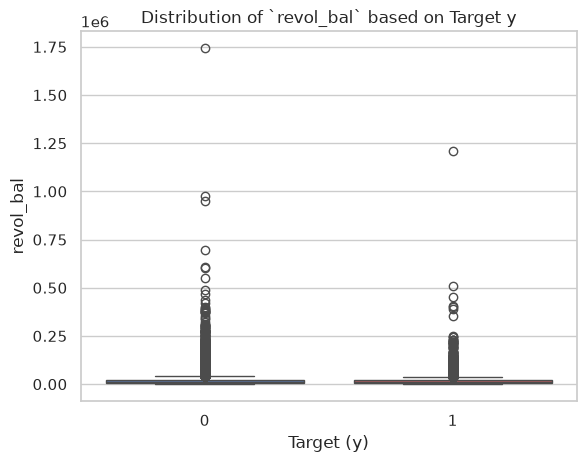

In [138]:
sns.boxplot(
    data=df,
    x='target', 
    y='revol_bal',
    palette=TARGET_COLORS
)

plt.title(f'Distribution of `revol_bal` based on Target y')
plt.xlabel(f'Target (y)')
plt.ylabel(f'revol_bal')
plt.show()

In [139]:
df[['revol_bal', 'target']].corr()

,revol_bal,target
revol_bal,1.000000,-0.002527
target,-0.002527,1.000000


In [140]:
def transform_log_revol_bal(dataframe, col_name='revol_bal'):
    """
    Apply a log1p transform to revol_bal
    to tame extreme skewness and outliers.
    """
    df_processed = dataframe.copy()
    
    # Defensive handling if there is NaN (fill with 0)
    if df_processed[col_name].isnull().any():
        df_processed[col_name] = df_processed[col_name].fillna(0)
        
    # Apply np.log1p
    df_processed['revol_bal_log'] = np.log1p(df_processed[col_name])
    
    # Delete the original column
    # df_processed = df_processed.drop(columns=[col_name])
    
    return df_processed

df = transform_log_revol_bal(dataframe=df, col_name='revol_bal')

df['revol_bal_log'].describe().round()

count    118066.0
mean          9.0
std           1.0
min           0.0
25%           9.0
50%           9.0
75%          10.0
max          14.0
Name: revol_bal_log, dtype: float64

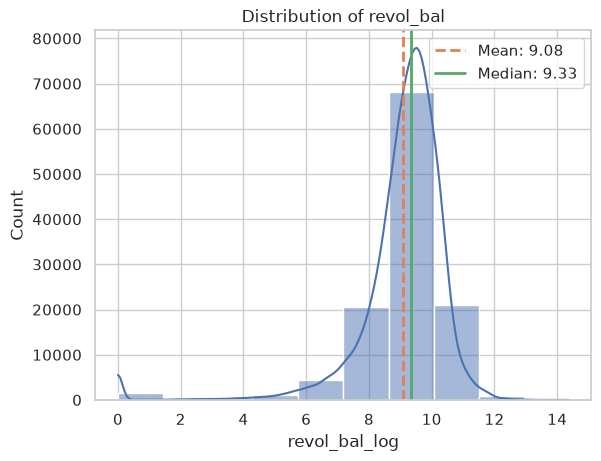

In [141]:
sns.histplot(df['revol_bal_log'], bins=10, kde=True)
plt.title(f"Distribution of revol_bal")

# Calculate mean and median
mean_val = df['revol_bal_log'].mean()
median_val = df['revol_bal_log'].median()

# Add vertical lines for mean (red) and median (green)
plt.axvline(mean_val, color=C_ORANGE, linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')
plt.axvline(median_val, color=C_GREEN, linestyle='-', linewidth=2, label=f'Median: {median_val:.2f}')
plt.legend()
plt.show()

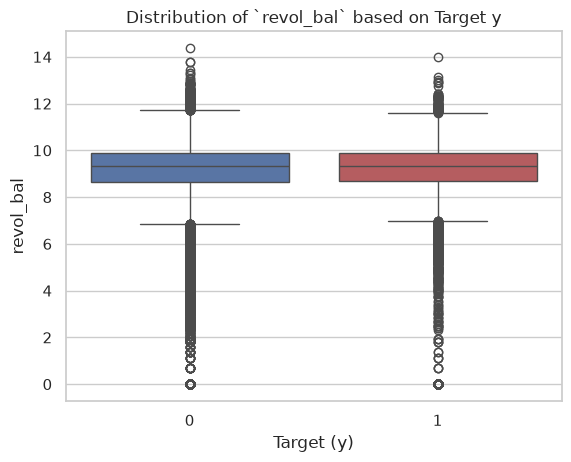

In [142]:
sns.boxplot(
    data=df,
    x='target', 
    y='revol_bal_log',
    palette=TARGET_COLORS
)

plt.title(f'Distribution of `revol_bal` based on Target y')
plt.xlabel(f'Target (y)')
plt.ylabel(f'revol_bal')
plt.show()

In [143]:
def binning_revol_bal(dataframe, col_name='revol_bal'):
    df_processed = dataframe.copy()
    
    # 1. Determine the integer interval limit (Business Logic)
    # (-1 sampai 5000], (5000 sampai 10000], dst.
    bins = [-1, 5000, 10000, 20000, 40000, np.inf]
    labels = ['0_to_5k', '5k_to_10k', '10k_to_20k', '20k_to_40k', 'greater_40k']
    
    # 2. Apply binning
    df_processed['revol_bal_group'] = pd.cut(
        df_processed[col_name], 
        bins=bins, 
        labels=labels
    )
    
    # 3. Dynamic Handling if there is a NaN value
    if df_processed[col_name].isnull().any():
        df_processed['revol_bal_group'] = (
            df_processed['revol_bal_group']
            .cat.add_categories('Unknown')
            .fillna('Unknown')
        )
    
    # 4. Delete the original numeric column
    # df_processed = df_processed.drop(columns=[col_name])
    
    return df_processed

df = binning_revol_bal(dataframe=df, col_name='revol_bal')

df['revol_bal_group'].value_counts(normalize=True)

revol_bal_group
10k_to_20k     0.311605
5k_to_10k      0.235123
0_to_5k        0.209908
20k_to_40k     0.193189
greater_40k    0.050175
Name: proportion, dtype: float64

revol_bal_group
10k_to_20k     36790
5k_to_10k      27760
0_to_5k        24783
20k_to_40k     22809
greater_40k     5924

Counts:
target               0     1
revol_bal_group             
0_to_5k          21255  3528
5k_to_10k        23484  4276
10k_to_20k       31061  5729
20k_to_40k       19475  3334
greater_40k       5073   851

Bad rate (%):
revol_bal_group
0_to_5k        14.24
greater_40k    14.37
20k_to_40k     14.62
5k_to_10k      15.40
10k_to_20k     15.57

chi2=28.83, p=8.47e-06, dof=4


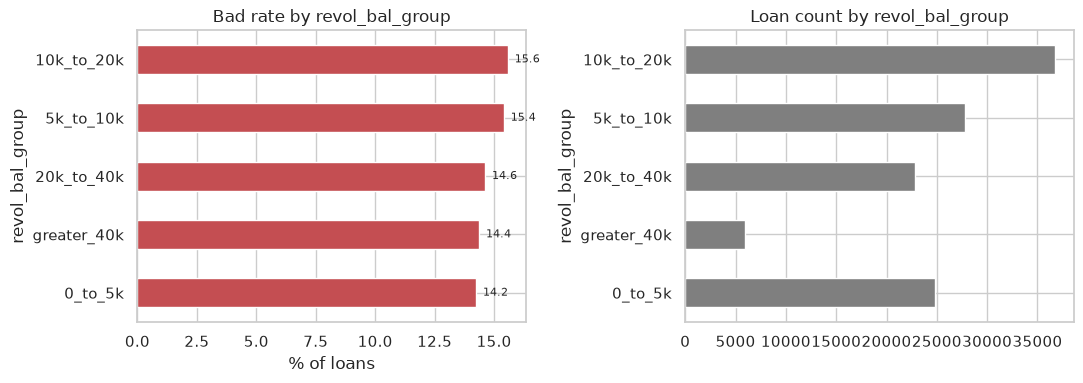

target,0,1
revol_bal_group,,
0_to_5k,21255,3528
5k_to_10k,23484,4276
10k_to_20k,31061,5729
20k_to_40k,19475,3334
greater_40k,5073,851


In [144]:
eda_profile(df, 'revol_bal_group')


<br>

### New Feature: `revol_bal_to_income`

count    118066.000000
mean          0.233175
std           0.195287
min           0.000000
25%           0.102500
50%           0.193347
75%           0.314610
max           4.358165
Name: revol_bal_to_income, dtype: float64

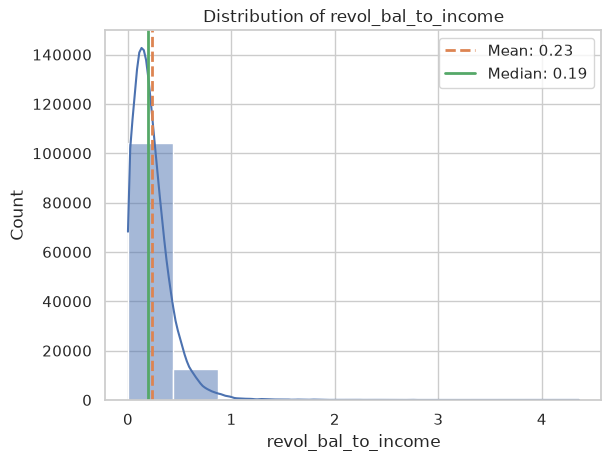

In [145]:
df['revol_bal_to_income'] = df['revol_bal'] / df['annual_inc']

display(df.revol_bal_to_income.describe())

sns.histplot(df.revol_bal_to_income, bins=10, kde=True)
plt.title(f"Distribution of revol_bal_to_income")

# Calculate mean and median
mean_val = df['revol_bal_to_income'].mean()
median_val = df['revol_bal_to_income'].median()

# Add vertical lines for mean (red) and median (green)
plt.axvline(mean_val, color=C_ORANGE, linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')
plt.axvline(median_val, color=C_GREEN, linestyle='-', linewidth=2, label=f'Median: {median_val:.2f}')
plt.legend()
plt.show()

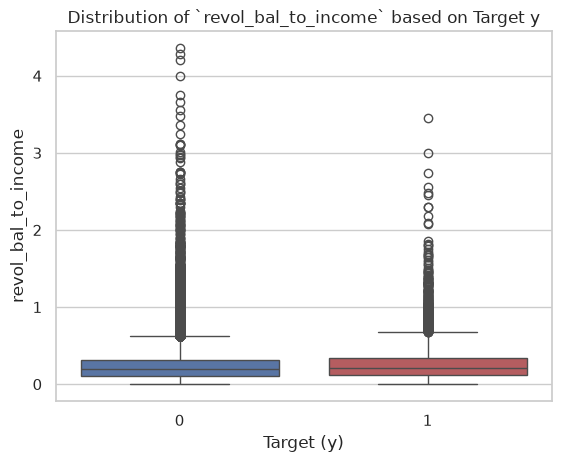

In [146]:
sns.boxplot(
    data=df,
    x='target', 
    y='revol_bal_to_income',
    palette=TARGET_COLORS
)

plt.title(f'Distribution of `revol_bal_to_income` based on Target y')
plt.xlabel(f'Target (y)')
plt.ylabel(f'revol_bal_to_income')
plt.show()

<br>

---
### `revol_util`: 
Revolving line utilization rate, or the amount of credit the borrower is using relative to all available revolving credit.

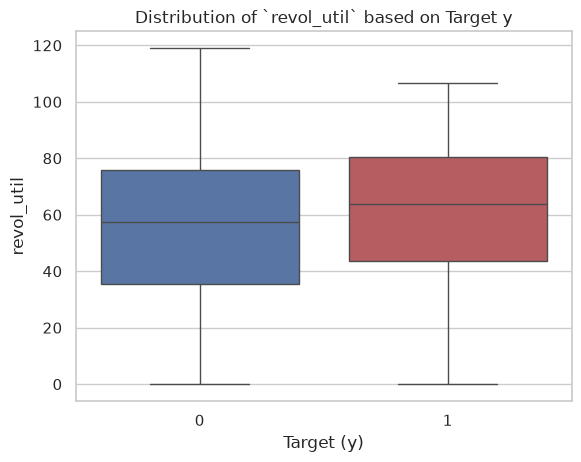

In [147]:
sns.boxplot(
    data=df,
    x='target', 
    y='revol_util',
    palette=TARGET_COLORS
)

plt.title(f'Distribution of `revol_util` based on Target y')
plt.xlabel(f'Target (y)')
plt.ylabel(f'revol_util')
plt.show()

In [148]:
print(df.loc[df['revol_util'] > 100, ['revol_util']].sort_values(by='revol_util', ascending=True))

           revol_util
member_id            
4060552         100.1
4380320         100.2
4154246         100.2
988052          100.3
3982659         100.3
...               ...
354189          106.4
229639          106.5
346211          108.8
3418601         113.9
151522          119.0

[71 rows x 1 columns]


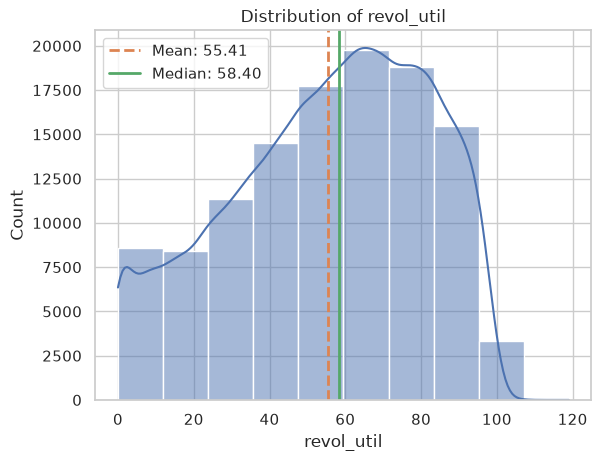

In [149]:
sns.histplot(df['revol_util'], bins=10, kde=True)
plt.title(f"Distribution of revol_util")

# Calculate mean and median
mean_val = df['revol_util'].mean()
median_val = df['revol_util'].median()

# Add vertical lines for mean (red) and median (green)
plt.axvline(mean_val, color=C_ORANGE, linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')
plt.axvline(median_val, color=C_GREEN, linestyle='-', linewidth=2, label=f'Median: {median_val:.2f}')
plt.legend()
plt.show()

In [150]:
df[['revol_util', 'target']].corr()

,revol_util,target
revol_util,1.000000,0.078004
target,0.078004,1.000000


In [151]:
def binning_revol_util(dataframe, col_name='revol_util'):
    df_processed = dataframe.copy()
    
    # 1. Determine the interval bin limits (in percent)
    # (-0.01 to 20], (20 to 40], (40 to 60], (60 to 80], (80 to 100], (100 to 9999]
    # Lower bound -0.01 so that 0.0 falls into the first bin
    bins = [-0.01, 20.0, 40.0, 60.0, 80.0, 100.0, 9999.0]  
    labels = ['0_to_20', '20_to_40', '40_to_60', '60_to_80', '80_to_100', 'greater_100']
    
    # 2. Perform Binning using pd.cut
    df_processed['revol_util_group'] = pd.cut(
        df_processed[col_name], 
        bins=bins, 
        labels=labels
    )
    
    # 3. Dynamic Conditioning: Only add 'Unknown' category if there is NaN data
    if df_processed[col_name].isnull().any():
        df_processed['revol_util_group'] = (
            df_processed['revol_util_group']
            .cat.add_categories('Unknown')
            .fillna('Unknown')
        )
    
    # 4. Remove old column
    # df_processed = df_processed.drop(columns=[col_name])
    
    return df_processed

df = binning_revol_util(dataframe=df, col_name='revol_util')

df['revol_util_group'].unique()

['80_to_100', '0_to_20', '20_to_40', '40_to_60', '60_to_80', 'Unknown', 'greater_100']
Categories (7, str): ['0_to_20' < '20_to_40' < '40_to_60' < '60_to_80' < '80_to_100' < 'greater_100' < 'Unknown']

revol_util_group
60_to_80       32593
40_to_60       28304
80_to_100      23724
20_to_40       19115
0_to_20        14146
Unknown          113
greater_100       71

Counts:
target                0     1
revol_util_group             
0_to_20           12717  1429
20_to_40          16736  2379
40_to_60          24179  4125
60_to_80          27332  5261
80_to_100         19246  4478
greater_100          52    19
Unknown              86    27

Bad rate (%):
revol_util_group
0_to_20        10.10
20_to_40       12.45
40_to_60       14.57
60_to_80       16.14
80_to_100      18.88
Unknown        23.89
greater_100    26.76

chi2=695.25, p=6.5e-147, dof=6


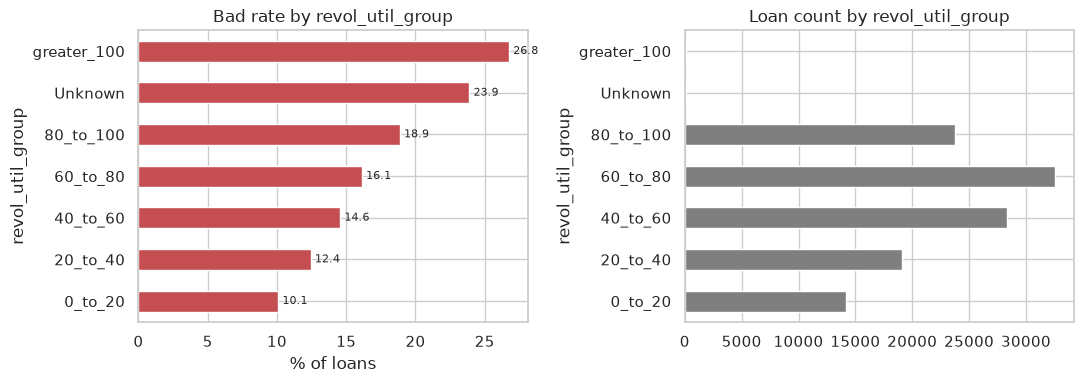

target,0,1
revol_util_group,,
0_to_20,12717,1429
20_to_40,16736,2379
40_to_60,24179,4125
60_to_80,27332,5261
80_to_100,19246,4478
greater_100,52,19
Unknown,86,27


In [152]:
eda_profile(df, 'revol_util_group')

<br>

---
### `open_acc`: 
The number of open credit lines in the borrower's credit file.

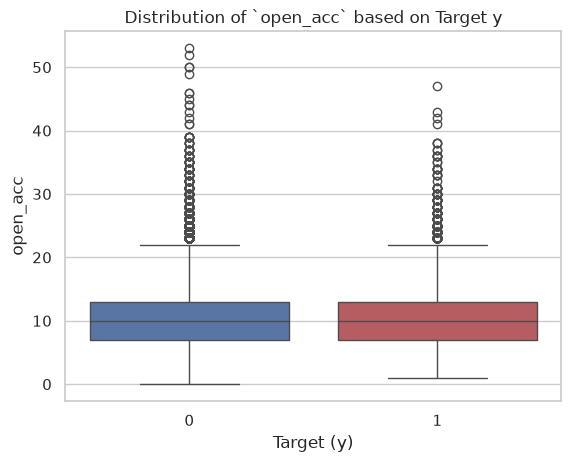

In [153]:
sns.boxplot(
    data=df,
    x='target', 
    y='open_acc',
    palette=TARGET_COLORS
)

plt.title(f'Distribution of `open_acc` based on Target y')
plt.xlabel(f'Target (y)')
plt.ylabel(f'open_acc')
plt.show()

In [154]:
df.loc[df['open_acc'] > 50, ['open_acc']].sort_values(by='open_acc', ascending=True)

,open_acc
member_id,
3768265,52.0
3546851,53.0


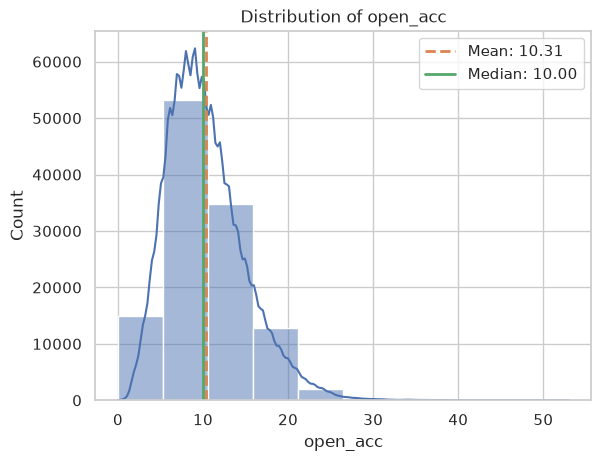

In [155]:
sns.histplot(df['open_acc'], bins=10, kde=True)
plt.title(f"Distribution of open_acc")

# Calculate mean and median
mean_val = df['open_acc'].mean()
median_val = df['open_acc'].median()

# Add vertical lines for mean (red) and median (green)
plt.axvline(mean_val, color=C_ORANGE, linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')
plt.axvline(median_val, color=C_GREEN, linestyle='-', linewidth=2, label=f'Median: {median_val:.2f}')
plt.legend()
plt.show()

count    118066.000
mean         10.309
std           4.580
min           0.000
25%           7.000
50%          10.000
75%          13.000
max          53.000

Counts:
target             0     1
open_acc                  
(-0.001, 5.0]  12599  2277
(5.0, 6.0]      8101  1340
(6.0, 8.0]     18671  3177
(8.0, 9.0]      9758  1664
(9.0, 10.0]     8885  1558
(10.0, 11.0]    8032  1455
(11.0, 12.0]    7030  1249
(12.0, 14.0]   10574  1904
(14.0, 16.0]    6948  1237
(16.0, 53.0]    9750  1857

Bad rate (%):
open_acc
(5.0, 6.0]       14.19
(6.0, 8.0]       14.54
(8.0, 9.0]       14.57
(9.0, 10.0]      14.92
(11.0, 12.0]     15.09
(14.0, 16.0]     15.11
(12.0, 14.0]     15.26
(-0.001, 5.0]    15.31
(10.0, 11.0]     15.34
(16.0, 53.0]     16.00

chi2=21.94, p=0.00906, dof=9


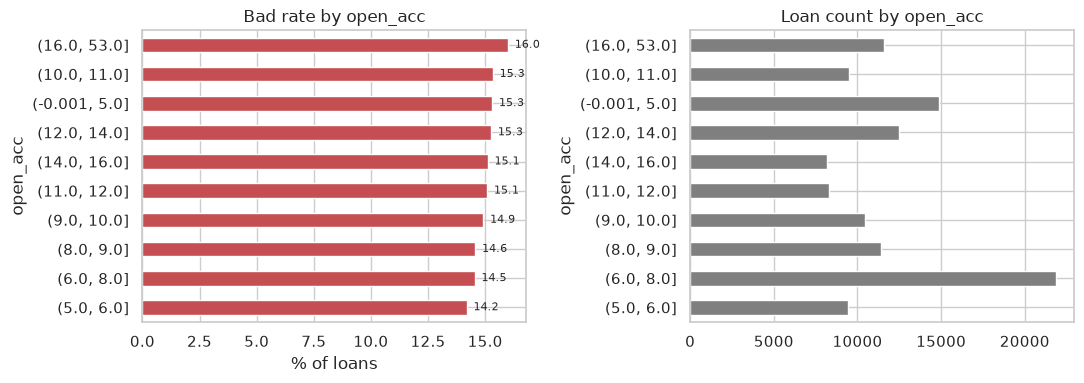

target,0,1
open_acc,,
"(-0.001, 5.0]",12599,2277
"(5.0, 6.0]",8101,1340
"(6.0, 8.0]",18671,3177
"(8.0, 9.0]",9758,1664
"(9.0, 10.0]",8885,1558
"(10.0, 11.0]",8032,1455
"(11.0, 12.0]",7030,1249
"(12.0, 14.0]",10574,1904
"(14.0, 16.0]",6948,1237


In [156]:
eda_profile(df, 'open_acc')


<br>

Based on the curve analysis above, we can divide them into 5 groups:

* 0 to 3 (Lack of experience)
* 4 to 8 (Optimal / Sweet Spot)
* 9 to 14 (Quite a lot)
* 15 to 21 (Very a lot)
* 22 or more (Over-leveraged / Too much debt)

In [157]:
def binning_open_acc(dataframe, col_name='open_acc'):
    df_processed = dataframe.copy()
    
    # Define the interval bins limits
    # (-1 to 3], (3 to 8], (8 to 14], (14 to 21], (21 to 100+]
    bins = [-1, 3, 8, 14, 21, 999]  
    labels = ['0_to_3', '4_to_8', '9_to_14', '15_to_21', '22_or_more']
    
    # Perform Binning using pd.cut
    df_processed['open_acc_group'] = pd.cut(
        df_processed[col_name], 
        bins=bins, 
        labels=labels
    )
    
    # Dynamic Conditioning: Only add 'Unknown' if there is NaN
    if df_processed[col_name].isnull().any():
        df_processed['open_acc_group'] = (
            df_processed['open_acc_group']
            .cat.add_categories('Unknown')
            .fillna('Unknown')
        )

    df_processed['open_acc_group'] = df_processed['open_acc_group'].astype('category')
    
    # Delete old columns
    # df_processed = df_processed.drop(columns=[col_name])
    
    return df_processed

df = binning_open_acc(dataframe=df, col_name='open_acc')

df['open_acc_group'].unique()

['0_to_3', '9_to_14', '15_to_21', '4_to_8', '22_or_more']
Categories (5, str): ['0_to_3' < '4_to_8' < '9_to_14' < '15_to_21' < '22_or_more']

open_acc_group
9_to_14       52109
4_to_8        42638
15_to_21      17384
0_to_3         3527
22_or_more     2408

Counts:
target              0     1
open_acc_group             
0_to_3           2903   624
4_to_8          36468  6170
9_to_14         44279  7830
15_to_21        14709  2675
22_or_more       1989   419

Bad rate (%):
open_acc_group
4_to_8        14.47
9_to_14       15.03
15_to_21      15.39
22_or_more    17.40
0_to_3        17.69

chi2=42.36, p=1.41e-08, dof=4


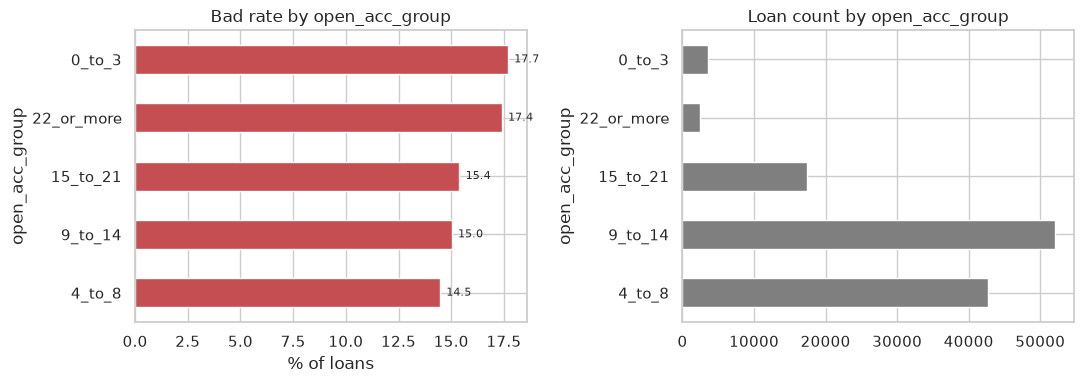

target,0,1
open_acc_group,,
0_to_3,2903,624
4_to_8,36468,6170
9_to_14,44279,7830
15_to_21,14709,2675
22_or_more,1989,419


In [158]:
eda_profile(df, 'open_acc_group')


<br>

### New Feature: `open_acc_ratio`

count    118066.000000
mean          0.485603
std           0.179334
min           0.000000
25%           0.352941
50%           0.461538
75%           0.600000
max           1.750000
Name: open_acc_ratio, dtype: float64

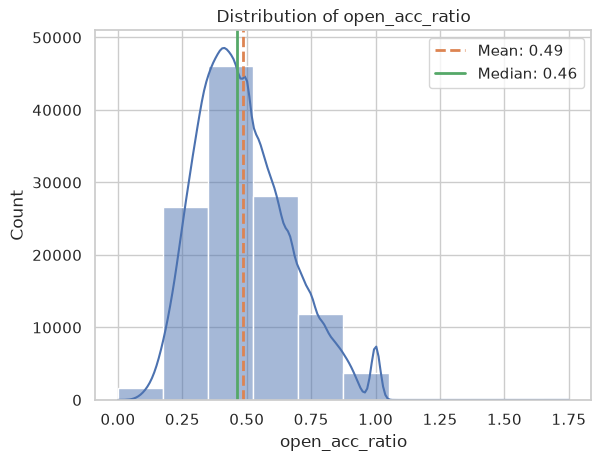

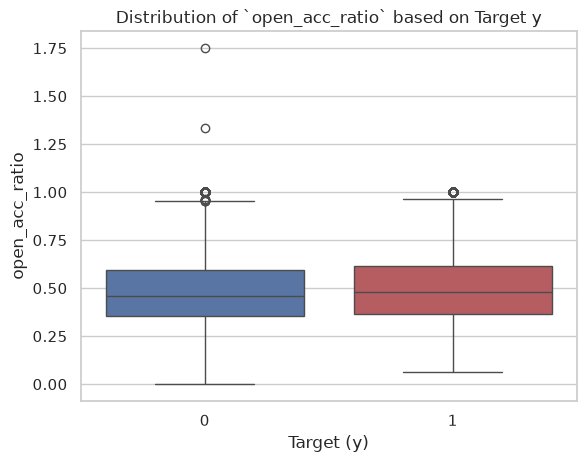

In [159]:
df['open_acc_ratio'] = df['open_acc'] / df['total_acc'].replace(0, np.nan)  # avoid div by zero

display(df['open_acc_ratio'].describe())

sns.histplot(df['open_acc_ratio'], bins=10, kde=True)
plt.title(f"Distribution of open_acc_ratio")

# Calculate mean and median
mean_val = df['open_acc_ratio'].mean()
median_val = df['open_acc_ratio'].median()

# Add vertical lines for mean (red) and median (green)
plt.axvline(mean_val, color=C_ORANGE, linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')
plt.axvline(median_val, color=C_GREEN, linestyle='-', linewidth=2, label=f'Median: {median_val:.2f}')
plt.legend()
plt.show()


sns.boxplot(
    data=df,
    x='target', 
    y='open_acc_ratio',
    palette=TARGET_COLORS
)

plt.title(f'Distribution of `open_acc_ratio` based on Target y')
plt.xlabel(f'Target (y)')
plt.ylabel(f'open_acc_ratio')
plt.show()

<br>

---
### `dti` (Debt to Income):

In [160]:
df['dti'].describe()

count    118066.000000
mean         15.671443
std           7.510958
min           0.000000
25%          10.070000
50%          15.510000
75%          21.030000
max          34.990000
Name: dti, dtype: float64

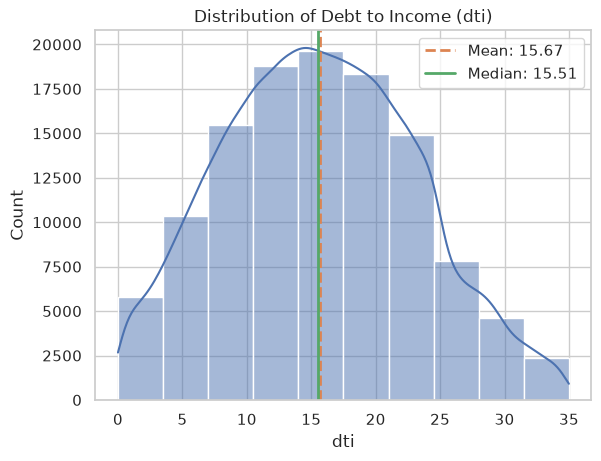

In [161]:
sns.histplot(df['dti'], bins=10, kde=True)
plt.title(f"Distribution of Debt to Income (dti)")

# Calculate mean and median
mean_val = df['dti'].mean()
median_val = df['dti'].median()

# Add vertical lines for mean (red) and median (green)
plt.axvline(mean_val, color=C_ORANGE, linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')
plt.axvline(median_val, color=C_GREEN, linestyle='-', linewidth=2, label=f'Median: {median_val:.2f}')
plt.legend()
plt.show()

<br>

---
### `loan_amnt`:

In [162]:
df['loan_amnt'].describe()

count    118066.000000
mean      13001.152533
std        8020.994699
min         500.000000
25%        6800.000000
50%       11200.000000
75%       18000.000000
max       35000.000000
Name: loan_amnt, dtype: float64

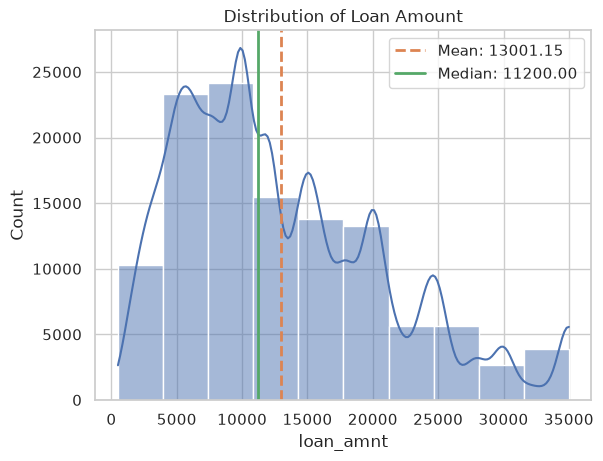

In [163]:
sns.histplot(df['loan_amnt'], bins=10, kde=True)
plt.title(f"Distribution of Loan Amount")

# Calculate mean and median
mean_val = df['loan_amnt'].mean()
median_val = df['loan_amnt'].median()

# Add vertical lines for mean (red) and median (green)
plt.axvline(mean_val, color=C_ORANGE, linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')
plt.axvline(median_val, color=C_GREEN, linestyle='-', linewidth=2, label=f'Median: {median_val:.2f}')
plt.legend()
plt.show()

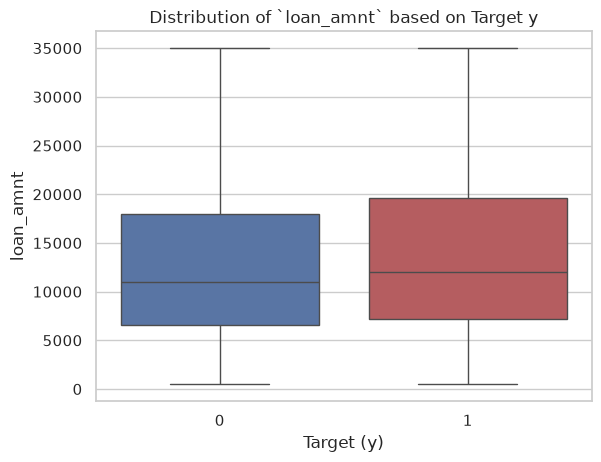

In [164]:
sns.boxplot(
    data=df,
    x='target', 
    y='loan_amnt',
    palette=TARGET_COLORS
)

plt.title(f'Distribution of `loan_amnt` based on Target y')
plt.xlabel(f'Target (y)')
plt.ylabel(f'loan_amnt')
plt.show()

<br>

### New Feature: `loan_to_income`

count    118066.000000
mean          0.207851
std           0.114744
min           0.000789
25%           0.117647
50%           0.192000
75%           0.284615
max           1.337500
Name: loan_to_income, dtype: float64

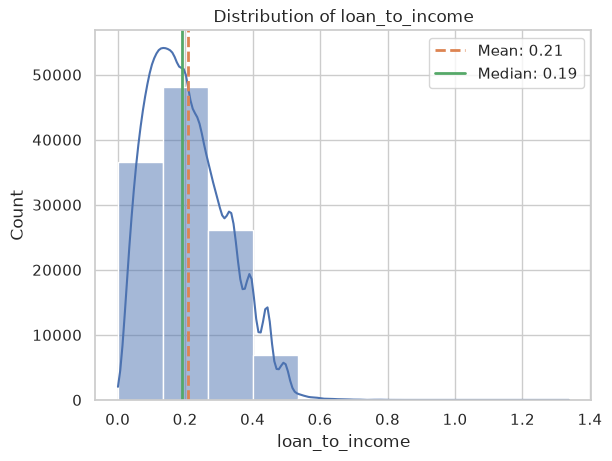

In [165]:
df['loan_to_income'] = df['loan_amnt'] / df['annual_inc']

display(df['loan_to_income'].describe())

sns.histplot(df['loan_to_income'], bins=10, kde=True)
plt.title(f"Distribution of loan_to_income")

# Calculate mean and median
mean_val = df['loan_to_income'].mean()
median_val = df['loan_to_income'].median()

# Add vertical lines for mean (red) and median (green)
plt.axvline(mean_val, color=C_ORANGE, linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')
plt.axvline(median_val, color=C_GREEN, linestyle='-', linewidth=2, label=f'Median: {median_val:.2f}')
plt.legend()
plt.show()

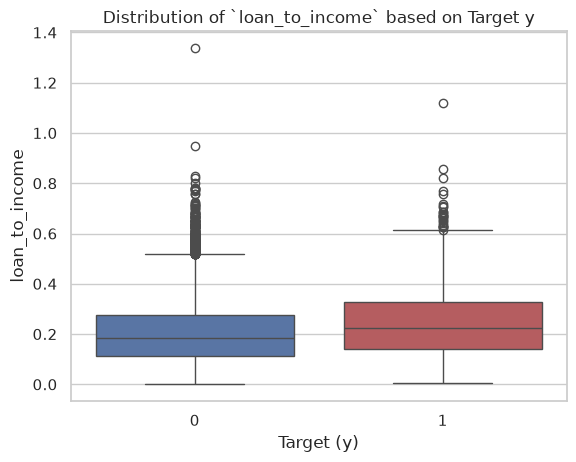

In [166]:
sns.boxplot(
    data=df,
    x='target', 
    y='loan_to_income',
    palette=TARGET_COLORS
)

plt.title(f'Distribution of `loan_to_income` based on Target y')
plt.xlabel(f'Target (y)')
plt.ylabel(f'loan_to_income')
plt.show()

<br>

---
### `annual_inc`: 
The self-reported annual income provided by the borrower during registration.

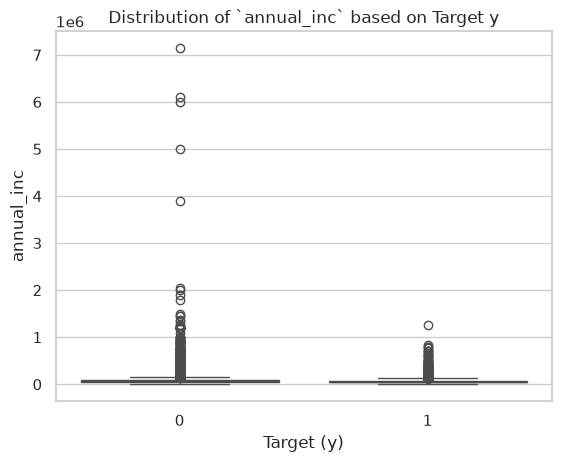

In [167]:
sns.boxplot(
    data=df,
    x='target', 
    y='annual_inc',
    palette=TARGET_COLORS
)

plt.title(f'Distribution of `annual_inc` based on Target y')
plt.xlabel(f'Target (y)')
plt.ylabel(f'annual_inc')
plt.show()

In [168]:
print(df.loc[df['annual_inc'] > 1500000, ['annual_inc']].sort_values(by='annual_inc', ascending=True))

           annual_inc
member_id            
1100269     1782000.0
784585      1900000.0
3983192     2000000.0
267741      2039784.0
672152      3900000.0
2839463     5000000.0
663575      6000000.0
3979312     6100000.0
3267055     7141778.0


In [169]:
def binning_annual_inc(dataframe, col_name='annual_inc'):
    df_processed = dataframe.copy()
    
    # 1. Use pd.qcut to split into 5 equal-population groups
    # q=5 means quintiles (~20% of data each)
    labels = ['Very_Low', 'Low', 'Medium', 'High', 'Very_High']
    
    df_processed['annual_inc_group'] = pd.qcut(
        df_processed[col_name], 
        q=5, 
        labels=labels
    )
    
    # 2. Add an 'Unknown' category only if NaN values exist
    if df_processed[col_name].isnull().any():
        df_processed['annual_inc_group'] = (
            df_processed['annual_inc_group']
            .cat.add_categories('Unknown')
            .fillna('Unknown')
        )
    
    # 3. Drop the old continuous column
    # df_processed = df_processed.drop(columns=[col_name])
    
    return df_processed

df = binning_annual_inc(dataframe=df, col_name='annual_inc')

df['annual_inc_group'].unique()

['Very_Low', 'Low', 'High', 'Very_High', 'Medium']
Categories (5, str): ['Very_Low' < 'Low' < 'Medium' < 'High' < 'Very_High']

annual_inc_group
Very_Low     25882
High         23729
Medium       23603
Very_High    23473
Low          21379

Counts:
target                0     1
annual_inc_group             
Very_Low          21140  4742
Low               17854  3525
Medium            19967  3636
High              20500  3229
Very_High         20887  2586

Bad rate (%):
annual_inc_group
Very_High    11.02
High         13.61
Medium       15.40
Low          16.49
Very_Low     18.32

chi2=592.06, p=8.12e-127, dof=4


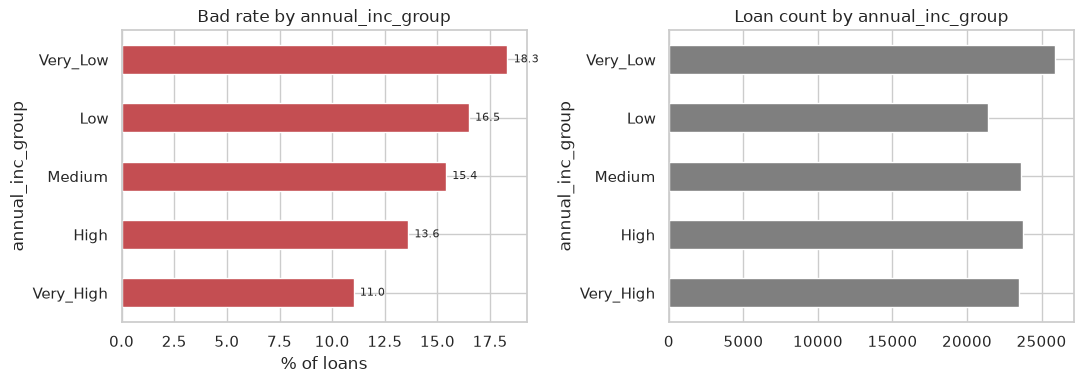

target,0,1
annual_inc_group,,
Very_Low,21140,4742
Low,17854,3525
Medium,19967,3636
High,20500,3229
Very_High,20887,2586


In [170]:
eda_profile(df, 'annual_inc_group')

<br>

---
### `collection_recovery_fee`:

In [171]:
df['collection_recovery_fee'].describe()

count    118066.000000
mean         11.376562
std         114.969000
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max        7002.190000
Name: collection_recovery_fee, dtype: float64

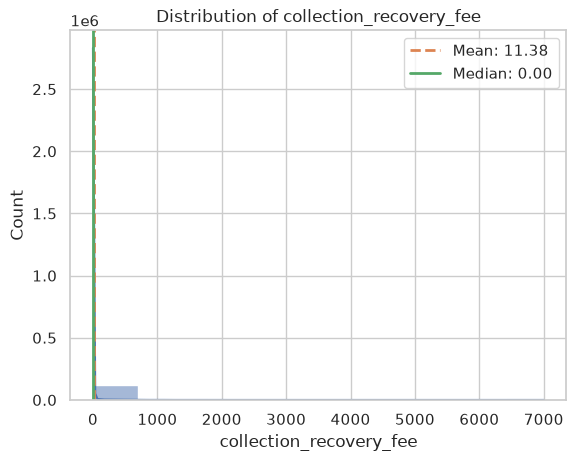

In [172]:
sns.histplot(df['collection_recovery_fee'], bins=10, kde=True)
plt.title(f"Distribution of collection_recovery_fee")

# Calculate mean and median
mean_val = df['collection_recovery_fee'].mean()
median_val = df['collection_recovery_fee'].median()

# Add vertical lines for mean (red) and median (green)
plt.axvline(mean_val, color=C_ORANGE, linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')
plt.axvline(median_val, color=C_GREEN, linestyle='-', linewidth=2, label=f'Median: {median_val:.2f}')
plt.legend()
plt.show()

In [173]:
df.loc[df['collection_recovery_fee'] > 2000, ['collection_recovery_fee']].sort_values(
    by='collection_recovery_fee', ascending=True)

,collection_recovery_fee
member_id,
4722154,2035.3573
3960752,2040.0000
1391883,2040.0000
1262418,2043.1800
735690,2063.0600
...,...
548857,5602.7200
516005,5774.8000
426030,6543.0400


<br>

---
### `inq_last_6mths`: 
The number of inquiries in past 6 months (excluding auto and mortgage inquiries)

count    118066.000
mean          0.920
std           1.234
min           0.000
25%           0.000
50%           1.000
75%           1.000
max          33.000

Counts:
target              0      1
inq_last_6mths              
(-0.001, 1.0]   77439  12284
(1.0, 2.0]      13661   2939
(2.0, 33.0]      9248   2495

Bad rate (%):
inq_last_6mths
(-0.001, 1.0]    13.69
(1.0, 2.0]       17.70
(2.0, 33.0]      21.25

chi2=575.00, p=1.38e-125, dof=2


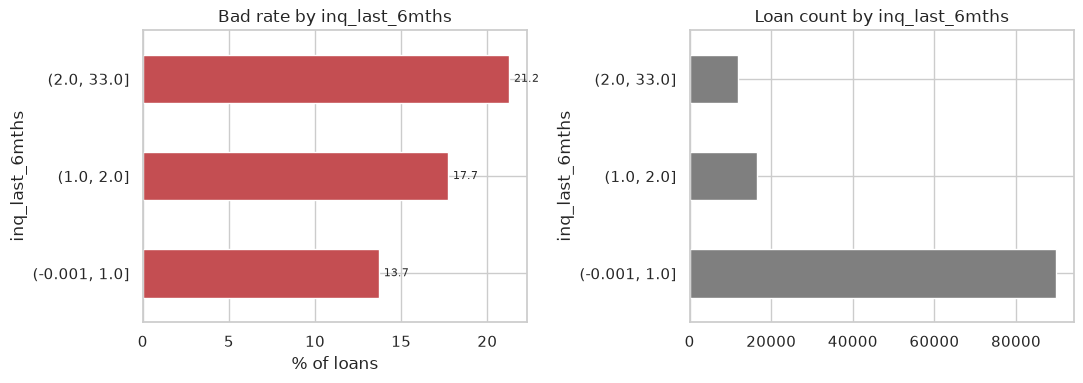

target,0,1
inq_last_6mths,,
"(-0.001, 1.0]",77439,12284
"(1.0, 2.0]",13661,2939
"(2.0, 33.0]",9248,2495


In [174]:
eda_profile(df, 'inq_last_6mths')

In [175]:
def group_inquiries(val):
    """
    0_none → no inquiries in the last 6 months.
    1_low → 1–2 inquiries.
    2_medium → 3–5 inquiries.
    3_high → 6 or more inquiries.
    """
    if val == 0:
        return '0_none'
    elif 1 <= val <= 2:
        return '1_low'
    elif 3 <= val <= 5:
        return '2_medium'
    else:  # 6 and above
        return '3_high'

# Apply to columns with NaN content replaced with 0
df['inq_bin'] = df['inq_last_6mths'].fillna(0).apply(group_inquiries)

# Change data type to category
df['inq_bin'] = df['inq_bin'].astype('category')

# Delete old columns
# df.drop(columns=['inq_last_6mths'], inplace=True)

# Check
df['inq_bin'].unique()

['1_low', '2_medium', '0_none', '3_high']
Categories (4, str): ['0_none', '1_low', '2_medium', '3_high']

inq_bin
0_none      56901
1_low       49422
2_medium    10833
3_high        910

Counts:
target        0     1
inq_bin              
0_none    49778  7123
1_low     41322  8100
2_medium   8626  2207
3_high      622   288

Bad rate (%):
inq_bin
0_none      12.52
1_low       16.39
2_medium    20.37
3_high      31.65

chi2=792.51, p=1.83e-171, dof=3


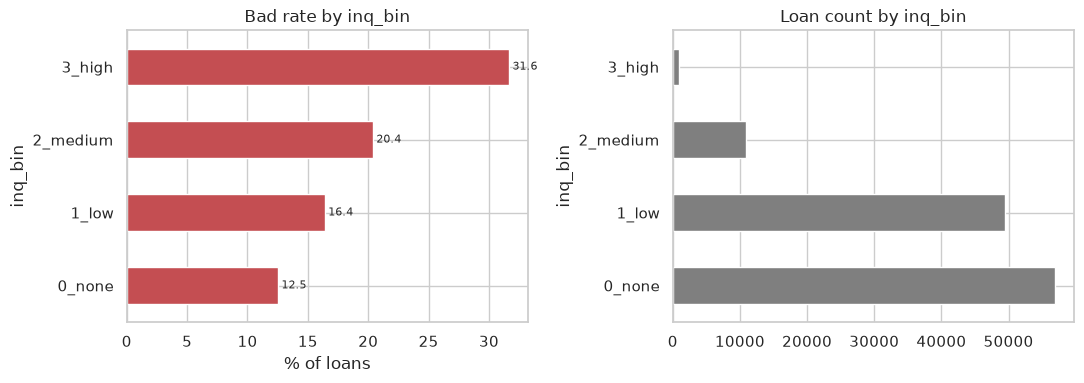

target,0,1
inq_bin,,
0_none,49778,7123
1_low,41322,8100
2_medium,8626,2207
3_high,622,288


In [176]:
eda_profile(df, 'inq_bin')

<br>

---
#### Numerical columns: <br>

| No | Feature                  | Description                                                                 |
|----|---------------------------|-----------------------------------------------------------------------------|
| 1  | acc_now_delinq            | The number of accounts on which the borrower is now delinquent.             |
| 2  | annual_inc                | The self-reported annual income provided by the borrower during registration. |
| 3  | collection_recovery_fee   | Post charge off collection fee.                                             |
| 4  | collections_12_mths_ex_med| Number of collections in 12 months excluding medical collections.            |
| 5  | delinq_2yrs               | The number of 30+ days past-due incidences of delinquency in the borrower(s) credit file for the past 2 years. |
| 6  | dti                       | -                                                                           |
| 7  | funded_amnt               | The total amount committed to that loan at that point in time.              |
| 8  | funded_amnt_inv           | Refers to the total amount of funds actually disbursed by investors (lenders) for a loan at a certain point in time. |
| 9  | inq_last_6mths            | The number of inquiries in past 6 months (excluding auto and mortgage inquiries). |
| 10 | installment               | The monthly payment owed by the borrower if the loan originates.            |
| 11 | int_rate                  | Interest Rate on the loan |
| 12 | last_pymnt_amnt           | Last total payment amount received.                                         |
| 13 | loan_amnt                 | Last month payment was received.                                            |
| 14 | mths_since_last_delinq    | The number of months since the borrower's last delinquency.                 |
| 15 | mths_since_last_major_derog| Months since most recent 90-day or worse rating.                           |
| 16 | mths_since_last_record    | The number of months since the last public record.                          |
| 17 | open_acc                  | The number of open credit lines in the borrower's credit file.              |
| 18 | out_prncp                 | Remaining outstanding principal for total amount funded.                    |
| 19 | out_prncp_inv             | Remaining outstanding principal for portion of total amount funded by investors. |
| 21 | pub_rec                   | Number of derogatory public records.                                        |
| 22 | recoveries                | Indicates if a payment plan has been put in place for the loan.             |
| 23 | revol_bal                 | Total credit revolving balance.                                             |
| 24 | revol_util                | Revolving line utilization rate, or the amount of credit the borrower is using relative to all available revolving credit. |
| 25 | tot_coll_amt              | Total collection amounts ever owed.                                         |
| 26 | tot_cur_bal               | Total current balance of all accounts.                                      |
| 27 | total_acc                 | The total number of credit lines currently in the borrower's credit file.   |
| 28 | total_pymnt               | Payments received to date for total amount funded.                          |
| 29 | total_pymnt_inv           | Payments received to date for portion of total amount funded by investors.  |
| 30 | total_rec_int             | Interest received to date.                                                  |
| 31 | total_rec_late_fee        | Late fees received to date.                                                 |
| 32 | total_rec_prncp           | Principal received to date.                                                 |
| 33 | total_rev_hi_lim          | Total revolving high credit/credit limit.                                   |

In [177]:
# Calculates the correlation of all numeric columns against the 'target' column.
correlations = df.select_dtypes(
    include=['int64', 'float64', np.number]
).corrwith(df['target']).sort_values(ascending=False)

correlations

target                        1.000000
collection_recovery_fee       0.235494
int_rate                      0.186212
loan_to_income                0.106576
payment_to_income             0.094535
inq_last_6mths                0.083019
revol_util                    0.078004
dti                           0.059281
loan_amnt                     0.041394
revol_bal_to_income           0.037837
open_acc_ratio                0.033395
pub_rec                       0.022576
delinq_2yrs                   0.010466
open_acc                      0.009332
emp_length_ordinal            0.006426
revol_bal_log                -0.000232
collections_12_mths_ex_med   -0.002371
revol_bal                    -0.002527
total_acc                    -0.016107
credit_age_years             -0.025368
annual_inc                   -0.044451
investor_funding_ratio       -0.046252
total_rev_hi_lim             -0.047939
tot_cur_bal                  -0.051322
out_prncp                    -0.067674
last_pymnt_amnt          

In [178]:
missing_summary(df)

,Missing Values,Percentage,Total length
collections_12_mths_ex_med,115,0.10,118066
emp_length_ordinal,3814,3.23,118066
revol_util,113,0.10,118066
tot_cur_bal,70037,59.32,118066
total_rev_hi_lim,70037,59.32,118066


### Business question Q4: **Do categorical attributes differentiate borrower risk?**

Ordinality checks (`term`, `grade`-like scales), low-cardinality screening, and
category-level bad-rate tables determine which categoricals survive and how they
should be encoded downstream.

<br>

---
## **2.4. Categorical Features Analysis and Anomaly Review**:

In [179]:
df.info()

<class 'pandas.DataFrame'>
Index: 118066 entries, 1296599 to 1289878
Data columns (total 55 columns):
 #   Column                              Non-Null Count   Dtype         
---  ------                              --------------   -----         
 0   annual_inc                          118066 non-null  float64       
 1   collection_recovery_fee             118066 non-null  float64       
 2   collections_12_mths_ex_med          117951 non-null  float64       
 3   collections_12mths_group            118066 non-null  category      
 4   credit_age_group                    118066 non-null  category      
 5   credit_age_years                    118066 non-null  float64       
 6   delinq_2yrs                         118066 non-null  float64       
 7   delinq_2yrs_group                   118066 non-null  category      
 8   dti                                 118066 non-null  float64       
 9   earliest_cr_line                    118066 non-null  datetime64[us]
 10  emp_length_group 

In [180]:
# Categorical columns
cat_cols = df.select_dtypes(include=['object', 'str', 'category'])

In [181]:
cat_cols.describe()

,collections_12mths_group,credit_age_group,delinq_2yrs_group,emp_length_group,grade,home_ownership,initial_list_status,mths_since_last_delinq_binned,mths_since_last_major_derog_binned,mths_since_last_record_binned,pub_rec_group,purpose,pymnt_plan,sub_grade,term,verification_status,total_rev_hi_lim_group,tot_cur_bal_group,tot_coll_amt_group,total_acc_group,revol_bal_group,revol_util_group,open_acc_group,annual_inc_group,inq_bin
count,118066,118066,118066,118066,118066,118066,118066,118066,118066,118066,118066,118066,118066,118066,118066,118066,118066,118066,118066,118066,118066,118066,118066,118066,118066
unique,3,3,4,5,7,5,2,6,6,6,3,11,2,35,2,3,6,6,3,4,5,7,5,5,4
top,No_Collections,5_15,0_delinq,Expert_Employee,B,MORTGAGE,f,no_history,no_history,no_history,0_pub_rec,debt_consolidation,n,B3,36 months,Verified,Unknown,Unknown,Unknown,15_to_25,10k_to_20k,60_to_80,9_to_14,Very_Low,0_none
freq,117863,68002,103023,32127,38878,55850,107553,72672,108790,112264,112264,64113,118061,10350,92663,46252,70037,70037,70037,42077,36790,32593,52109,25882,56901


In [182]:
missing_summary(cat_cols)

,Missing Values,Percentage,Total length


<br>

---
### `home_ownership`:

In [183]:
df[df['home_ownership'] == 'ANY']

,annual_inc,collection_recovery_fee,collections_12_mths_ex_med,collections_12mths_group,credit_age_group,credit_age_years,delinq_2yrs,delinq_2yrs_group,dti,earliest_cr_line,emp_length_group,emp_length_ordinal,grade,home_ownership,initial_list_status,inq_last_6mths,int_rate,investor_funding_ratio,issue_d,last_credit_pull_d,last_pymnt_amnt,last_pymnt_d,loan_amnt,mths_since_last_delinq_binned,mths_since_last_major_derog_binned,mths_since_last_record_binned,open_acc,out_prncp,payment_to_income,pub_rec,pub_rec_group,purpose,pymnt_plan,revol_bal,revol_util,sub_grade,target,term,tot_cur_bal,total_acc,total_rev_hi_lim,verification_status,total_rev_hi_lim_group,tot_cur_bal_group,tot_coll_amt_group,total_acc_group,revol_bal_log,revol_bal_group,revol_bal_to_income,revol_util_group,open_acc_group,open_acc_ratio,loan_to_income,annual_inc_group,inq_bin
member_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,


In [184]:
# Replace the value 'ANY', 'NONE' to the string 'OTHER'
df['home_ownership'] = df['home_ownership'].replace({
    'ANY': 'OTHER',
    'NONE': 'OTHER'
})
# Sanity Check
df['home_ownership'].value_counts()

home_ownership
MORTGAGE    55850
RENT        53004
OWN          8984
OTHER         228
Name: count, dtype: int64

In [185]:
df['home_ownership'] = df['home_ownership'].astype('category')

df['home_ownership'].unique()

['RENT', 'OWN', 'MORTGAGE', 'OTHER']
Categories (4, str): ['MORTGAGE', 'OTHER', 'OWN', 'RENT']

home_ownership
MORTGAGE    55850
RENT        53004
OWN          8984
OTHER         228

Counts:
target              0     1
home_ownership             
MORTGAGE        48141  7709
OTHER             182    46
OWN              7580  1404
RENT            44445  8559

Bad rate (%):
home_ownership
MORTGAGE    13.80
OWN         15.63
RENT        16.15
OTHER       20.18

chi2=125.05, p=6.32e-27, dof=3


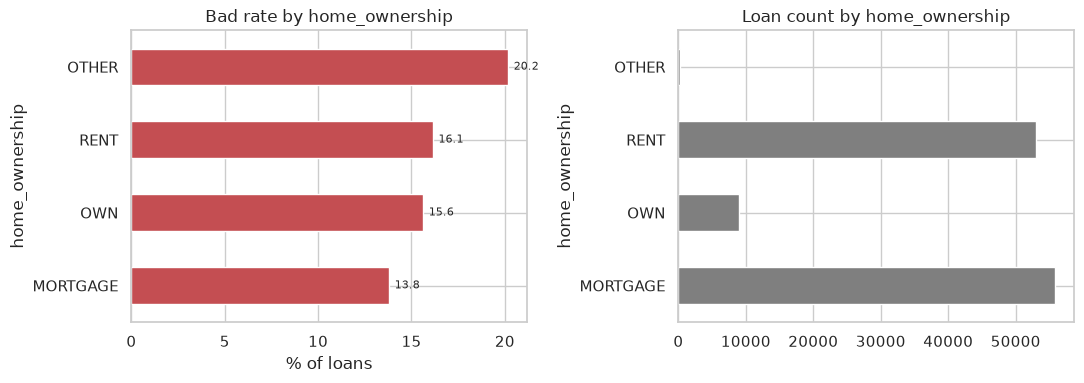

target,0,1
home_ownership,,
MORTGAGE,48141,7709
OTHER,182,46
OWN,7580,1404
RENT,44445,8559


In [186]:
eda_profile(df, 'home_ownership')

<br>

---
### `initial_list_status`:

In [187]:
df['initial_list_status'] = df['initial_list_status'].astype('category')

df['initial_list_status'].unique()

['f', 'w']
Categories (2, str): ['f', 'w']

initial_list_status
f    107553
w     10513

Counts:
target                   0      1
initial_list_status              
f                    91289  16264
w                     9059   1454

Bad rate (%):
initial_list_status
w    13.83
f    15.12

chi2=12.42, p=0.000425, dof=1


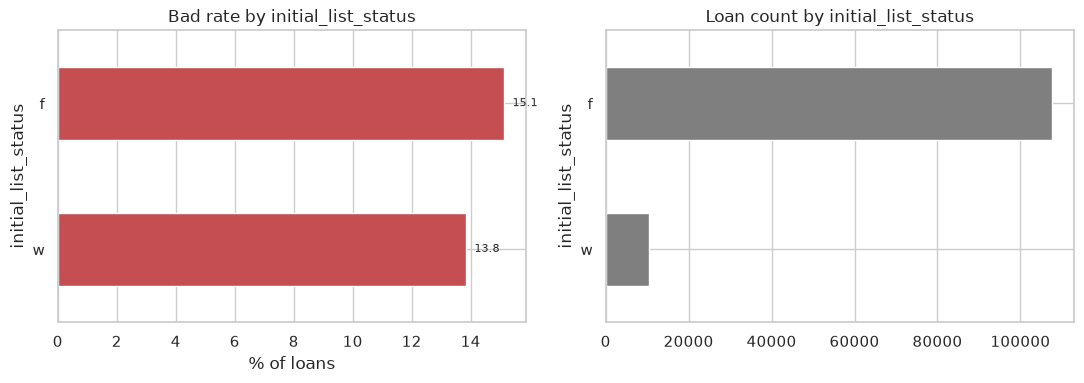

target,0,1
initial_list_status,,
f,91289,16264
w,9059,1454


In [188]:
eda_profile(df, 'initial_list_status')

<br>

---
### `pymnt_plan`:

In [189]:
df['pymnt_plan'].unique()

<ArrowStringArray>
['n', 'y']
Length: 2, dtype: str

In [190]:
df['pymnt_plan'].value_counts(normalize=True) * 100 

pymnt_plan
n    99.995765
y     0.004235
Name: proportion, dtype: float64

In [191]:
df.drop(columns=['pymnt_plan'], inplace=True)

<br>

---
### `term`:

In [192]:
df['term'] = df['term'].replace({
    ' 36 months': '36_months',
    ' 60 months': '60_months'
})
df['term'].unique()

<ArrowStringArray>
['36_months', '60_months']
Length: 2, dtype: str

In [193]:
df['term'] = df['term'].astype('category')

df['term'].unique()

['36_months', '60_months']
Categories (2, str): ['36_months', '60_months']

term
36_months    92663
60_months    25403

Counts:
target         0      1
term                   
36_months  80714  11949
60_months  19634   5769

Bad rate (%):
term
36_months    12.90
60_months    22.71

chi2=1504.99, p=0, dof=1


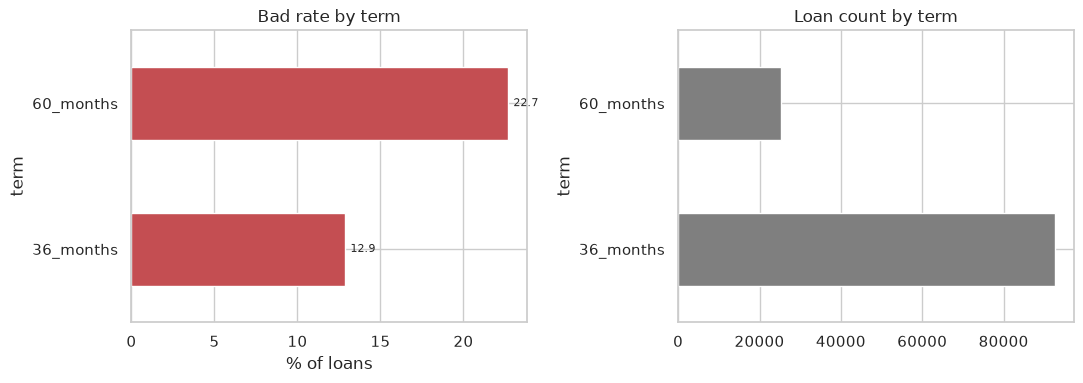

target,0,1
term,,
36_months,80714,11949
60_months,19634,5769


In [194]:
eda_profile(df, 'term')

<br>

---
### `verification_status`:

In [195]:
df.groupby('verification_status')['target'].mean()

verification_status
Not Verified       0.129957
Source Verified    0.152378
Verified           0.168879
Name: target, dtype: float64

In [196]:
# Change 'Source Verified' to 'Verified'
df['verification_status'] = df['verification_status'].replace(
    {'Source Verified': 'Verified'}
)

# Validate the change results
print(df['verification_status'].unique())

df.groupby('verification_status')['target'].mean()

<ArrowStringArray>
['Verified', 'Not Verified']
Length: 2, dtype: str


verification_status
Not Verified    0.129957
Verified        0.162998
Name: target, dtype: float64

In [197]:
df['verification_status'] = df['verification_status'].replace({
    'Not Verified': 'Not_Verified',
})
df['verification_status'] = df['verification_status'].astype('category')

df['verification_status'].unique()

['Verified', 'Not_Verified']
Categories (2, str): ['Not_Verified', 'Verified']

verification_status
Verified        71866
Not_Verified    46200

Counts:
target                   0      1
verification_status              
Not_Verified         40196   6004
Verified             60152  11714

Bad rate (%):
verification_status
Not_Verified    13.0
Verified        16.3

chi2=240.44, p=3.15e-54, dof=1


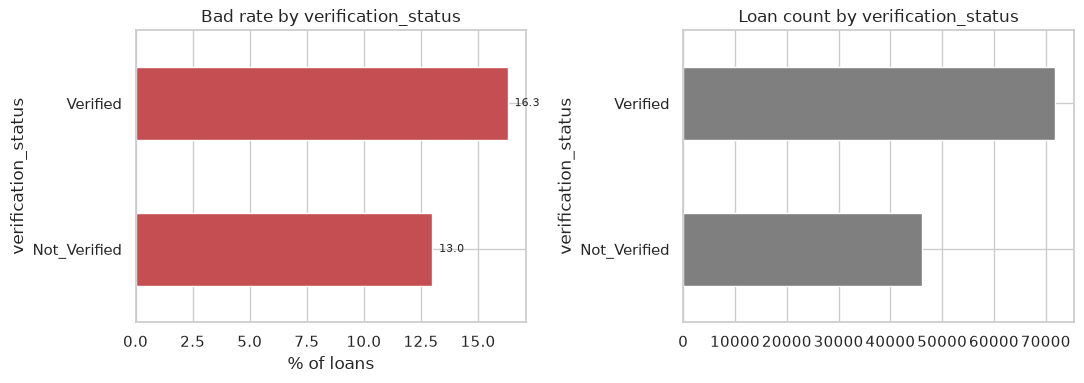

target,0,1
verification_status,,
Not_Verified,40196,6004
Verified,60152,11714


In [198]:
eda_profile(df, 'verification_status')

---

* **WoE (Weight of Evidence) Function for Feature Selection**:

<br>

| Value Range IV | Predictive Power) | General Actions |
|----------------|-------------------|-----------------|
| **< 0.02** | Useless / Unpredictable | Usually dropped (except for Logistic Regression which requires control variables) |
| **0.02** *to* **0.1** | Weak Predictor | Maintained |
| **0.1** *to* **0.3** | Medium Predictor | Very Good (Very well maintained) |
| **0.3** *to* **0.5** | Strong Predictor |  Great Model |
| **> 0.5** | Suspicious | Need to check, prone to data leakage |

<br>

In [199]:
df = df[sorted(df.columns)]

from src.utils import calculate_all_iv
# Replace 'y' with your target column name if different
tabel_iv = calculate_all_iv(dataframe=df, target_col='target', num_bins=7)
tabel_iv

,Feature,Information Value (IV)
0,last_pymnt_amnt,1.995487e+00
1,int_rate,2.772979e-01
2,loan_to_income,8.066014e-02
3,payment_to_income,6.791023e-02
4,revol_util,4.924486e-02
5,annual_inc,4.127982e-02
6,inq_last_6mths,3.488008e-02
7,dti,2.769252e-02
8,loan_amnt,1.547164e-02
9,revol_bal_to_income,1.464221e-02


### Business question Q5: **What business decision does this model support?**

The model answers: *"at application time, what is the probability this loan ends BAD,
and does it clear the cost-optimal approval threshold?"*: Scenario A
(application-time) scope. Features unavailable at application time are excluded
here and re-validated in notebook 2.

---
# 3.0. Business Understanding and Modeling Objectives

The goal of this project is to build a binary classification model that predicts whether a loan will end up as **Fully Paid** (`0`) or **Charged Off / Default** (`1`).

To ensure realistic model performance, features are selected based on their availability at prediction time. This is important to avoid **data leakage**, where the model indirectly uses information that would not be available when making a real-world prediction.

---

## 3.1 Target Definition

```python
good_statuses = [
    'Fully Paid',
    'Does not meet the credit policy. Status:Fully Paid'
]

df['y'] = np.where(df['loan_status'].isin(good_statuses), 0, 1)
```

**Target Mapping**

| Loan Status                                         | Target |
| --------------------------------------------------- | ------ |
| Fully Paid                                          | 0      |
| Does not meet the credit policy. Status:Fully Paid  | 0      |
| Charged Off                                         | 1      |
| Default                                             | 1      |
| Does not meet the credit policy. Status:Charged Off | 1      |
| etc.                                                | 1      |

Loans with `Current` status are removed because their final outcome is still unknown.

---

### Scenario A: Application-Time Model

#### Objective

Aimed at predicting the probability of default risk **prior to loan approval or funding.**

Only information available at application or credit assessment time is allowed.

#### Features Used

```python
[
    'annual_inc',
    'collections_12_mths_ex_med',
    'credit_history_length',
    'delinq_2yrs',
    'dti',
    'emp_length_num',
    'home_ownership',
    'inq_last_6mths',
    'loan_amnt',
    'open_acc',
    'pub_rec',
    'purpose',
    'revol_bal',
    'revol_util',
    'term',
    'tot_coll_amt',
    'tot_cur_bal',
    'total_acc',
    'total_rev_hi_lim',
    'verification_status'
]
```

#### Features Removed

```python
[
    'collection_recovery_fee',
    'funded_amnt',
    'grade',
    'initial_list_status',
    'installment',
    'int_rate',
    'investor_funding_ratio',
    'last_pymnt_amnt',
    'out_prncp', 
    'payment_to_income', 
    'pymnt_plan', 
    'recoveries', 
    'total_rec_prncp', 
    'total_pymnt', 
    'total_rec_int', 
    'total_rec_late_fee'
]
```

#### Reason for Removal

| Feature                 | Reason                                                            |
| ------------------------|-------------------------------------------------------------------|
| collection_recovery_fee | Directly related to post-default collection activities |
| funded_amnt             | Result of LendingClub funding decision |
| grade                   | LendingClub's internal risk assessment |
| initial_list_status     | Assigned during listing process |
| installment             | Derived from approved loan terms |
| int_rate                | Pricing determined after underwriting |
| investor_funding_ratio  | Depends on investor funding activity |
| last_pymnt_amnt         | Reflects actual borrower payment behavior after origination |
| out_prncp               | Remaining outstanding principal known only during loan servicing |
| payment_to_income       | Uses installment, which depends on approved loan terms |
| pymnt_plan              | Payment arrangement information established after loan issuance and servicing |
| recoveries              | Generated only after a loan has been charged off and recovery actions occur |
| total_rec_prncp         | Represents principal already repaid by the borrower |
| total_pymnt             | Contains cumulative repayment information that becomes available only after loan servicing begins |
| total_rec_int           | Represents interest already collected from the borrower |
| total_rec_late_fee      | Accumulates late fees generated during loan repayment |

These variables contain lender decisions or post-application information and may introduce leakage into an underwriting model.

---

### Scenario B: Post-Origination Model

#### Objective

Designed to predict the probability of default risk **after a loan has been approved and funded.**

Funding and loan structure information is allowed because it is already known at prediction time.

#### Features Used

```python
[
    'annual_inc',
    'collections_12_mths_ex_med',
    'credit_history_length',
    'delinq_2yrs',
    'dti',
    'emp_length_num',
    'funded_amnt',
    'grade',
    'home_ownership',
    'initial_list_status',
    'inq_last_6mths',
    'installment',
    'int_rate',
    'investor_funding_ratio',
    'loan_amnt',
    'loan_amount_cut',
    'loan_cut_ratio',
    'mths_since_last_delinq',
    'mths_since_last_major_derog',
    'mths_since_last_record',
    'open_acc',
    'payment_to_income',
    'pub_rec',
    'purpose',
    'revol_bal',
    'revol_util',
    'term',
    'tot_coll_amt',
    'tot_cur_bal',
    'total_acc',
    'total_rev_hi_lim',
    'verification_status'
]
```

#### Features Still Excluded

```python
[
    'total_pymnt',
    'total_rec_prncp',
    'total_rec_int',
    'total_rec_late_fee',
    'last_pymnt_amnt',
    'recoveries',
    'collection_recovery_fee',
    'out_prncp'
]
```

#### Reason for Removal

These variables are generated during repayment, collection, or charge-off processes and directly reveal the future loan outcome.

Examples:

* `recoveries` only exist after default.
* `collection_recovery_fee` is generated after collection activities.
* `last_pymnt_amnt` contains repayment information unavailable at origination.
* `out_prncp` reflects future loan performance.

Including these variables would cause severe target leakage and unrealistic model performance.

<br>

---
## **3.2. Feature Selection**:

In [200]:
df.columns.tolist()

['annual_inc',
 'annual_inc_group',
 'collection_recovery_fee',
 'collections_12_mths_ex_med',
 'collections_12mths_group',
 'credit_age_group',
 'credit_age_years',
 'delinq_2yrs',
 'delinq_2yrs_group',
 'dti',
 'earliest_cr_line',
 'emp_length_group',
 'emp_length_ordinal',
 'grade',
 'home_ownership',
 'initial_list_status',
 'inq_bin',
 'inq_last_6mths',
 'int_rate',
 'investor_funding_ratio',
 'issue_d',
 'last_credit_pull_d',
 'last_pymnt_amnt',
 'last_pymnt_d',
 'loan_amnt',
 'loan_to_income',
 'mths_since_last_delinq_binned',
 'mths_since_last_major_derog_binned',
 'mths_since_last_record_binned',
 'open_acc',
 'open_acc_group',
 'open_acc_ratio',
 'out_prncp',
 'payment_to_income',
 'pub_rec',
 'pub_rec_group',
 'purpose',
 'revol_bal',
 'revol_bal_group',
 'revol_bal_log',
 'revol_bal_to_income',
 'revol_util',
 'revol_util_group',
 'sub_grade',
 'target',
 'term',
 'tot_coll_amt_group',
 'tot_cur_bal',
 'tot_cur_bal_group',
 'total_acc',
 'total_acc_group',
 'total_rev_hi_li

In [201]:
# Drop feature to maintain a realistic deployment scenario and avoid decision leakage 
# with Scenario A - Aplication-Time Model & Based on Variance Inflation Factor (VIF)
df.drop(columns=[
    # Data leakage and influence multicollinearity
    'collection_recovery_fee', 'grade', 'initial_list_status', 'int_rate', 'investor_funding_ratio', 
    'last_pymnt_amnt', 'last_pymnt_d', 'out_prncp', 'payment_to_income', 'sub_grade',
    
    # Affected or influenced by multicollinearity
    'mths_since_last_delinq_binned', 'mths_since_last_record_binned', 'mths_since_last_major_derog_binned',

], inplace=True)

In [202]:
df.columns.tolist()

['annual_inc',
 'annual_inc_group',
 'collections_12_mths_ex_med',
 'collections_12mths_group',
 'credit_age_group',
 'credit_age_years',
 'delinq_2yrs',
 'delinq_2yrs_group',
 'dti',
 'earliest_cr_line',
 'emp_length_group',
 'emp_length_ordinal',
 'home_ownership',
 'inq_bin',
 'inq_last_6mths',
 'issue_d',
 'last_credit_pull_d',
 'loan_amnt',
 'loan_to_income',
 'open_acc',
 'open_acc_group',
 'open_acc_ratio',
 'pub_rec',
 'pub_rec_group',
 'purpose',
 'revol_bal',
 'revol_bal_group',
 'revol_bal_log',
 'revol_bal_to_income',
 'revol_util',
 'revol_util_group',
 'target',
 'term',
 'tot_coll_amt_group',
 'tot_cur_bal',
 'tot_cur_bal_group',
 'total_acc',
 'total_acc_group',
 'total_rev_hi_lim',
 'total_rev_hi_lim_group',
 'verification_status']

In [203]:
df.drop(columns=[
    'annual_inc_group', 'collections_12mths_group', 'credit_age_group', 'delinq_2yrs_group', 'emp_length_group', 
    'inq_bin', 'open_acc_group', 'pub_rec_group', 'revol_bal_group', 'revol_bal_log', 'revol_util_group', 
    'tot_coll_amt_group', 'tot_cur_bal_group', 'total_acc_group', 'total_rev_hi_lim_group',
    'last_credit_pull_d'], inplace=True)

In [204]:
missing_summary(df)

,Missing Values,Percentage,Total length
collections_12_mths_ex_med,115,0.10,118066
emp_length_ordinal,3814,3.23,118066
revol_util,113,0.10,118066
tot_cur_bal,70037,59.32,118066
total_rev_hi_lim,70037,59.32,118066


In [205]:
compute_vif(dataframe=df, target_col='target')

NaN/inf found, row will be dropped before VIF calculation.

                   feature     VIF
                     const 87.7725
                annual_inc  1.6117
collections_12_mths_ex_med  1.0020
          credit_age_years  1.3073
               delinq_2yrs  1.0474
                       dti  1.5100
        emp_length_ordinal  1.0840
            inq_last_6mths  1.0491
                 loan_amnt  3.2429
            loan_to_income  3.1832
                  open_acc  6.5663
            open_acc_ratio  4.8940
                   pub_rec  1.0237
                 revol_bal  7.3318
       revol_bal_to_income  3.3954
                revol_util  2.1396
               tot_cur_bal  1.6866
                 total_acc  8.3485
          total_rev_hi_lim  7.4275


In [206]:
tabel_iv = calculate_all_iv(dataframe=df, target_col='target', num_bins=6)
tabel_iv

,Feature,Information Value (IV)
0,loan_to_income,8.181560e-02
1,revol_util,4.875430e-02
2,annual_inc,4.216668e-02
3,inq_last_6mths,3.488008e-02
4,dti,2.645567e-02
5,loan_amnt,1.666551e-02
6,revol_bal_to_income,1.454949e-02
7,tot_cur_bal,1.069585e-02
8,total_rev_hi_lim,9.914248e-03
9,open_acc_ratio,9.151058e-03


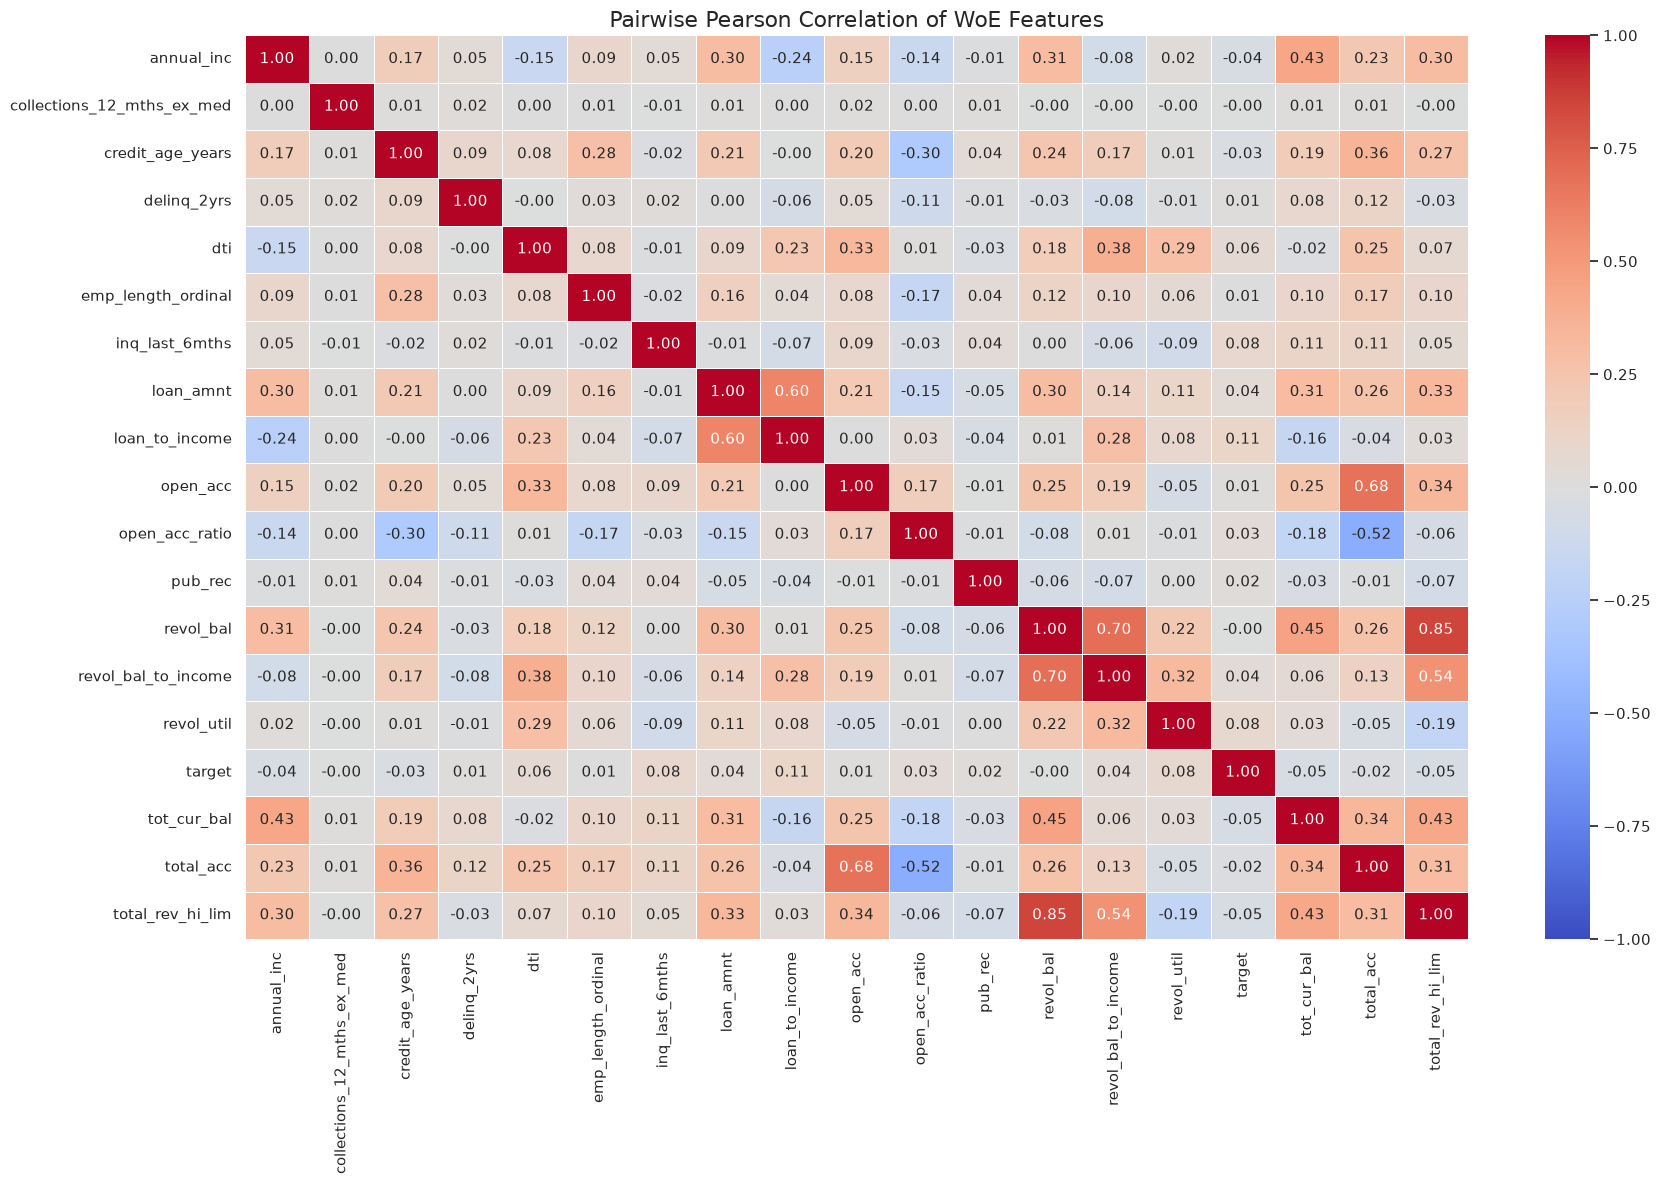

=== FEATURE PAIRS WITH HIGH CORRELATION (SUSPECTS) ===
             Feature 1            Feature 2  Correlation
0            revol_bal     total_rev_hi_lim     0.845845
1            revol_bal  revol_bal_to_income     0.695231
2             open_acc            total_acc     0.678378
3            loan_amnt       loan_to_income     0.596209
4  revol_bal_to_income     total_rev_hi_lim     0.535960
5       open_acc_ratio            total_acc    -0.515567


In [207]:
df_corr = df.select_dtypes(include=[np.number])

# 1. Calculate Pairwise Pearson Correlation
corr_matrix = df_corr.corr(method='pearson')

# 2. Plot Heatmap
plt.figure(figsize=(18, 12))
sns.heatmap(
    corr_matrix, 
    annot=True, 
    cmap='coolwarm', 
    fmt=".2f", 
    vmin=-1, 
    vmax=1,
    linewidths=0.5,
    annot_kws={"size": 11}
)
plt.title(f"Pairwise Pearson Correlation of WoE Features", fontsize=16)
plt.tight_layout()
plt.show()

# 3. Look for Feature Pairs with High Correlation (Suspected Multicollinearity)
# The correlation threshold is usually 0.5 or 0.6 for credit risk models.
threshold = 0.5  

# Take the upper triangle of the correlation matrix so that there are no duplications (A-B and B-A)
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

high_corr_pairs = []
for col in upper_tri.columns:
    for row in upper_tri.index:
        val = upper_tri.loc[row, col]
        if abs(val) >= threshold:
            high_corr_pairs.append({
                'Feature 1': row,
                'Feature 2': col,
                'Correlation': val
            })

high_corr_df = pd.DataFrame(high_corr_pairs)
if not high_corr_df.empty:
    high_corr_df = high_corr_df.sort_values(by='Correlation', key=abs, ascending=False).reset_index(drop=True)
    print(f"=== FEATURE PAIRS WITH HIGH CORRELATION (SUSPECTS) ===")
    print(high_corr_df)
else:
    print(f"There are no feature pairs with correlation >= {threshold}")

In [208]:
from src.utils import information_gain_report

# Calculate Information Gain for each feature
features = df.drop(columns=[
    'target', 'earliest_cr_line', 'issue_d', 'tot_cur_bal', 'revol_bal', 'revol_bal_to_income',
    'total_rev_hi_lim', 'loan_amnt', 'open_acc', 'total_acc']).columns.tolist()

sorted_info_gain_values = information_gain_report(df, features, target_col='target')

# Print the best feature
best_feature, best_info_gain = sorted_info_gain_values[0]
print(f"Best Feature to choose as Root Node: {best_feature}")
print(f"With Information Gain: {best_info_gain}")

# Print Information Gain for all features
print(f'\nInformation Gain for each feature:')
for feature, gain in sorted_info_gain_values:
    display(f"{feature}: {gain}")

Best Feature to choose as Root Node: loan_to_income
With Information Gain: 0.1663

Information Gain for each feature:


'loan_to_income: 0.1663'

'annual_inc: 0.0649'

'dti: 0.0258'

'emp_length_ordinal: 0.0238'

'revol_util: 0.0127'

... (6 outputs left out)

'collections_12_mths_ex_med: 0.0008'

'home_ownership: 0.0008'

'pub_rec: 0.0006'

'delinq_2yrs: 0.0002'

<br>

---
# **4.0. Synthesis: Key Findings & Customer Segmentation**

Two deliverables close the EDA:

1. **Key findings**: the business answers (Q1–Q5) in one place, with the numbers
   that drive the modeling decisions downstream.
2. **Customer segmentation**: interpretable risk bands built from application-time attributes
   (term x DTI tercile). Segments are an *analysis and monitoring* device
   (portfolio mix, per-segment thresholds, drift detection); PD-band
   segmentation on model scores is the stronger version and belongs in
   notebook 4 / the dashboard.

<br>

## **4.1. Key Findings: Business Answers**

| Question | Answer (verified on the eligible population, n = 117,841) |
|---|---|
| **Q1: What is BAD, and when knowable?** | BAD = Charged Off / Default / Late (31–120 days) → **15.0%** of eligible loans. Performance window **M = 33 months** (90th percentile of months-to-bad): a 'Current' loan is only labeled GOOD after surviving 33 months. Safe horizon cutoff → **OOT test = 2013Q1**. |
| **Q2: Is the data trustworthy?** | Missingness concentrated in `mths_since_*`/bureau fields and two near-empty columns dropped upstream; `collections_12_mths_ex_med`/`revol_util` NaNs removed. Leakage-prone post-origination fields (`last_pymnt_*`, `recoveries`, `collection_recovery_fee`, `out_prncp`, funded/installment amounts, `grade`/`sub_grade`/`int_rate` under Scenario A) excluded: see drop audit trail in §2. |
| **Q3: Which features carry signal?** | Survivors of univariate screening (IV/WOE monotonicity/VIF/correlation/IG): `annual_inc`, `dti`, `revol_util`, `inq_last_6mths`, `delinq_2yrs`, `credit_age_years`, `loan_to_income`, `open_acc_ratio`, `emp_length_ordinal`, `has_derogatory`, `purpose`, `home_ownership`, `term`: finalized as `features_to_selected` in notebook 2. |
| **Q4: Do categoricals differentiate risk?** | `term` (36 vs 60 months), `purpose`, `home_ownership`, `verification_status` show meaningful bad-rate spread; `policy_code`/`pymnt_plan`/`application_type`/`title` dropped (zero/near-zero variance or redundant). |
| **Q5: What decision is supported?** | Application-time approve/review/reject via PD + cost-optimal threshold. **Vintage stability check**: bad rate ranges **11.3%–29.8%** across 2007Q3–2013Q1: crisis-era vintages (2007–08) are extreme; post-2009 vintages stabilize at ~13–16%, so the OOT comparison is meaningful but must be read with vintage mix in mind. |

**Modeling implications carried into notebooks 2–4:** temporal (not random) validation;
per-observation EAD cost threshold; ensemble of the three GBMs; calibration chosen
automatically on validation; scorecard built on WoE features only.

<br>

### **4.1a. Key Portfolio Visuals**

The three charts below compress the EDA into the pictures a credit committee
actually reads: risk by **term**, by **purpose** (top 10 by volume), and by
**home ownership**: each annotated with portfolio share so small cells are
not over-read.

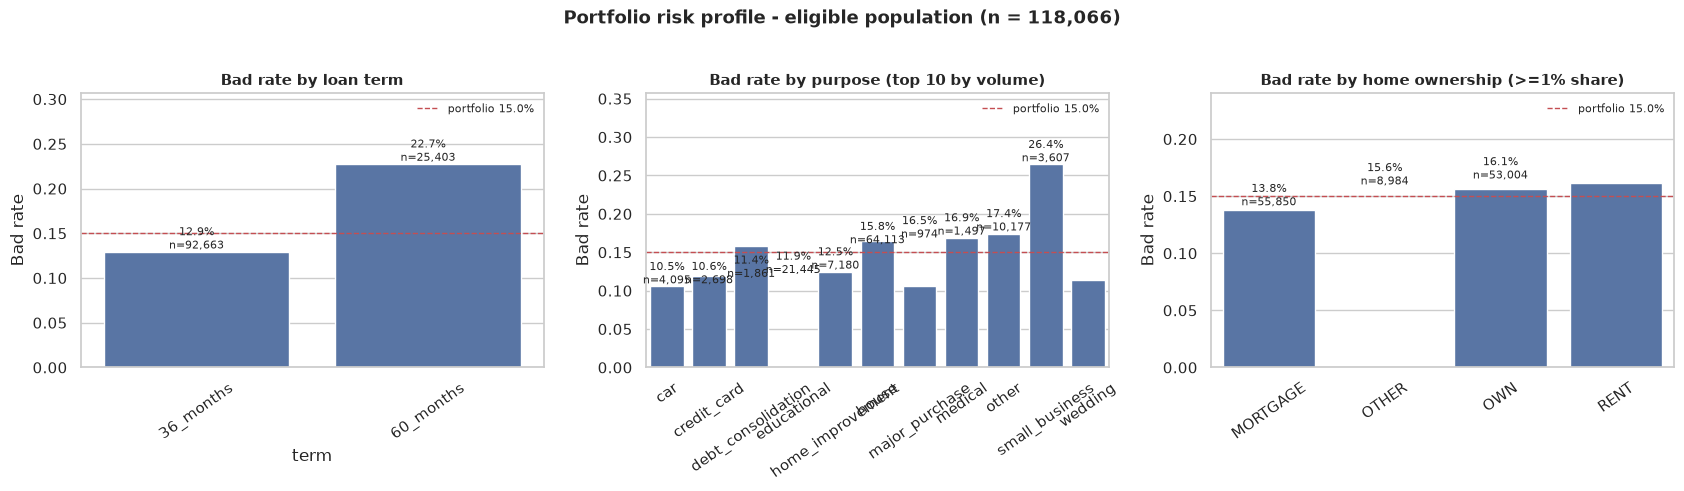

In [209]:
# 4.1a. KEY PORTFOLIO VISUALS (seaborn, stakeholder-ready)
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
_base = df['target'].mean()

def _bar_badrate(ax, grouped, title, xlabel=''):
    g = grouped.reset_index()
    sns.barplot(data=g, x='level', y='bad_rate', ax=ax, color=C_BLUE, edgecolor='white')
    for i, (n, br) in enumerate(zip(g['n'], g['bad_rate'])):
        ax.text(i, br + 0.004, f'{br*100:.1f}%\nn={n:,}', ha='center', fontsize=8)
    ax.axhline(_base, color=C_RED, ls='--', lw=1, label=f'portfolio { _base*100:.1f}%')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_ylabel('Bad rate'); ax.set_xlabel(xlabel)
    ax.legend(fontsize=8, frameon=False)
    ax.set_ylim(0, max(g['bad_rate'].max()*1.35, _base*1.6))
    ax.tick_params(axis='x', rotation=35)

# 1) term
_t = (df.groupby('term', observed=True)['target']
        .agg(bad_rate='mean', n='size').reset_index().rename(columns={'term':'level'}))
_bar_badrate(axes[0], _t, 'Bad rate by loan term', 'term')

# 2) purpose - top 10 by volume
_top_purposes = df['purpose'].value_counts().head(10).index
_p = (df[df['purpose'].isin(_top_purposes)].groupby('purpose', observed=True)['target']
        .agg(bad_rate='mean', n='size').reset_index()
        .sort_values('bad_rate')
        .rename(columns={'purpose':'level'}))
_bar_badrate(axes[1], _p, 'Bad rate by purpose (top 10 by volume)')

# 3) home_ownership - drop tiny cells (<1% share) to avoid over-reading
_h = (df.groupby('home_ownership', observed=True)['target']
        .agg(bad_rate='mean', n='size').reset_index()
        .assign(share=lambda d: d['n']/d['n'].sum())
        .query('share >= 0.01')
        .rename(columns={'home_ownership':'level'}))
_bar_badrate(axes[2], _h, 'Bad rate by home ownership (>=1% share)')

plt.suptitle('Portfolio risk profile - eligible population (n = {:,})'.format(len(df)),
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('reports/figures/EDA_Portfolio_Risk.png', dpi=150, bbox_inches='tight')
plt.show()

Base bad rate: 0.1501 | DTI cut points: [11.99 19.11]


,term,dti_band,n,bad_rate,pct,bad_lift
5,60_months,"(19.1,35.0]",9398,0.2442,8.0,1.63
4,60_months,"(12.0,19.1]",8758,0.2253,7.4,1.50
3,60_months,"(-0.0,12.0]",7247,0.2071,6.1,1.38
2,36_months,"(19.1,35.0]",29913,0.1528,25.3,1.02
1,36_months,"(12.0,19.1]",30639,0.1273,26.0,0.85
0,36_months,"(-0.0,12.0]",32111,0.1083,27.2,0.72


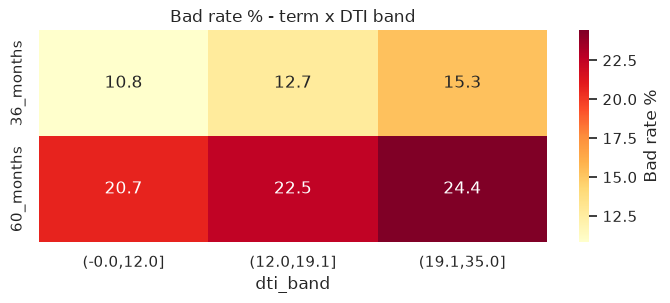

In [210]:
# 4.2. RULE-BASED RISK SEGMENTS (interpretable bands)
# Segment = loan term x DTI tercile. Chosen over unsupervised clustering:
# stable definitions, explainable in a credit memo, and directly maps to
# per-segment policy (thresholds, limits, monitoring).
df_seg = df[['term', 'dti', 'target']].dropna().copy()

# DTI terciles (data-driven cut points, printed for transparency)
dti_cuts = df_seg['dti'].quantile([1/3, 2/3]).values
df_seg['dti_band'] = pd.qcut(df_seg['dti'], q=3, duplicates='drop')
df_seg['dti_band'] = df_seg['dti_band'].astype(str).str.replace(
    r'\(([^,]+),([^\]]+)\]',
    lambda m: f'({float(m.group(1)):.1f},{float(m.group(2)):.1f}]', regex=True)

base_bad = df_seg['target'].mean()
seg_profile = (
    df_seg.groupby(['term', 'dti_band'], observed=True)['target']
    .agg(n='size', bad_rate='mean')
    .reset_index()
    .assign(pct=lambda d: (d['n'] / d['n'].sum() * 100).round(1),
            bad_rate=lambda d: d['bad_rate'].round(4),
            bad_lift=lambda d: (d['bad_rate'] / base_bad).round(2))
    .sort_values('bad_rate', ascending=False)
)
print(f"Base bad rate: {base_bad:.4f} | DTI cut points: {dti_cuts.round(2)}")
display(seg_profile)

# Heatmap view of the same segment profile (bad rate %)
pivot_bad = (df_seg.pivot_table(index='term', columns='dti_band',
                                values='target', aggfunc='mean') * 100)
fig, ax = plt.subplots(figsize=(7, 3.2))
sns.heatmap(pivot_bad, annot=True, fmt='.1f', cmap='YlOrRd',
            cbar_kws={'label': 'Bad rate %'}, ax=ax)
ax.set_title('Bad rate % - term x DTI band'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

<br>

### Reading the segment profile

- Rows are `term x DTI tercile` groups. **`bad_lift` > 1** → riskier than the
  portfolio average; these groups justify stricter approval thresholds or
  lower exposure limits (per-segment policy is a legitimate Scenario-A lever).
- The DTI cut points are printed above so the bands can be restated as fixed
  business rules (e.g. "DTI > X%") rather than data-dependent terciles.
- **Stronger version downstream**: once models produce PDs (nb4), re-cut these
  same groups by *predicted* risk decile: score bands are more decision-relevant
  than attribute bands and are what the dashboard should display.

<br>

## **4.3. Dashboard Preview: Interactive (Plotly)**

Mock-up of the panels the future **Streamlit dashboard** will render, built
with plain Plotly so the layout/interaction can be evaluated before the app
exists. Scorecard/PD panels are intentionally absent: they arrive with the
modeling notebooks; this preview covers the EDA-level portfolio views only.
All figures are computed on the eligible EDA population (`df`).

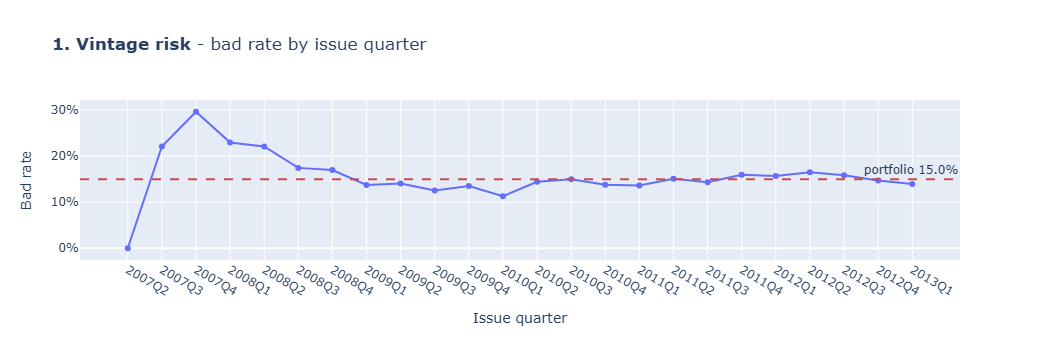

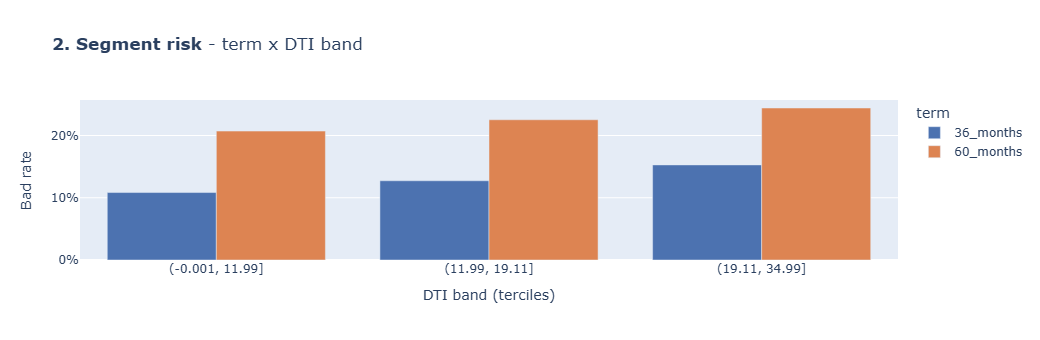

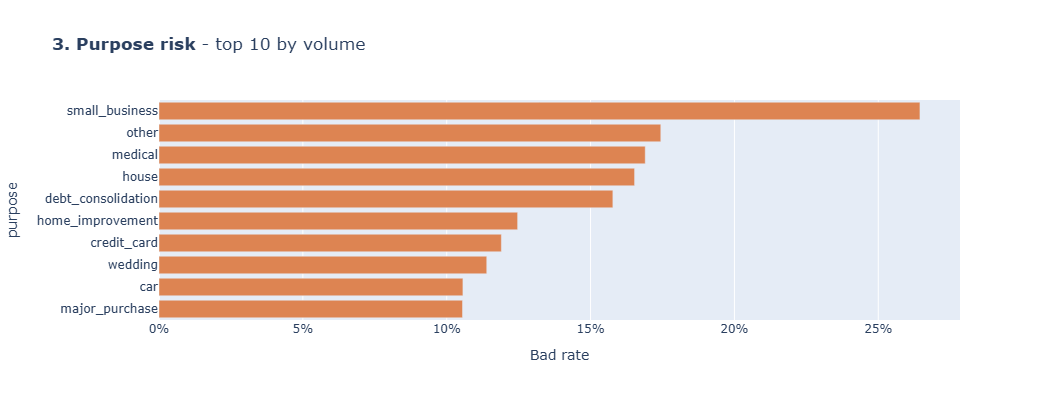

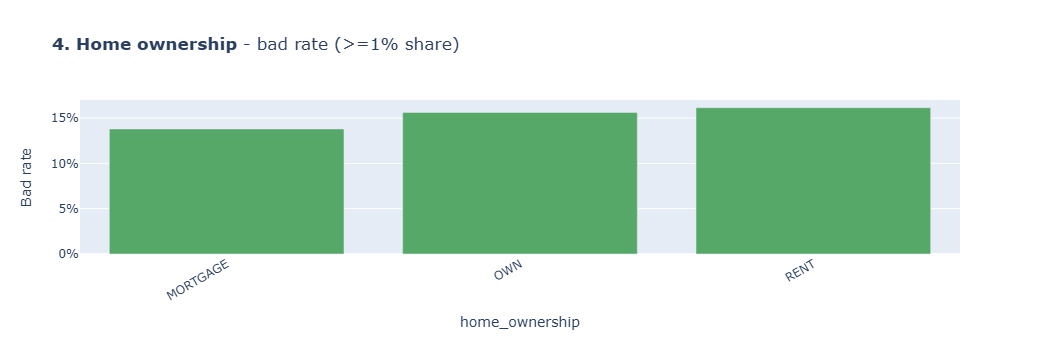

Eligible population: 118,066 | base bad rate 15.01%


,term,dti_band,pct,n,bad_rate,bad_lift
5,60_months,"(19.11, 34.99]",8.0,9398,0.2442,1.63
4,60_months,"(11.99, 19.11]",7.4,8758,0.2253,1.50
3,60_months,"(-0.001, 11.99]",6.1,7247,0.2071,1.38
2,36_months,"(19.11, 34.99]",25.3,29913,0.1528,1.02
1,36_months,"(11.99, 19.11]",26.0,30639,0.1273,0.85
0,36_months,"(-0.001, 11.99]",27.2,32111,0.1083,0.72


In [211]:
# 4.3. DASHBOARD PREVIEW - interactive Plotly panels (EDA level)
import plotly.express as px
from src.performance_window import bad_rate_by_vintage

BASE_BAD = df['target'].mean()

# ---- Panel 1: bad rate by vintage quarter ----
vint = bad_rate_by_vintage(df)
fig1 = px.line(vint, x='vintage', y='bad_rate', markers=True,
               labels={'bad_rate': 'Bad rate', 'vintage': 'Issue quarter'},
               title='<b>1. Vintage risk</b> - bad rate by issue quarter')
fig1.add_hline(y=BASE_BAD, line_dash='dash', line_color=C_RED,
               annotation_text=f'portfolio {BASE_BAD:.1%}')
fig1.update_layout(height=340, yaxis_tickformat='.0%', hovermode='x unified')
fig1.show()

# ---- Panel 2: term x DTI-tercile segment risk ----
_seg = df[['term', 'dti', 'target']].dropna().copy()
_seg['dti_band'] = pd.qcut(_seg['dti'], 3, duplicates='drop').astype(str)
_seg_prof = (_seg.groupby(['term', 'dti_band'], observed=True)['target']
               .agg(bad_rate='mean', n='size').reset_index()
               .assign(bad_lift=lambda d: d['bad_rate'] / BASE_BAD))
fig2 = px.bar(_seg_prof, x='dti_band', y='bad_rate', color='term',
              barmode='group',
              labels={'bad_rate': 'Bad rate', 'dti_band': 'DTI band (terciles)'},
              title='<b>2. Segment risk</b> - term x DTI band',
              color_discrete_sequence=[C_BLUE, C_ORANGE, C_GREEN, C_RED])
fig2.update_layout(height=340, yaxis_tickformat='.0%', hovermode='x unified')
fig2.show()

# ---- Panel 3: purpose risk (top 10 by volume) ----
_top = df['purpose'].value_counts().head(10).index
_purp = (df[df['purpose'].isin(_top)].groupby('purpose')['target']
           .agg(bad_rate='mean', n='size').reset_index()
           .sort_values('bad_rate'))
fig3 = px.bar(_purp, x='bad_rate', y='purpose', orientation='h',
              labels={'bad_rate': 'Bad rate'},
              title='<b>3. Purpose risk</b> - top 10 by volume',
              color_discrete_sequence=[C_ORANGE])
fig3.update_layout(height=400, yaxis={'categoryorder': 'total ascending'},
                   xaxis_tickformat='.0%')
fig3.show()

# ---- Panel 4: home ownership risk (>=1% share) ----
_home = (df.groupby('home_ownership')['target']
           .agg(bad_rate='mean', n='size').reset_index()
           .assign(share=lambda d: d['n'] / d['n'].sum())
           .query('share >= 0.01'))
fig4 = px.bar(_home, x='home_ownership', y='bad_rate',
              labels={'bad_rate': 'Bad rate'},
              title='<b>4. Home ownership</b> - bad rate (>=1% share)',
              color_discrete_sequence=[C_GREEN])
fig4.update_layout(height=340, xaxis_tickangle=-30, yaxis_tickformat='.0%')
fig4.show()

# ---- Panel 5: segment profile table (dashboard-style summary card) ----
summary = (_seg_prof.assign(pct=lambda d: (d['n'] / d['n'].sum() * 100).round(1),
                            bad_rate=lambda d: d['bad_rate'].round(4),
                            bad_lift=lambda d: d['bad_lift'].round(2))
           [['term', 'dti_band', 'pct', 'n', 'bad_rate', 'bad_lift']]
           .sort_values('bad_rate', ascending=False))
print(f'Eligible population: {len(df):,} | base bad rate {BASE_BAD:.2%}')
display(summary)